Patients with >=3 blood draws: 124
Strong increase: selected 4 patients
Strong decrease: selected 4 patients
Transient peak then drop: selected 4 patients
Rebound/fluctuating: selected 4 patients
Persistent high: selected 1 patients
Stable low: selected 3 patients

Final number of selected patients: 20

========== Final selected trajectory categories ==========
Strong increase             4
Strong decrease             4
Transient peak then drop    4
Rebound/fluctuating         4
Persistent high             1
Stable low                  3
Name: Trajectory_category, dtype: int64

========== Selected representative patients ==========
Patient_Identifier      Trajectory_category  n_draws  baseline_TF  final_TF  max_TF  range_TF     Histological_subtype Molecular_subtype
              AOFA          Strong increase        3        3.753    61.170  61.170    57.417                   Ductal         HR+/HER2-
              ANGM          Strong increase        6       19.200    51.690  59.130   

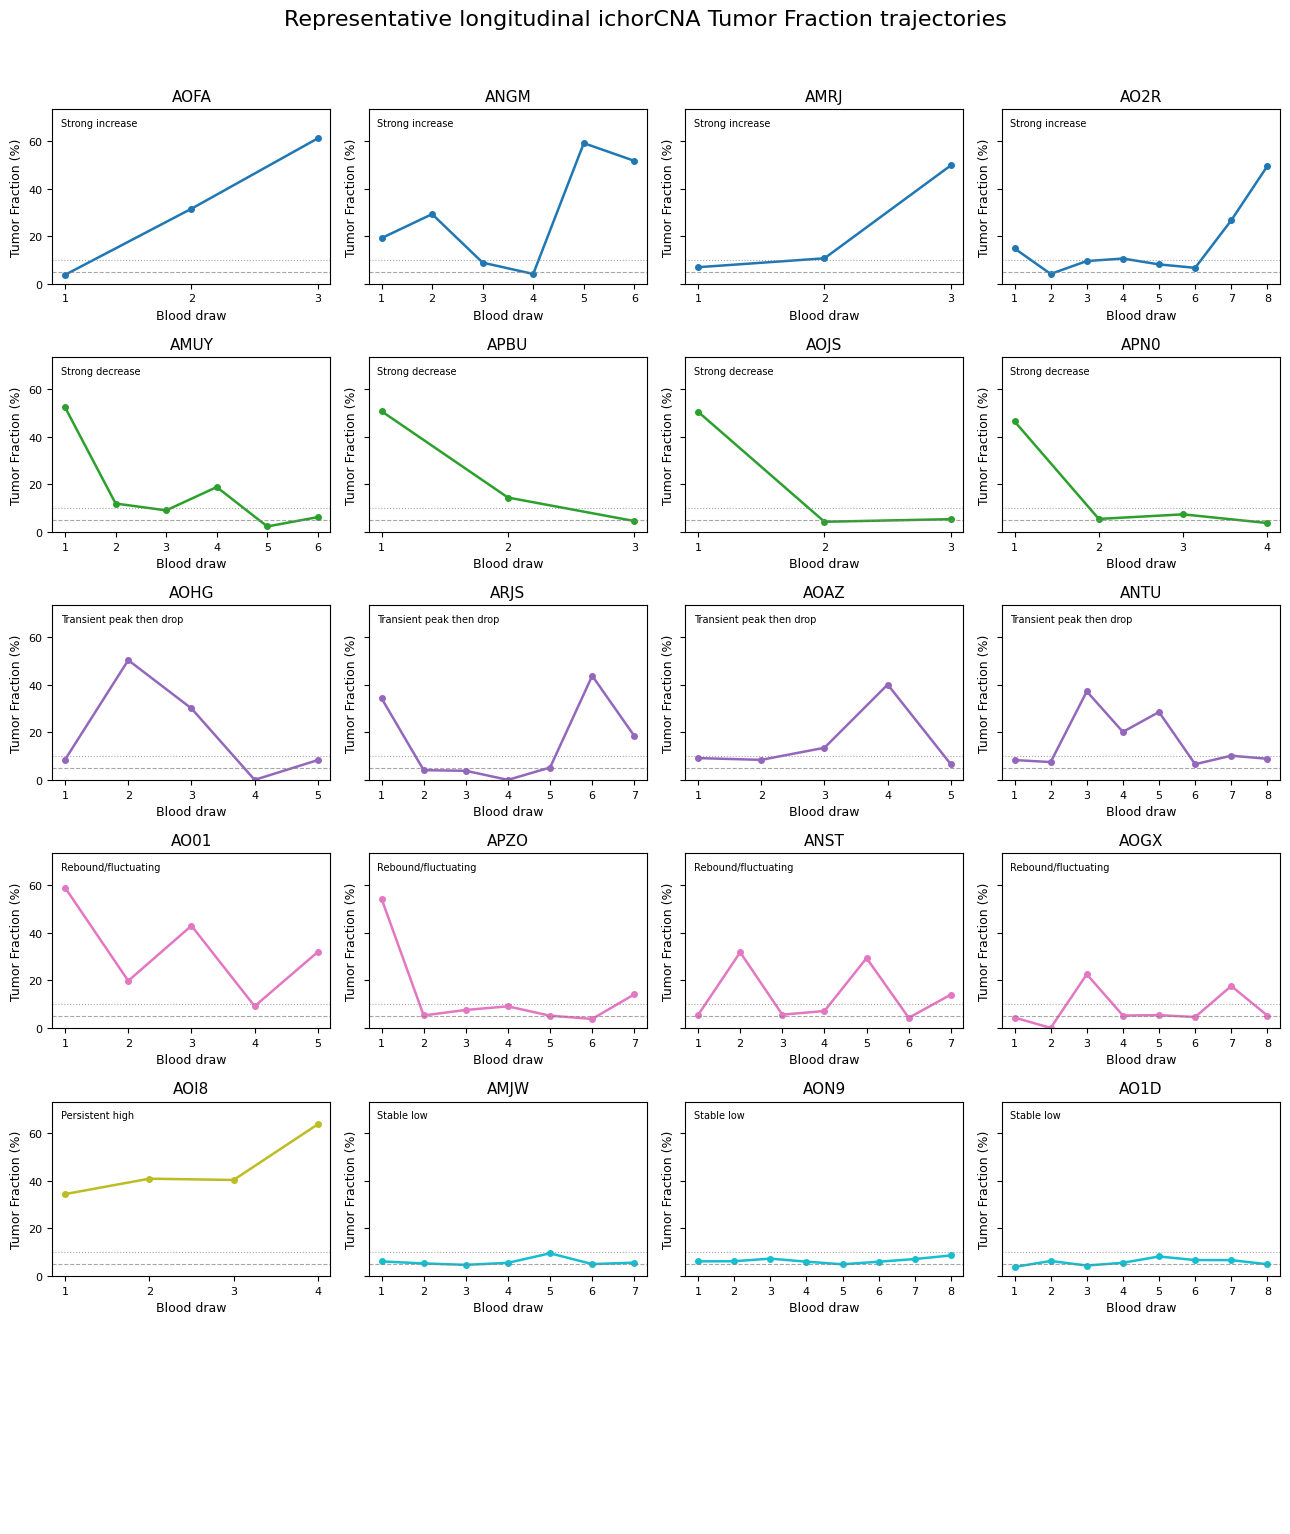


Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Representative_longitudinal_TF_trajectories.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Representative_longitudinal_TF_trajectories.pdf


In [1]:
# ============================================================
# Select and Plot Representative Longitudinal Tumor Fraction Trajectories
# from AURORA shWGS Patients Using ichorCNA Metrics
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math

# ============================================================
# Input file
# ============================================================
input_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.xlsx"
)

out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot"
)

out_dir.mkdir(parents=True, exist_ok=True)
# ============================================================
# Column names
# ============================================================
patient_col = "Patient_Identifier"
tf_col = "Tumor_Fraction"

histology_col = "Histological_subtype"
subtype_col = "Molecular_subtype"

subclonal_cols = [
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal"
]

date_col = None

# ============================================================
# Load data
# ============================================================
df = pd.read_excel(input_file)

# Keep original row order
df = df.reset_index().rename(columns={"index": "_original_row_order"})

# ============================================================
# Basic checks
# ============================================================
required_cols = [patient_col, tf_col] + subclonal_cols
missing_cols = [c for c in required_cols if c not in df.columns]

if len(missing_cols) > 0:
    raise ValueError(f"Missing required columns: {missing_cols}")

# ============================================================
# Clean patient column
# ============================================================
def clean_text(x):
    if pd.isna(x):
        return pd.NA
    
    x = str(x).strip()
    
    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing", "missing"]:
        return pd.NA
    
    return x

df[patient_col] = df[patient_col].apply(clean_text)

# Convert numeric columns
numeric_cols = [tf_col, "Ploidy"] + subclonal_cols

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without patient or tumor fraction
df = df.dropna(subset=[patient_col, tf_col]).copy()

# ============================================================
# Convert Tumor_Fraction to percentage if stored as decimal
# Example: 0.071 -> 7.1%
# ============================================================
if df[tf_col].quantile(0.99) <= 1.5:
    df["Tumor_Fraction_percent"] = df[tf_col] * 100
else:
    df["Tumor_Fraction_percent"] = df[tf_col]

# ============================================================
# Sort samples within patient
# ============================================================
if date_col is not None and date_col in df.columns:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.sort_values([patient_col, date_col, "_original_row_order"])
else:
    df = df.sort_values([patient_col, "_original_row_order"])

df["Blood_Draw_Order"] = df.groupby(patient_col).cumcount() + 1

# ============================================================
# Helper functions for longitudinal patterns
# ============================================================
def count_direction_changes(values, min_change=2.0):
    """
    Count direction changes in TF trajectory.
    Small changes below min_change percentage points are ignored.
    """
    values = np.asarray(values, dtype=float)
    diffs = np.diff(values)

    diffs = diffs[np.abs(diffs) >= min_change]

    if len(diffs) < 2:
        return 0

    signs = np.sign(diffs)
    return int(np.sum(signs[1:] != signs[:-1]))


def has_middle_peak(values):
    """
    True if the highest TF occurs at an internal blood draw,
    not first or last.
    """
    values = np.asarray(values, dtype=float)

    if len(values) < 3:
        return False

    peak_idx = int(np.argmax(values))
    return peak_idx not in [0, len(values) - 1]


def has_middle_trough(values):
    """
    True if the lowest TF occurs at an internal blood draw,
    suggesting rebound/fluctuation.
    """
    values = np.asarray(values, dtype=float)

    if len(values) < 3:
        return False

    trough_idx = int(np.argmin(values))
    return trough_idx not in [0, len(values) - 1]


def first_non_missing_value(x):
    x = pd.Series(x).dropna().astype(str)
    x = x[~x.isin(["Missing", "Unknown", "nan", "None", "NA", "N/A"])]

    if len(x) == 0:
        return "Unknown"

    return x.iloc[0]


# ============================================================
# Build patient-level longitudinal summary
# ============================================================
patient_rows = []

for pid, g in df.groupby(patient_col, sort=False):

    g = g.sort_values("Blood_Draw_Order")
    tf_values = g["Tumor_Fraction_percent"].to_numpy()

    # Use only patients with at least 3 blood draws
    if len(tf_values) < 3:
        continue

    row = {
        patient_col: pid,
        "n_draws": len(tf_values),
        "baseline_TF": tf_values[0],
        "final_TF": tf_values[-1],
        "min_TF": np.nanmin(tf_values),
        "max_TF": np.nanmax(tf_values),
        "mean_TF": np.nanmean(tf_values),
        "median_TF": np.nanmedian(tf_values),
        "range_TF": np.nanmax(tf_values) - np.nanmin(tf_values),
        "delta_final_baseline": tf_values[-1] - tf_values[0],
        "abs_delta_final_baseline": abs(tf_values[-1] - tf_values[0]),
        "direction_changes": count_direction_changes(tf_values),
        "middle_peak": has_middle_peak(tf_values),
        "middle_trough": has_middle_trough(tf_values),
    }

    if histology_col in g.columns:
        row[histology_col] = first_non_missing_value(g[histology_col])

    if subtype_col in g.columns:
        row[subtype_col] = first_non_missing_value(g[subtype_col])

    # Max subclonal metrics per patient
    for col in subclonal_cols:
        row[f"max_{col}"] = g[col].max()
        row[f"mean_{col}"] = g[col].mean()

    patient_rows.append(row)

patient_summary = pd.DataFrame(patient_rows)

print("Patients with >=3 blood draws:", patient_summary.shape[0])

# ============================================================
# Subclonal/CNA complexity score
# Higher score = higher ichorCNA-derived subclonal/CNA complexity
# ============================================================
z_cols = []

for col in subclonal_cols:
    max_col = f"max_{col}"
    z_col = f"z_{max_col}"

    mean_val = patient_summary[max_col].mean()
    std_val = patient_summary[max_col].std(ddof=0)

    if std_val == 0 or pd.isna(std_val):
        patient_summary[z_col] = 0
    else:
        patient_summary[z_col] = (
            patient_summary[max_col] - mean_val
        ) / std_val

    z_cols.append(z_col)

patient_summary["subclonal_complexity_score"] = patient_summary[z_cols].mean(axis=1)

# ============================================================
# Select representative patients using fixed categories
# ============================================================
selected_rows = []
used_patients = set()

def add_category(category_name, pool, n, sort_by, ascending):
    """
    Add top n patients from pool after excluding already selected patients.
    """
    global selected_rows, used_patients

    pool = pool.copy()
    pool = pool[~pool[patient_col].isin(used_patients)]

    if pool.shape[0] == 0:
        print(f"No patients found for category: {category_name}")
        return

    pool = pool.sort_values(sort_by, ascending=ascending)
    chosen = pool.head(n).copy()
    chosen["Trajectory_category"] = category_name

    for _, row in chosen.iterrows():
        used_patients.add(row[patient_col])
        selected_rows.append(row)

    print(f"{category_name}: selected {chosen.shape[0]} patients")


# ------------------------------------------------------------
# Category 1: Strong increase
# final TF - baseline TF >= 15 percentage points
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["delta_final_baseline"] >= 15) &
    (patient_summary["max_TF"] >= 10)
]

add_category(
    category_name="Strong increase",
    pool=pool,
    n=4,
    sort_by=["delta_final_baseline", "max_TF"],
    ascending=[False, False]
)

# ------------------------------------------------------------
# Category 2: Strong decrease
# baseline TF - final TF >= 15 percentage points
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["delta_final_baseline"] <= -15) &
    (patient_summary["baseline_TF"] >= 10)
]

add_category(
    category_name="Strong decrease",
    pool=pool,
    n=4,
    sort_by=["delta_final_baseline", "baseline_TF"],
    ascending=[True, False]
)

# ------------------------------------------------------------
# Category 3: Transient peak then drop
# internal peak, followed by >=15 percentage point drop
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["middle_peak"] == True) &
    ((patient_summary["max_TF"] - patient_summary["final_TF"]) >= 15) &
    (patient_summary["max_TF"] >= 10)
]

add_category(
    category_name="Transient peak then drop",
    pool=pool,
    n=4,
    sort_by=["range_TF", "max_TF"],
    ascending=[False, False]
)

# ------------------------------------------------------------
# Category 4: Rebound / fluctuating
# direction changes or internal trough, with large TF range
# ------------------------------------------------------------
pool = patient_summary[
    (
        (patient_summary["direction_changes"] >= 1) |
        (patient_summary["middle_trough"] == True)
    ) &
    (patient_summary["range_TF"] >= 15) &
    (patient_summary["max_TF"] >= 10)
]

add_category(
    category_name="Rebound/fluctuating",
    pool=pool,
    n=4,
    sort_by=["direction_changes", "range_TF", "max_TF"],
    ascending=[False, False, False]
)

# ------------------------------------------------------------
# Category 5: Persistent high TF
# Consistently elevated TF without a major low-TF dip
# ------------------------------------------------------------

# Ratio of lowest TF to median TF
# Helps exclude cases like 60 -> 20 -> 70
patient_summary["min_to_median_TF_ratio"] = (
    patient_summary["min_TF"] / patient_summary["median_TF"]
)

pool = patient_summary[
    (patient_summary["median_TF"] >= 30) &
    (patient_summary["min_TF"] >= 20) &
    (patient_summary["min_to_median_TF_ratio"] >= 0.70)
]

add_category(
    category_name="Persistent high",
    pool=pool,
    n=3,
    sort_by=["median_TF", "min_TF", "min_to_median_TF_ratio"],
    ascending=[False, False, False]
)

# ------------------------------------------------------------
# Category 6: Stable low TF
# persistently low tumor fraction
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["max_TF"] < 10) &
    (patient_summary["range_TF"] < 5)
]

add_category(
    category_name="Stable low",
    pool=pool,
    n=3,
    sort_by=["n_draws", "range_TF"],
    ascending=[False, True]
)

# ============================================================
# Convert selected rows to dataframe
# ============================================================
selected_patients = pd.DataFrame(selected_rows)

if selected_patients.empty:
    raise ValueError("No representative patients were selected. Please check category rules.")

# ============================================================
# Keep only predefined longitudinal TF trajectory categories
# No filler cases
# Plot limit: 5 rows x 4 columns = 20 panels
# ============================================================

allowed_categories = [
    "Strong increase",
    "Strong decrease",
    "Transient peak then drop",
    "Rebound/fluctuating",
    "Persistent high",
    "Stable low"
]

# Maximum number of cases to show per category
category_caps = {
    "Strong increase": 4,
    "Strong decrease": 4,
    "Transient peak then drop": 4,
    "Rebound/fluctuating": 4,
    "Persistent high": 4,
    "Stable low": 4
}

# Keep only selected biological categories
selected_patients = selected_patients[
    selected_patients["Trajectory_category"].isin(allowed_categories)
].copy()

# Set category order
selected_patients["Trajectory_category"] = pd.Categorical(
    selected_patients["Trajectory_category"],
    categories=allowed_categories,
    ordered=True
)

# Sort first by category and then by max TF
selected_patients = selected_patients.sort_values(
    ["Trajectory_category", "max_TF"],
    ascending=[True, False]
).reset_index(drop=True)

# Apply category-specific caps
selected_patients = (
    selected_patients
    .groupby("Trajectory_category", group_keys=False, observed=True)
    .apply(lambda x: x.head(category_caps[str(x.name)]))
    .reset_index(drop=True)
)

# Final hard cap at 24 panels
selected_patients = selected_patients.head(24).copy()

print("\nFinal number of selected patients:", selected_patients.shape[0])

print("\n========== Final selected trajectory categories ==========")
print(
    selected_patients["Trajectory_category"]
    .value_counts()
    .reindex(allowed_categories)
    .dropna()
)

# ============================================================
# Save selected patient summary
# ============================================================
selected_file = out_dir / "Selected_representative_patients.csv"

selected_patients.to_csv(selected_file, index=False)

print("\n========== Selected representative patients ==========")

cols_to_print = [
    patient_col,
    "Trajectory_category",
    "n_draws",
    "baseline_TF",
    "final_TF",
    "max_TF",
    "range_TF",
]

if histology_col in selected_patients.columns:
    cols_to_print.append(histology_col)

if subtype_col in selected_patients.columns:
    cols_to_print.append(subtype_col)

print(selected_patients[cols_to_print].to_string(index=False))

print(f"\nSaved selected patient table: {selected_file}")

# ============================================================
# Prepare plotting dataframe
# ============================================================
selected_ids = selected_patients[patient_col].tolist()

plot_df = df[df[patient_col].isin(selected_ids)].copy()

plot_df = plot_df.merge(
    selected_patients[[patient_col, "Trajectory_category"]],
    on=patient_col,
    how="left"
)

# Preserve selected order
plot_df[patient_col] = pd.Categorical(
    plot_df[patient_col],
    categories=selected_ids,
    ordered=True
)

plot_df = plot_df.sort_values([patient_col, "Blood_Draw_Order"])

# ============================================================
# Plot
# ============================================================
n_rows = 6
n_cols = 4
max_panels = n_rows * n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(13, 15),
    sharey=True
)

axes = np.array(axes).reshape(-1)

# Use one color per category
category_order = allowed_categories
cmap = plt.cm.get_cmap("tab10", len(category_order))

category_color = {
    cat: cmap(i)
    for i, cat in enumerate(category_order)
}

ymax = max(25, plot_df["Tumor_Fraction_percent"].max() * 1.15)

for i, pid in enumerate(selected_ids[:max_panels]):

    ax = axes[i]

    g = plot_df[plot_df[patient_col] == pid].sort_values("Blood_Draw_Order")

    category = g["Trajectory_category"].iloc[0]
    color = category_color[category]

    ax.plot(
        g["Blood_Draw_Order"],
        g["Tumor_Fraction_percent"],
        marker="o",
        linewidth=1.8,
        markersize=4,
        color=color
    )

    # Threshold lines
    ax.axhline(5, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)
    ax.axhline(10, linestyle=":", linewidth=0.8, color="gray", alpha=0.7)

    ax.set_title(f"{pid}", fontsize=11)

    ax.set_ylim(0, ymax)
    ax.set_xticks(g["Blood_Draw_Order"])

    ax.set_xlabel("Blood draw", fontsize=9)
    ax.set_ylabel("Tumor Fraction (%)", fontsize=9)

    ax.tick_params(axis="both", labelsize=8)

    # Category label inside each panel
    ax.text(
        0.03,
        0.95,
        category,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=7,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75)
    )

# Turn off unused panels if fewer than 20 patients
for j in range(len(selected_ids), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Representative longitudinal ichorCNA Tumor Fraction trajectories",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

# ============================================================
# Save figure
# ============================================================
png_file = out_dir / "Representative_longitudinal_TF_trajectories.png"
pdf_file = out_dir / "Representative_longitudinal_TF_trajectories.pdf"

plt.savefig(png_file, dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(pdf_file, bbox_inches="tight", facecolor="white")

plt.show()

print(f"\nSaved PNG: {png_file}")
print(f"Saved PDF: {pdf_file}")

In [4]:
# ============================================================
# Count total rows and unique patients per trajectory group
# ============================================================

print("\n========== Overall selected plotting dataset ==========")
print(f"Total blood-draw/sample rows: {plot_df.shape[0]}")
print(f"Total unique patients/cases: {plot_df[patient_col].nunique()}")

# One row = one blood draw/sample
# Unique cases = unique Patient_Identifier
trajectory_group_counts = (
    plot_df
    .groupby("Trajectory_category", observed=True)
    .agg(
        total_blood_draw_rows=(patient_col, "size"),
        unique_cases=(patient_col, "nunique")
    )
    .reset_index()
)

# Keep same category order
trajectory_group_counts["Trajectory_category"] = pd.Categorical(
    trajectory_group_counts["Trajectory_category"],
    categories=allowed_categories,
    ordered=True
)

trajectory_group_counts = trajectory_group_counts.sort_values("Trajectory_category")

print("\n========== Cases per trajectory category ==========")
print(trajectory_group_counts.to_string(index=False))



========== Overall selected plotting dataset ==========
Total blood-draw/sample rows: 115
Total unique patients/cases: 20

========== Cases per trajectory category ==========
     Trajectory_category  total_blood_draw_rows  unique_cases
         Strong increase                     20             4
         Strong decrease                     16             4
Transient peak then drop                     25             4
     Rebound/fluctuating                     27             4
         Persistent high                      4             1
              Stable low                     23             3


In [13]:
# ============================================================
# Full cohort: distribution of ALL unique cases across
# 6 longitudinal tumor-fraction trajectory categories
# blood draws >=3, could be evaluated for longitudinal trajectory
# ============================================================

print("\n========== Full cohort unique case count ==========")

total_unique_cases = df[patient_col].nunique()

print(f"Total unique cases/patients in full dataset: {total_unique_cases}")

# ------------------------------------------------------------
# Assign trajectory category to every patient in patient_summary
# ------------------------------------------------------------

def assign_trajectory_category(row):

    # 1. Strong increase
    if (
        row["delta_final_baseline"] >= 15 and
        row["max_TF"] >= 10
    ):
        return "Strong increase"

    # 2. Strong decrease
    if (
        row["delta_final_baseline"] <= -15 and
        row["baseline_TF"] >= 10
    ):
        return "Strong decrease"

    # 3. Transient peak then drop
    if (
        row["middle_peak"] == True and
        (row["max_TF"] - row["final_TF"]) >= 15 and
        row["max_TF"] >= 10
    ):
        return "Transient peak then drop"

    # 4. Rebound/fluctuating
    if (
        (
            row["direction_changes"] >= 1 or
            row["middle_trough"] == True
        ) and
        row["range_TF"] >= 15 and
        row["max_TF"] >= 10
    ):
        return "Rebound/fluctuating"

    # 5. Persistent high
    if (
        row["median_TF"] >= 30 and
        row["min_TF"] >= 20 and
        row["min_to_median_TF_ratio"] >= 0.70
    ):
        return "Persistent high"

    # 6. Stable low
    if (
        row["max_TF"] < 10 and
        row["range_TF"] < 5
    ):
        return "Stable low"

    return "Unclassified"


patient_summary["Trajectory_category_all_cases"] = patient_summary.apply(
    assign_trajectory_category,
    axis=1
)

# ------------------------------------------------------------
# Count unique cases per category
# ------------------------------------------------------------

trajectory_order = [
    "Strong increase",
    "Strong decrease",
    "Transient peak then drop",
    "Rebound/fluctuating",
    "Persistent high",
    "Stable low",
    "Unclassified"
]

patient_summary["Trajectory_category_all_cases"] = pd.Categorical(
    patient_summary["Trajectory_category_all_cases"],
    categories=trajectory_order,
    ordered=True
)

full_trajectory_counts = (
    patient_summary
    .groupby("Trajectory_category_all_cases", observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=("n_draws", "sum")
    )
    .reset_index()
)

full_trajectory_counts["percent_of_unique_cases"] = (
    full_trajectory_counts["unique_cases"] /
    full_trajectory_counts["unique_cases"].sum() *
    100
).round(1)

print("\n========== Distribution of unique cases across trajectory categories ==========")
print(full_trajectory_counts.to_string(index=False))

print("\n========== Sanity check ==========")
print(
    "Total classified + unclassified unique cases:",
    full_trajectory_counts["unique_cases"].sum()
)

# ============================================================
# Save all Unclassified cases with selected clinical/ichorCNA/fragment columns
# ============================================================

# Columns you want to keep from the original dataframe
cols_to_save = [
    "Collaborator_sample_id",
    "Patient_id",
    "Patient_Identifier",
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype",
    "Mean_coverage",
    "Tumor_Fraction",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

# ------------------------------------------------------------
# Get Patient_Identifiers classified as Unclassified
# ------------------------------------------------------------

unclassified_patient_ids = (
    patient_summary
    .loc[
        patient_summary["Trajectory_category_all_cases"].astype(str) == "Unclassified",
        patient_col
    ]
    .dropna()
    .unique()
)

print("\n========== Unclassified trajectory cases ==========")
print(f"Number of unique Unclassified patients: {len(unclassified_patient_ids)}")

# ------------------------------------------------------------
# Pull all original rows/blood draws for those patients
# ------------------------------------------------------------

unclassified_df = df[
    df[patient_col].isin(unclassified_patient_ids)
].copy()

print(f"Total blood-draw/sample rows from Unclassified patients: {unclassified_df.shape[0]}")

# ------------------------------------------------------------
# Check requested columns
# ------------------------------------------------------------

missing_cols = [c for c in cols_to_save if c not in unclassified_df.columns]
available_cols = [c for c in cols_to_save if c in unclassified_df.columns]

if len(missing_cols) > 0:
    print("\nWARNING: These requested columns were not found and will be skipped:")
    for c in missing_cols:
        print(f"  - {c}")

# Keep only available requested columns
unclassified_df_to_save = unclassified_df[available_cols].copy()

# Optional: sort nicely by patient and blood draw order
sort_cols = []

if "Patient_Identifier" in unclassified_df_to_save.columns:
    sort_cols.append("Patient_Identifier")

if "Blood_Draw_Order" in unclassified_df.columns:
    unclassified_df_to_save["Blood_Draw_Order"] = unclassified_df["Blood_Draw_Order"]
    sort_cols.append("Blood_Draw_Order")

if len(sort_cols) > 0:
    unclassified_df_to_save = unclassified_df_to_save.sort_values(sort_cols)

# ------------------------------------------------------------
# Save output
# ------------------------------------------------------------

unclassified_file = out_dir / "Unclassified_trajectory_cases_selected_columns.csv"

unclassified_df_to_save.to_csv(
    unclassified_file,
    index=False
)

print(f"\nSaved Unclassified cases table: {unclassified_file}")

# ------------------------------------------------------------
# Preview
# ------------------------------------------------------------

print("\n========== Preview of saved Unclassified cases ==========")
print(unclassified_df_to_save.head(10).to_string(index=False))


========== Full cohort unique case count ==========
Total unique cases/patients in full dataset: 262

========== Distribution of unique cases across trajectory categories ==========
Trajectory_category_all_cases  unique_cases  total_blood_draw_rows  percent_of_unique_cases
              Strong increase            15                     64                     12.1
              Strong decrease            24                    104                     19.4
     Transient peak then drop             9                     55                      7.3
          Rebound/fluctuating             3                      9                      2.4
              Persistent high             0                      0                      0.0
                   Stable low            20                     94                     16.1
                 Unclassified            53                    257                     42.7

========== Sanity check ==========
Total classified + unclassified unique cases:

In [14]:
# ============================================================
# Redesign trajectory groups for ONLY patients with >=3 blood draws
# This uses patient_summary, which already contains only eligible cases
# ============================================================

print("\n========== Redesigning trajectory groups for >=3 blood-draw cases only ==========")

# ------------------------------------------------------------
# Make sure min_to_median_TF_ratio exists
# ------------------------------------------------------------

patient_summary["min_to_median_TF_ratio"] = (
    patient_summary["min_TF"] / patient_summary["median_TF"]
)

# Avoid division issue when median_TF is zero
patient_summary.loc[
    patient_summary["median_TF"] == 0,
    "min_to_median_TF_ratio"
] = np.nan

# ------------------------------------------------------------
# New 4-group trajectory classification
# ------------------------------------------------------------

def assign_4group_longitudinal_trajectory(row):
    """
    Broader trajectory grouping for patients with >=3 blood draws.

    Goal:
    - Avoid sparse 6-category structure
    - Include all eligible longitudinal cases
    - Preserve biological interpretation
    """

    # Group 1: Stable low / low-burden
    # Tumor fraction remains low across the trajectory
    if (
        row["max_TF"] < 10 and
        row["range_TF"] < 5
    ):
        return "Stable low / low-burden"

    # Group 2: Increasing / progression-like
    # Final TF meaningfully higher than baseline
    if (
        row["max_TF"] >= 10 and
        row["delta_final_baseline"] >= 5
    ):
        return "Increasing / progression-like"

    # Group 3: Decreasing / response-like
    # Final TF meaningfully lower than baseline
    # OR patient had a high peak followed by drop
    if (
        row["max_TF"] >= 10 and
        (
            row["delta_final_baseline"] <= -5 or
            (row["max_TF"] - row["final_TF"]) >= 10
        )
    ):
        return "Decreasing / response-like"

    # Group 4: Variable / intermediate
    # Elevated or changing TF but not clearly directional
    return "Variable / intermediate"


patient_summary["Trajectory_4group"] = patient_summary.apply(
    assign_4group_longitudinal_trajectory,
    axis=1
)

# ------------------------------------------------------------
# Order categories
# ------------------------------------------------------------

trajectory_4group_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

patient_summary["Trajectory_4group"] = pd.Categorical(
    patient_summary["Trajectory_4group"],
    categories=trajectory_4group_order,
    ordered=True
)

# ------------------------------------------------------------
# Count distribution
# ------------------------------------------------------------

trajectory_4group_counts = (
    patient_summary
    .groupby("Trajectory_4group", observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=("n_draws", "sum"),
        median_n_draws=("n_draws", "median"),
        median_baseline_TF=("baseline_TF", "median"),
        median_final_TF=("final_TF", "median"),
        median_max_TF=("max_TF", "median"),
        median_delta_final_baseline=("delta_final_baseline", "median"),
        median_range_TF=("range_TF", "median")
    )
    .reset_index()
)

trajectory_4group_counts["percent_of_eligible_cases"] = (
    trajectory_4group_counts["unique_cases"] /
    trajectory_4group_counts["unique_cases"].sum() *
    100
).round(1)

print("\n========== 4-group trajectory distribution among >=3 blood-draw cases ==========")
print(trajectory_4group_counts.to_string(index=False))

print("\n========== Sanity check ==========")
print(f"Total trajectory-eligible unique cases: {patient_summary[patient_col].nunique()}")
print(f"Total cases assigned to 4 groups: {trajectory_4group_counts['unique_cases'].sum()}")

# ------------------------------------------------------------
# Save output
# ------------------------------------------------------------
correlation_out_dir = out_dir / "Correlation_Clinical_variables"
correlation_out_dir.mkdir(parents=True, exist_ok=True)

print(f"\nCorrelation analysis output folder:")
print(correlation_out_dir)


trajectory_4group_count_file = (
    correlation_out_dir / "Trajectory_4group_counts_ge3_blood_draws.csv"
)

trajectory_4group_patient_file = (
    correlation_out_dir / "Trajectory_4group_patient_level_ge3_blood_draws.csv"
)

trajectory_4group_counts.to_csv(
    trajectory_4group_count_file,
    index=False
)

patient_summary.to_csv(
    trajectory_4group_patient_file,
    index=False
)

print(f"\nSaved 4-group counts: {trajectory_4group_count_file}")
print(f"Saved patient-level 4-group table: {trajectory_4group_patient_file}")



========== Redesigning trajectory groups for >=3 blood-draw cases only ==========

========== 4-group trajectory distribution among >=3 blood-draw cases ==========
            Trajectory_4group  unique_cases  total_blood_draw_rows  median_n_draws  median_baseline_TF  median_final_TF  median_max_TF  median_delta_final_baseline  median_range_TF  percent_of_eligible_cases
      Stable low / low-burden            20                     94             4.0              5.5815            5.263          7.077                       0.9375           3.4390                       16.1
Increasing / progression-like            26                    117             4.0              6.5255           30.435         32.905                      17.2030          22.8385                       21.0
   Decreasing / response-like            43                    197             4.0             31.4300            6.180         34.670                     -15.8900          28.4560                       34.7
   

In [15]:
# ============================================================
# Analysis 1: Compare the 4 longitudinal trajectory groups with ichorCNA metrics, fragmentomic metrics, clinical variables, 
# receptor status, and molecular subtype using the ≥3 blood-draw cohort.
# Create sample-level Analysis 1 table
# All blood draws from >=3 blood-draw patients with 4-group trajectory label
# ============================================================

analysis1_sample_out_file = (
    correlation_out_dir / "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

# Get eligible patients from patient_summary
eligible_patient_ids = patient_summary[patient_col].dropna().unique()

# Keep all blood draws from these patients
analysis1_sample_df = df[
    df[patient_col].isin(eligible_patient_ids)
].copy()

# Merge trajectory group from patient_summary
analysis1_sample_df = analysis1_sample_df.merge(
    patient_summary[
        [
            patient_col,
            "Trajectory_4group",
            "n_draws",
            "baseline_TF",
            "final_TF",
            "min_TF",
            "max_TF",
            "mean_TF",
            "median_TF",
            "range_TF",
            "delta_final_baseline"
        ]
    ],
    on=patient_col,
    how="left"
)

# Columns to keep
analysis1_cols = [
    "Collaborator_sample_id",
    "Patient_id",
    "Patient_Identifier",
    "Blood_Draw_Order",
    "Trajectory_4group",
    "n_draws",

    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype",

    "Mean_coverage",
    "Tumor_Fraction",
    "Tumor_Fraction_percent",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",

    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650",

    "baseline_TF",
    "final_TF",
    "min_TF",
    "max_TF",
    "mean_TF",
    "median_TF",
    "range_TF",
    "delta_final_baseline"
]

available_cols = [c for c in analysis1_cols if c in analysis1_sample_df.columns]
missing_cols = [c for c in analysis1_cols if c not in analysis1_sample_df.columns]

if len(missing_cols) > 0:
    print("\nWARNING: These columns are missing and will be skipped:")
    for c in missing_cols:
        print(f"  - {c}")

analysis1_sample_df = analysis1_sample_df[available_cols].copy()

analysis1_sample_df = analysis1_sample_df.sort_values(
    ["Trajectory_4group", "Patient_Identifier", "Blood_Draw_Order"]
)

analysis1_sample_df.to_csv(
    analysis1_sample_out_file,
    index=False
)

print("\n========== Analysis 1 sample-level table saved ==========")
print(f"Saved file: {analysis1_sample_out_file}")
print(f"Total rows / blood draws: {analysis1_sample_df.shape[0]}")
print(f"Total unique patients: {analysis1_sample_df[patient_col].nunique()}")

print("\nTrajectory group distribution in sample-level file:")
print(
    analysis1_sample_df
    .groupby("Trajectory_4group", observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=(patient_col, "size")
    )
    .reset_index()
    .to_string(index=False)
)


========== Analysis 1 sample-level table saved ==========
Saved file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Total rows / blood draws: 583
Total unique patients: 124

Trajectory group distribution in sample-level file:
            Trajectory_4group  unique_cases  total_blood_draw_rows
      Stable low / low-burden            20                     94
Increasing / progression-like            26                    117
   Decreasing / response-like            43                    197
      Variable / intermediate            35                    175


In [16]:
# ============================================================
# Analysis 1 QC: Check missingness and group distribution
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

analysis1_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

correlation_out_dir = analysis1_file.parent

analysis1_df = pd.read_csv(analysis1_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

print("\n========== Analysis 1 input summary ==========")
print(f"Input file: {analysis1_file}")
print(f"Output folder: {correlation_out_dir}")
print(f"Total rows / blood draws: {analysis1_df.shape[0]}")
print(f"Total unique patients: {analysis1_df[patient_col].nunique()}")

print("\n========== Trajectory group distribution ==========")
print(
    analysis1_df
    .groupby(group_col, observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=(patient_col, "size")
    )
    .reset_index()
    .to_string(index=False)
)

# ============================================================
# Variables for Analysis 1
# ============================================================

clinical_vars = [
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

continuous_vars = [
    "Tumor_Fraction_percent",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

trajectory_summary_vars = [
    "baseline_TF",
    "final_TF",
    "min_TF",
    "max_TF",
    "mean_TF",
    "median_TF",
    "range_TF",
    "delta_final_baseline"
]

all_check_vars = clinical_vars + continuous_vars + trajectory_summary_vars

available_vars = [v for v in all_check_vars if v in analysis1_df.columns]
missing_vars = [v for v in all_check_vars if v not in analysis1_df.columns]

print("\n========== Missing columns check ==========")
if len(missing_vars) == 0:
    print("All requested variables are present.")
else:
    print("These variables are missing:")
    for v in missing_vars:
        print(f"  - {v}")

# ============================================================
# Missingness summary
# ============================================================

missingness_summary = []

for var in available_vars:
    missing_n = analysis1_df[var].isna().sum()
    missing_pct = missing_n / analysis1_df.shape[0] * 100

    missingness_summary.append({
        "variable": var,
        "missing_rows": missing_n,
        "missing_percent": round(missing_pct, 2),
        "nonmissing_rows": analysis1_df[var].notna().sum()
    })

missingness_df = pd.DataFrame(missingness_summary)

print("\n========== Missingness summary ==========")
print(missingness_df.to_string(index=False))


========== Analysis 1 input summary ==========
Input file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Output folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables
Total rows / blood draws: 583
Total unique patients: 124

========== Trajectory group distribution ==========
            Trajectory_4group  unique_cases  total_blood_draw_rows
   Decreasing / response-like            43                    197
Increasing / progression-like            26                    117
      Stable low / low-burden            20                     94
      Variable / intermediate            35                    175

========== Missing columns check ==========
All requested variables are present.

========== Missingness summary ==========
                    variable  missing_rows  missing_percent  nonmissing_rows
        H

In [17]:
# ============================================================
# Analysis 1A: Patient-level clinical/receptor association
# across 4 trajectory groups
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import chi2_contingency, fisher_exact

# ------------------------------------------------------------
# Input/output
# ------------------------------------------------------------

analysis1_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

correlation_out_dir = analysis1_file.parent

analysis1_df = pd.read_csv(analysis1_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

# ------------------------------------------------------------
# Variables to test at patient level
# ------------------------------------------------------------

clinical_vars = [
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

# ------------------------------------------------------------
# Create one-row-per-patient table
# ------------------------------------------------------------

patient_level_cols = [
    patient_col,
    group_col,
    "n_draws",
    "baseline_TF",
    "final_TF",
    "min_TF",
    "max_TF",
    "mean_TF",
    "median_TF",
    "range_TF",
    "delta_final_baseline"
] + clinical_vars

available_patient_cols = [
    c for c in patient_level_cols
    if c in analysis1_df.columns
]

patient_level_df = (
    analysis1_df[available_patient_cols]
    .drop_duplicates(subset=[patient_col])
    .copy()
)

print("\n========== Patient-level Analysis 1A input ==========")
print(f"Total unique patients: {patient_level_df[patient_col].nunique()}")
print(f"Total rows: {patient_level_df.shape[0]}")

print("\nTrajectory group distribution:")
print(
    patient_level_df
    .groupby(group_col, observed=False)
    .agg(unique_cases=(patient_col, "nunique"))
    .reset_index()
    .to_string(index=False)
)

# Save patient-level input
patient_level_file = correlation_out_dir / "Analysis1A_patient_level_clinical_input.csv"

patient_level_df.to_csv(
    patient_level_file,
    index=False
)

print(f"\nSaved patient-level clinical input: {patient_level_file}")

# ============================================================
# Clinical variable missingness at patient level
# ============================================================

patient_missingness = []

for var in clinical_vars:
    if var not in patient_level_df.columns:
        continue

    missing_n = patient_level_df[var].isna().sum()
    missing_pct = missing_n / patient_level_df.shape[0] * 100

    patient_missingness.append({
        "variable": var,
        "missing_patients": missing_n,
        "missing_percent": round(missing_pct, 2),
        "nonmissing_patients": patient_level_df[var].notna().sum()
    })

patient_missingness_df = pd.DataFrame(patient_missingness)

print("\n========== Patient-level clinical missingness ==========")
print(patient_missingness_df.to_string(index=False))

patient_missingness_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_missingness.csv"
)

patient_missingness_df.to_csv(
    patient_missingness_file,
    index=False
)

print(f"\nSaved patient-level missingness: {patient_missingness_file}")

# ============================================================
# Categorical association tests
# Trajectory_4group vs clinical/receptor variables
# ============================================================

association_results = []
all_contingency_tables = []

for var in clinical_vars:

    if var not in patient_level_df.columns:
        print(f"\nSkipping {var}: column not found.")
        continue

    tmp = patient_level_df[[patient_col, group_col, var]].copy()

    # Keep missing as explicit category for descriptive table
    tmp[var] = tmp[var].fillna("Missing").astype(str)

    contingency = pd.crosstab(
        tmp[group_col],
        tmp[var]
    )

    print(f"\n========== Contingency table: {group_col} vs {var} ==========")
    print(contingency.to_string())

    # Save long-format contingency table
    contingency_long = (
        contingency
        .reset_index()
        .melt(
            id_vars=group_col,
            var_name=var,
            value_name="n_patients"
        )
    )

    contingency_long["clinical_variable"] = var

    all_contingency_tables.append(contingency_long)

    # --------------------------------------------------------
    # Statistical test
    # Exclude missing for formal test
    # --------------------------------------------------------

    test_df = patient_level_df[[group_col, var]].dropna().copy()

    test_table = pd.crosstab(
        test_df[group_col],
        test_df[var]
    )

    n_used = int(test_table.values.sum())

    if test_table.shape[0] < 2 or test_table.shape[1] < 2:
        association_results.append({
            "clinical_variable": var,
            "test": "Not tested",
            "n_patients_used": n_used,
            "table_shape": f"{test_table.shape[0]}x{test_table.shape[1]}",
            "p_value": np.nan,
            "min_expected_count": np.nan,
            "note": "Only one category present after removing missing values"
        })
        continue

    # Chi-square test
    chi2, p, dof, expected = chi2_contingency(test_table)

    min_expected = expected.min()

    note = "Chi-square test"
    test_name = "Chi-square"

    # If 2x2 with low expected counts, use Fisher exact
    if test_table.shape == (2, 2) and min_expected < 5:
        oddsratio, fisher_p = fisher_exact(test_table)
        p = fisher_p
        test_name = "Fisher exact"
        note = "2x2 table with low expected counts"

    elif min_expected < 5:
        note = (
            "Chi-square used, but at least one expected count <5; "
            "interpret cautiously"
        )

    association_results.append({
        "clinical_variable": var,
        "test": test_name,
        "n_patients_used": n_used,
        "table_shape": f"{test_table.shape[0]}x{test_table.shape[1]}",
        "p_value": p,
        "min_expected_count": round(float(min_expected), 3),
        "note": note
    })

# Combine and save results
association_results_df = pd.DataFrame(association_results)

association_results_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_association_tests.csv"
)

association_results_df.to_csv(
    association_results_file,
    index=False
)

print("\n========== Patient-level clinical association test results ==========")
print(association_results_df.to_string(index=False))

print(f"\nSaved association test results: {association_results_file}")

# Save all contingency tables
if len(all_contingency_tables) > 0:
    all_contingency_df = pd.concat(
        all_contingency_tables,
        ignore_index=True
    )

    contingency_file = (
        correlation_out_dir / "Analysis1A_patient_level_clinical_contingency_tables.csv"
    )

    all_contingency_df.to_csv(
        contingency_file,
        index=False
    )

    print(f"Saved contingency tables: {contingency_file}")


========== Patient-level Analysis 1A input ==========
Total unique patients: 124
Total rows: 124

Trajectory group distribution:
            Trajectory_4group  unique_cases
   Decreasing / response-like            43
Increasing / progression-like            26
      Stable low / low-burden            20
      Variable / intermediate            35

Saved patient-level clinical input: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_patient_level_clinical_input.csv

========== Patient-level clinical missingness ==========
            variable  missing_patients  missing_percent  nonmissing_patients
Histological_subtype                 2             1.61                  122
           ER_Status                 1             0.81                  123
           PR_Status                 1             0.81                  123
         HER2_Status                 4             3.23                  120
   Molecular_subtype        

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Histological_subtype_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Histological_subtype_trajectory_group_100pct_stacked_barplot.pdf


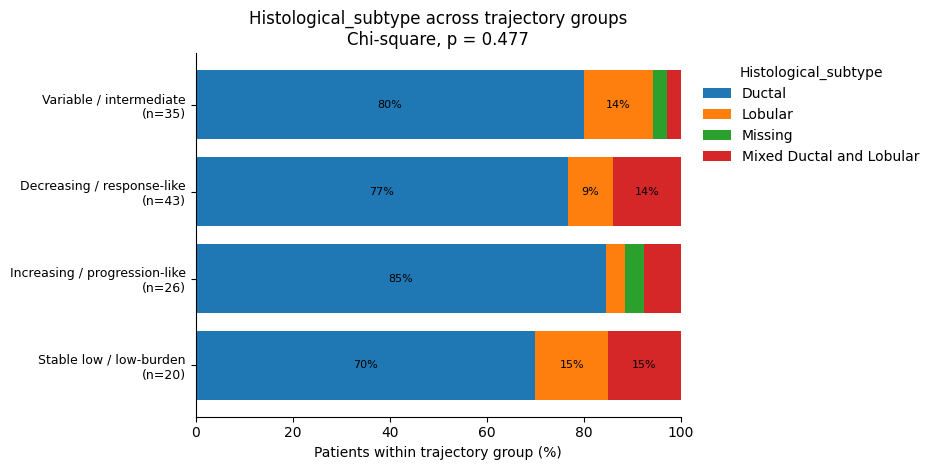

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/ER_Status_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/ER_Status_trajectory_group_100pct_stacked_barplot.pdf


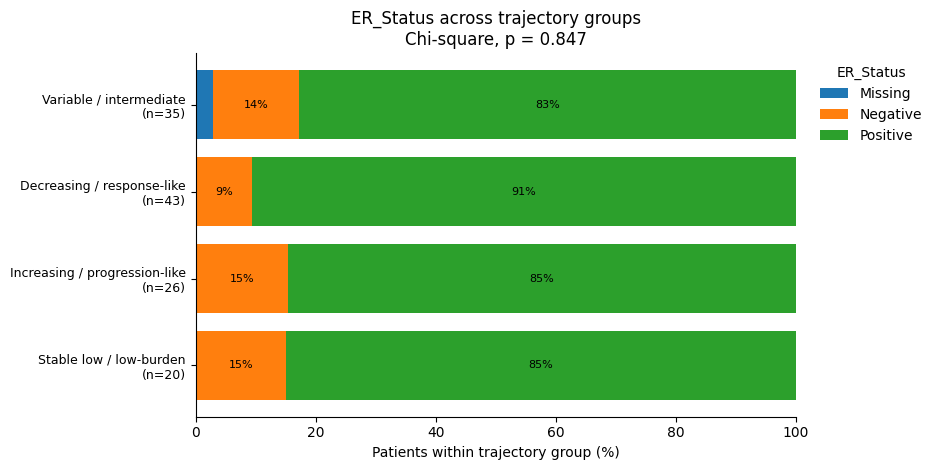

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/PR_Status_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/PR_Status_trajectory_group_100pct_stacked_barplot.pdf


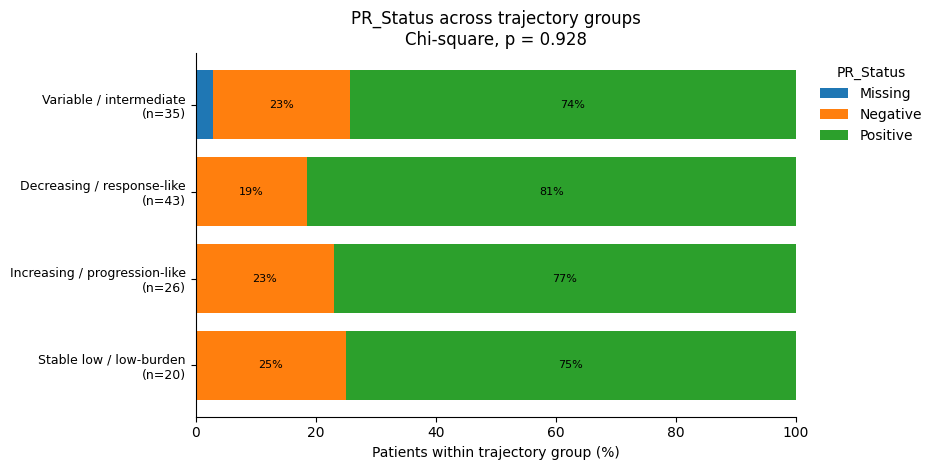

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/HER2_Status_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/HER2_Status_trajectory_group_100pct_stacked_barplot.pdf


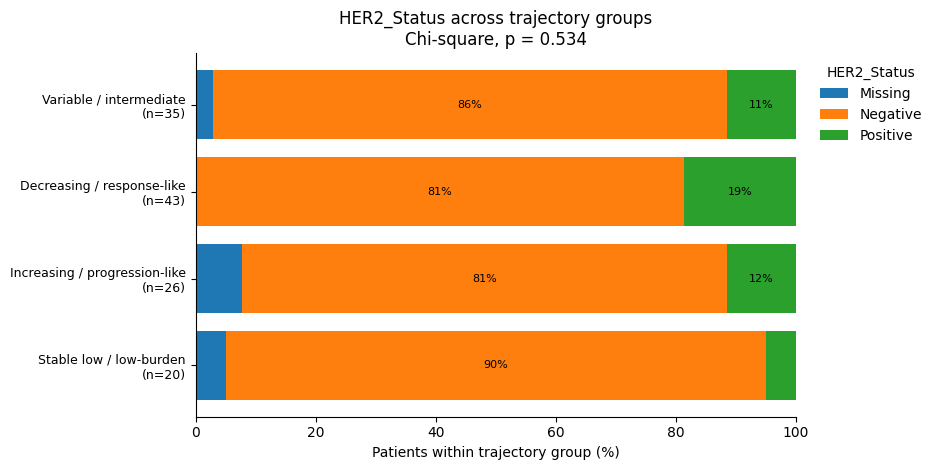

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Molecular_subtype_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Molecular_subtype_trajectory_group_100pct_stacked_barplot.pdf


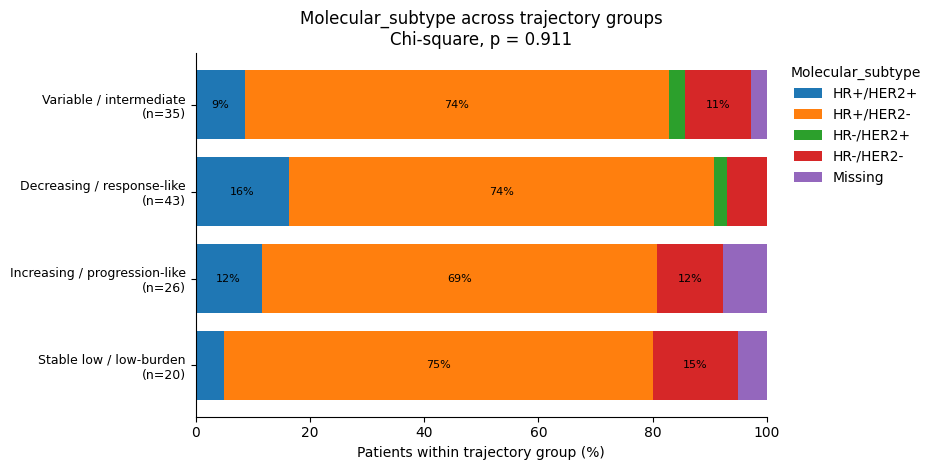


Saved count table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Analysis1A_clinical_composition_counts_long.csv
Saved percent table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Analysis1A_clinical_composition_percentages_long.csv

Saved combined PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Analysis1A_clinical_composition_all_variables_100pct_stacked_barplots.pdf


In [18]:
# ============================================================
# Analysis 1A visualization:
# Clinical/receptor composition across 4 trajectory groups
# 100% stacked bar plots
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

# ------------------------------------------------------------
# Input/output
# ------------------------------------------------------------

correlation_out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables"
)

patient_level_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_input.csv"
)

association_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_association_tests.csv"
)

plot_dir = correlation_out_dir / "Analysis1A_Clinical_composition_plots"
plot_dir.mkdir(parents=True, exist_ok=True)

patient_df = pd.read_csv(patient_level_file)
assoc_df = pd.read_csv(association_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

trajectory_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

clinical_vars = [
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

# ------------------------------------------------------------
# Clean group order
# ------------------------------------------------------------

patient_df[group_col] = pd.Categorical(
    patient_df[group_col],
    categories=trajectory_order,
    ordered=True
)

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def format_pvalue(p):
    if pd.isna(p):
        return "p = NA"
    elif p < 0.001:
        return "p < 0.001"
    else:
        return f"p = {p:.3f}"


def safe_filename(x):
    return (
        x.replace(" ", "_")
         .replace("/", "_")
         .replace("+", "plus")
         .replace("-", "_")
         .replace(".", "")
    )


def plot_clinical_composition(var, save_single=True):

    tmp = patient_df[[patient_col, group_col, var]].copy()

    # Keep missing visible in descriptive plot
    tmp[var] = tmp[var].fillna("Missing").astype(str)

    # Count table
    count_table = pd.crosstab(
        tmp[group_col],
        tmp[var]
    ).reindex(trajectory_order)

    # Remove empty columns if any
    count_table = count_table.loc[:, count_table.sum(axis=0) > 0]

    # Percent table
    percent_table = count_table.div(
        count_table.sum(axis=1),
        axis=0
    ) * 100

    # Get p-value from association results
    p_row = assoc_df[assoc_df["clinical_variable"] == var]

    if p_row.shape[0] > 0:
        p_text = format_pvalue(p_row["p_value"].iloc[0])
        test_text = str(p_row["test"].iloc[0])
    else:
        p_text = "p = NA"
        test_text = "test not found"

    # Group n labels
    group_n = count_table.sum(axis=1)

    y_labels = [
        f"{g}\n(n={int(group_n.loc[g])})"
        for g in count_table.index
    ]

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(9.5, 4.8))

    left = np.zeros(percent_table.shape[0])

    for category in percent_table.columns:
        values = percent_table[category].values

        bars = ax.barh(
            y=np.arange(percent_table.shape[0]),
            width=values,
            left=left,
            label=category
        )

        # Add labels inside segments if large enough
        for i, val in enumerate(values):
            if val >= 8:
                ax.text(
                    left[i] + val / 2,
                    i,
                    f"{val:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=8
                )

        left += values

    ax.set_yticks(np.arange(percent_table.shape[0]))
    ax.set_yticklabels(y_labels, fontsize=9)

    ax.set_xlim(0, 100)
    ax.set_xlabel("Patients within trajectory group (%)", fontsize=10)

    ax.set_title(
        f"{var} across trajectory groups\n{test_text}, {p_text}",
        fontsize=12
    )

    ax.legend(
        title=var,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    if save_single:
        png_file = plot_dir / f"{safe_filename(var)}_trajectory_group_100pct_stacked_barplot.png"
        pdf_file = plot_dir / f"{safe_filename(var)}_trajectory_group_100pct_stacked_barplot.pdf"

        plt.savefig(
            png_file,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        plt.savefig(
            pdf_file,
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Saved: {png_file}")
        print(f"Saved: {pdf_file}")

    return fig, count_table, percent_table


# ============================================================
# Generate one plot per clinical variable
# ============================================================

all_count_tables = []
all_percent_tables = []

for var in clinical_vars:

    if var not in patient_df.columns:
        print(f"Skipping {var}: column not found.")
        continue

    fig, count_table, percent_table = plot_clinical_composition(
        var,
        save_single=True
    )

    plt.show()

    # Save long-format count and percent tables
    count_long = (
        count_table
        .reset_index()
        .melt(
            id_vars=group_col,
            var_name="category",
            value_name="n_patients"
        )
    )
    count_long["clinical_variable"] = var

    percent_long = (
        percent_table
        .reset_index()
        .melt(
            id_vars=group_col,
            var_name="category",
            value_name="percent_patients"
        )
    )
    percent_long["clinical_variable"] = var

    all_count_tables.append(count_long)
    all_percent_tables.append(percent_long)


# ============================================================
# Save combined composition tables
# ============================================================

all_counts_df = pd.concat(all_count_tables, ignore_index=True)
all_percents_df = pd.concat(all_percent_tables, ignore_index=True)

count_out_file = plot_dir / "Analysis1A_clinical_composition_counts_long.csv"
percent_out_file = plot_dir / "Analysis1A_clinical_composition_percentages_long.csv"

all_counts_df.to_csv(count_out_file, index=False)
all_percents_df.to_csv(percent_out_file, index=False)

print(f"\nSaved count table: {count_out_file}")
print(f"Saved percent table: {percent_out_file}")


# ============================================================
# Save all plots together into one PDF
# ============================================================

combined_pdf_file = plot_dir / "Analysis1A_clinical_composition_all_variables_100pct_stacked_barplots.pdf"

with PdfPages(combined_pdf_file) as pdf:
    for var in clinical_vars:
        if var not in patient_df.columns:
            continue

        fig, _, _ = plot_clinical_composition(
            var,
            save_single=False
        )

        pdf.savefig(
            fig,
            bbox_inches="tight",
            facecolor="white"
        )

        plt.close(fig)

print(f"\nSaved combined PDF: {combined_pdf_file}")


========== Analysis 1B-1 ==========
Input file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Output folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots

========== Input summary ==========
Total blood draws: 583
Total unique patients: 124

Trajectory group distribution:
            Trajectory_4group  unique_patients  total_blood_draws
      Stable low / low-burden               20                 94
Increasing / progression-like               26                117
   Decreasing / response-like               43                197
      Variable / intermediate               35                175


/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/numpy/lib/nanfunctions.py:1117: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)



========== Patient-level feature summary saved ==========
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_patient_level_feature_median_summary.csv
Rows / patients: 124
Saved group-level descriptive summary: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_summary_by_group.csv

========== Running patient-level statistical tests ==========

========== Global Kruskal-Wallis results ==========
                     feature  n_total_patients_used  statistic  p_value  BH_q_value
      Tumor_Fraction_percent                    124  16.547685 0.000875    0.002626
                      Ploidy                    124   7.711651 0.052362    0.094252
           Subclone Fraction                    123   1.100855 0.776868    0.776868
      Frac. 

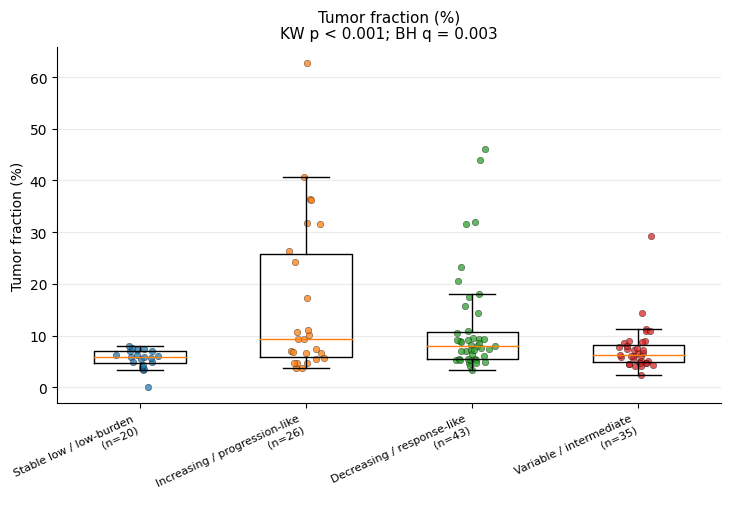

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Ploidy_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Ploidy_patient_median_by_TF_trajectory_group.pdf


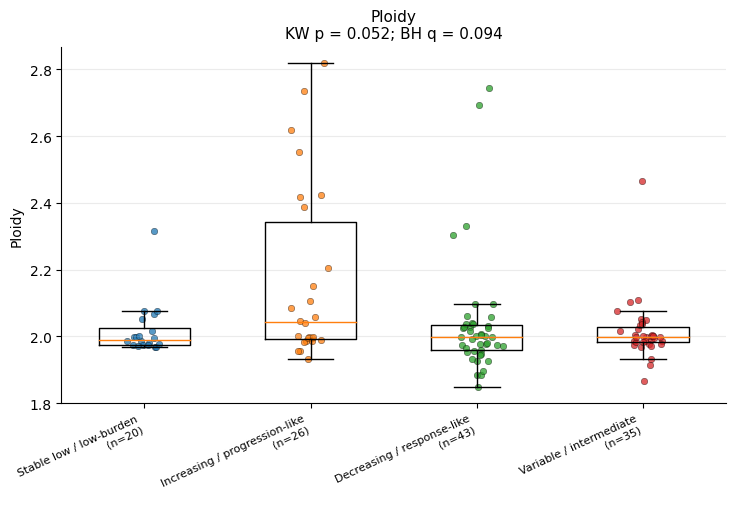

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Subclone_Fraction_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Subclone_Fraction_patient_median_by_TF_trajectory_group.pdf


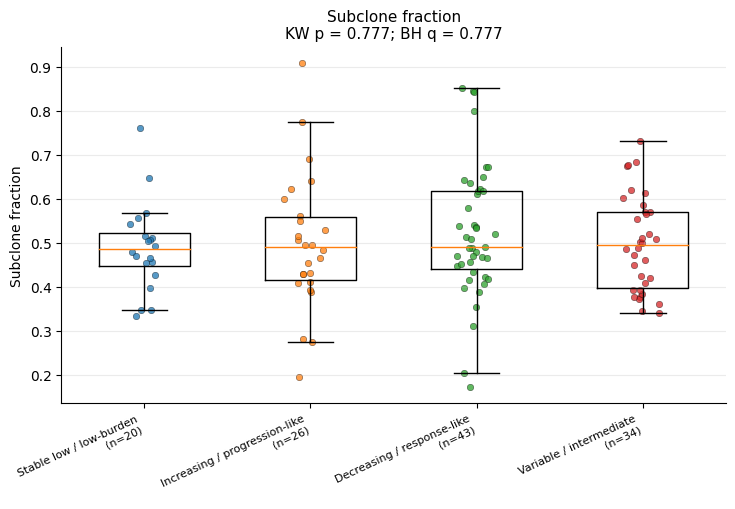

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Genome_Subclonal_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Genome_Subclonal_patient_median_by_TF_trajectory_group.pdf


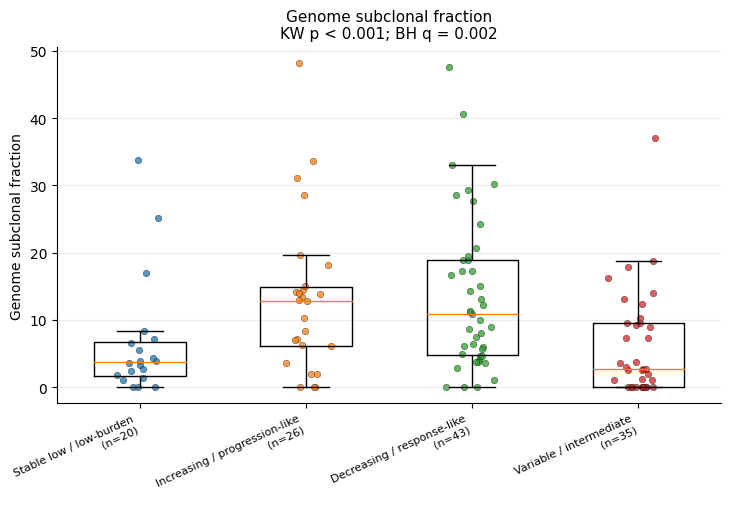

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_CNA_Subclonal_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_CNA_Subclonal_patient_median_by_TF_trajectory_group.pdf


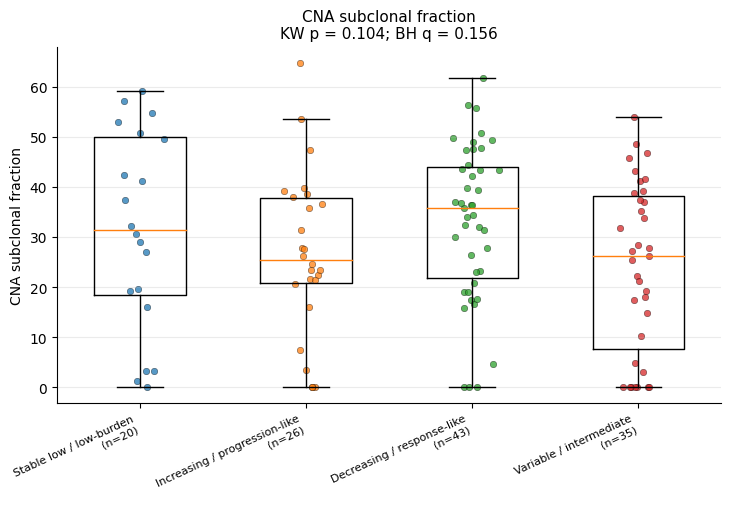

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Subnucleosomal_90_150_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Subnucleosomal_90_150_patient_median_by_TF_trajectory_group.pdf


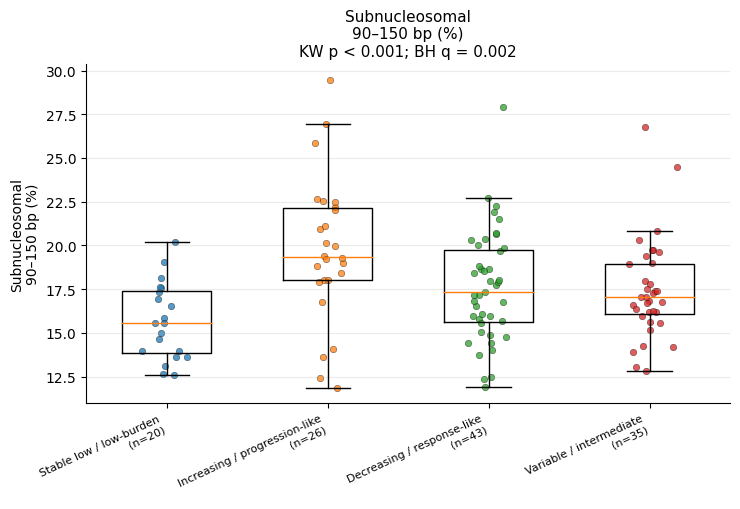

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Mononucleosomal_151_250_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Mononucleosomal_151_250_patient_median_by_TF_trajectory_group.pdf


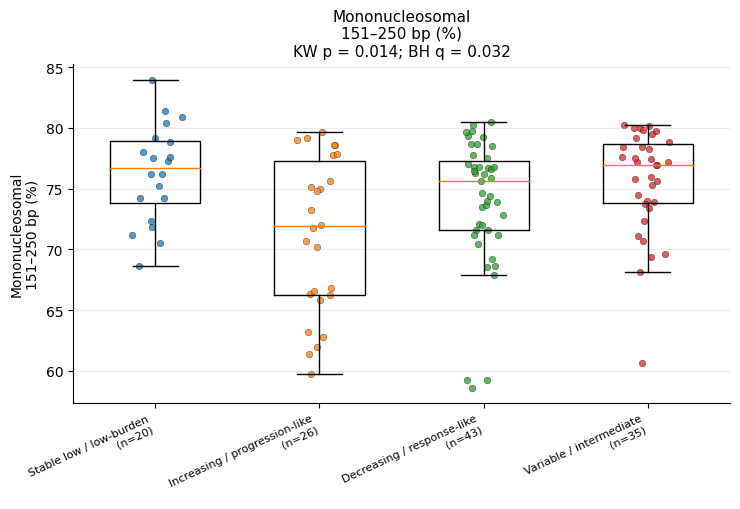

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Dinucleosomal_251_450_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Dinucleosomal_251_450_patient_median_by_TF_trajectory_group.pdf


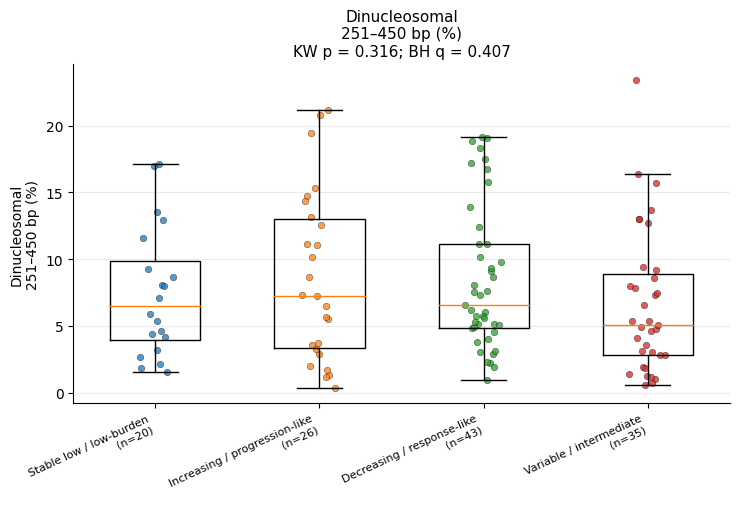

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Trinucleosomal_451_650_patient_median_by_TF_trajectory_group.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Frac_Trinucleosomal_451_650_patient_median_by_TF_trajectory_group.pdf


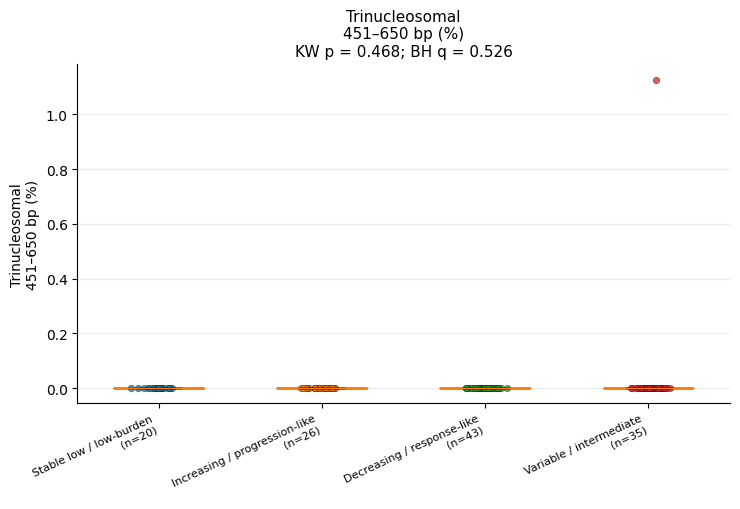


========== Saving combined 3x3 plot panel ==========


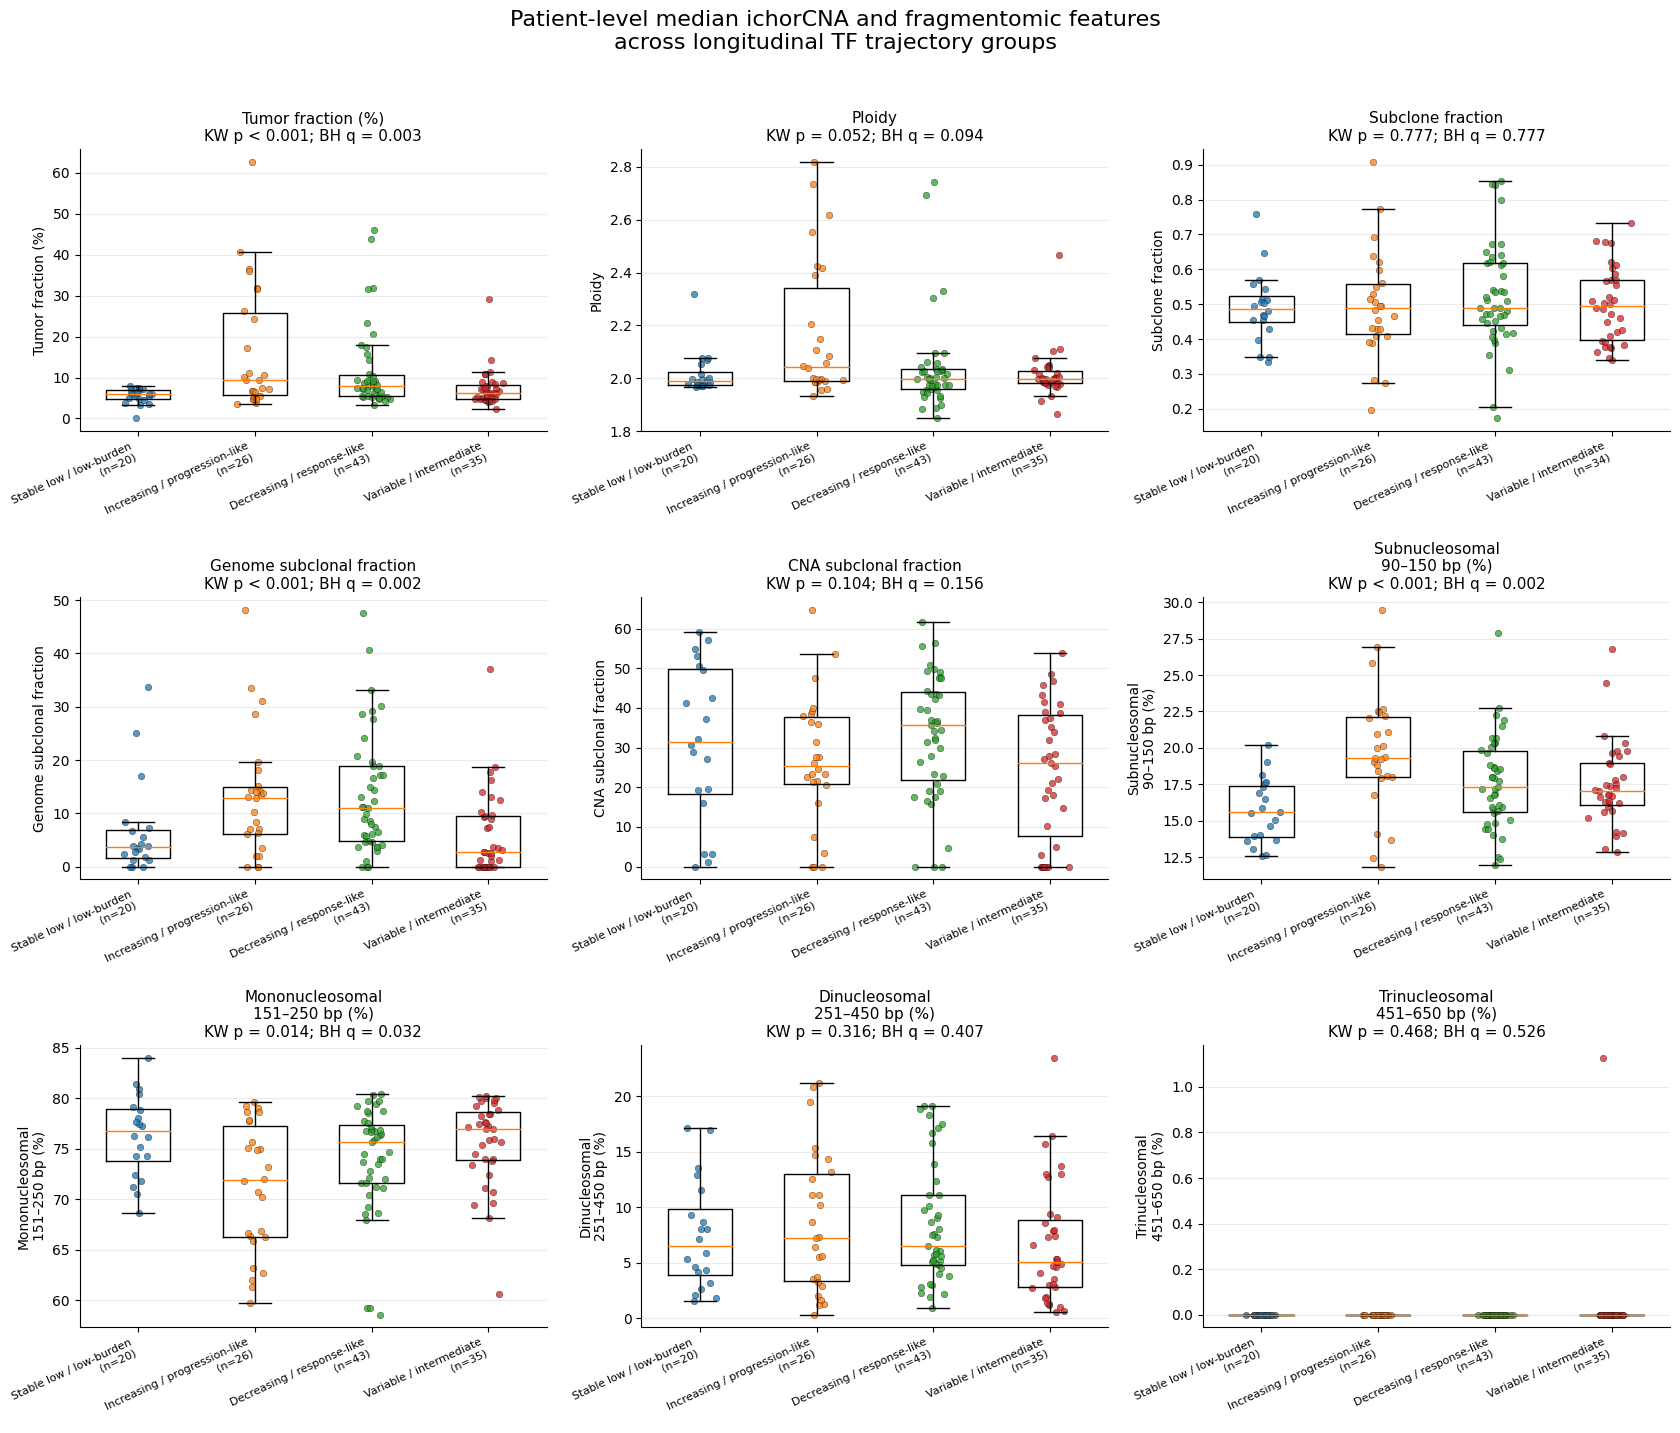


Saved combined PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Analysis1B_1_patient_level_median_features_by_TF_trajectory_3x3.png
Saved combined PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_1_patient_level_descriptive_plots/Analysis1B_1_patient_level_median_features_by_TF_trajectory_3x3.pdf

========== Analysis 1B-1 complete ==========
Patient-level table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_patient_level_feature_median_summary.csv
Summary table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Ana

In [2]:
# ============================================================
# Analysis 1B-1: Patient-level descriptive plots
# Feature medians across blood draws by 4 TF trajectory groups
#
# Input:
#   Analysis1 sample-level table:
#   583 blood draws from 124 patients with Trajectory_4group
#
# Output:
#   1. Patient-level median feature table
#   2. Group-level descriptive summary table
#   3. Individual box/jitter plots per feature
#   4. Combined 3x3 plot panel
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

# ============================================================
# Input / output
# ============================================================

analysis1_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables/"
    "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

correlation_out_dir = analysis1_file.parent

analysis1b_dir = correlation_out_dir / "Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory"
analysis1b_dir.mkdir(parents=True, exist_ok=True)

plot_dir = analysis1b_dir / "Analysis1B_1_patient_level_descriptive_plots"
plot_dir.mkdir(parents=True, exist_ok=True)

print("\n========== Analysis 1B-1 ==========")
print(f"Input file: {analysis1_file}")
print(f"Output folder: {plot_dir}")

# ============================================================
# Load data
# ============================================================

df = pd.read_csv(analysis1_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

trajectory_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

df[group_col] = pd.Categorical(
    df[group_col],
    categories=trajectory_order,
    ordered=True
)

print("\n========== Input summary ==========")
print(f"Total blood draws: {df.shape[0]}")
print(f"Total unique patients: {df[patient_col].nunique()}")

print("\nTrajectory group distribution:")
print(
    df
    .groupby(group_col, observed=False)
    .agg(
        unique_patients=(patient_col, "nunique"),
        total_blood_draws=(patient_col, "size")
    )
    .reset_index()
    .to_string(index=False)
)

# ============================================================
# Variables for patient-level descriptive analysis
# ============================================================

features = [
    "Tumor_Fraction_percent",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

feature_labels = {
    "Tumor_Fraction_percent": "Tumor fraction (%)",
    "Ploidy": "Ploidy",
    "Subclone Fraction": "Subclone fraction",
    "Frac. Genome Subclonal": "Genome subclonal fraction",
    "Frac. CNA Subclonal": "CNA subclonal fraction",
    "Frac_Subnucleosomal_90_150": "Subnucleosomal\n90–150 bp (%)",
    "Frac_Mononucleosomal_151_250": "Mononucleosomal\n151–250 bp (%)",
    "Frac_Dinucleosomal_251_450": "Dinucleosomal\n251–450 bp (%)",
    "Frac_Trinucleosomal_451_650": "Trinucleosomal\n451–650 bp (%)"
}

missing_features = [f for f in features if f not in df.columns]

if len(missing_features) > 0:
    raise ValueError(f"Missing required feature columns: {missing_features}")

# Convert numeric
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ============================================================
# Convert fraction-like fragmentomic columns to percentage for plotting
# Keep Tumor_Fraction_percent as already percent
# ============================================================

plot_feature_map = {}

for col in features:

    plot_col = col

    # Tumor_Fraction_percent is already expected as percent
    if col == "Tumor_Fraction_percent":
        plot_feature_map[col] = col
        continue

    # Convert only Frac_* columns if they look like proportions
    if col.startswith("Frac_") or col.startswith("Frac."):
        if df[col].dropna().shape[0] > 0 and df[col].dropna().quantile(0.99) <= 1.5:
            plot_col = col + "_percent_for_plot"
            df[plot_col] = df[col] * 100
        else:
            plot_col = col

    plot_feature_map[col] = plot_col

plot_features = list(plot_feature_map.values())

# ============================================================
# Create patient-level median summary table
# One row = one patient
# ============================================================

patient_level_rows = []

for pid, g in df.groupby(patient_col, sort=False):

    row = {
        patient_col: pid,
        group_col: g[group_col].dropna().iloc[0] if g[group_col].notna().any() else pd.NA,
        "n_blood_draws": g.shape[0]
    }

    for original_col, plot_col in plot_feature_map.items():
        row[f"median_{original_col}"] = g[plot_col].median(skipna=True)
        row[f"mean_{original_col}"] = g[plot_col].mean(skipna=True)
        row[f"min_{original_col}"] = g[plot_col].min(skipna=True)
        row[f"max_{original_col}"] = g[plot_col].max(skipna=True)

    patient_level_rows.append(row)

patient_level_df = pd.DataFrame(patient_level_rows)

patient_level_df[group_col] = pd.Categorical(
    patient_level_df[group_col],
    categories=trajectory_order,
    ordered=True
)

patient_level_df = patient_level_df.sort_values(
    [group_col, patient_col]
).reset_index(drop=True)

patient_level_file = (
    analysis1b_dir / "Analysis1B_patient_level_feature_median_summary.csv"
)

patient_level_df.to_csv(patient_level_file, index=False)

print("\n========== Patient-level feature summary saved ==========")
print(f"Saved: {patient_level_file}")
print(f"Rows / patients: {patient_level_df.shape[0]}")

# ============================================================
# Group-level descriptive summary
# ============================================================

summary_rows = []

for original_col in features:

    median_col = f"median_{original_col}"

    for group_name, g in patient_level_df.groupby(group_col, observed=False):

        vals = g[median_col].dropna()

        summary_rows.append({
            "feature": original_col,
            "feature_label": feature_labels.get(original_col, original_col),
            "trajectory_group": group_name,
            "n_patients": g[patient_col].nunique(),
            "n_nonmissing_patients": vals.shape[0],
            "mean": vals.mean(),
            "sd": vals.std(),
            "median": vals.median(),
            "q1": vals.quantile(0.25),
            "q3": vals.quantile(0.75),
            "min": vals.min(),
            "max": vals.max()
        })

summary_df = pd.DataFrame(summary_rows)

summary_file = (
    analysis1b_dir / "Analysis1B_1_patient_level_descriptive_summary_by_group.csv"
)

summary_df.to_csv(summary_file, index=False)

print(f"Saved group-level descriptive summary: {summary_file}")

# ============================================================
# Analysis 1B-1 statistics:
# Patient-level Kruskal-Wallis + pairwise Mann-Whitney tests
# using patient-level median feature values
# ============================================================

from scipy import stats
from statsmodels.stats.multitest import multipletests
from itertools import combinations

print("\n========== Running patient-level statistical tests ==========")

kruskal_rows = []
pairwise_rows = []

for original_col in features:

    median_col = f"median_{original_col}"

    test_df = patient_level_df[
        [patient_col, group_col, median_col]
    ].dropna().copy()

    # -------------------------
    # Global Kruskal-Wallis test
    # -------------------------
    group_values = []
    group_ns = {}

    for group_name in trajectory_order:
        vals = test_df.loc[
            test_df[group_col] == group_name,
            median_col
        ].dropna().values

        group_values.append(vals)
        group_ns[group_name] = len(vals)

    if all(len(vals) >= 2 for vals in group_values):
        kw_stat, kw_p = stats.kruskal(*group_values)
        kw_note = "Kruskal-Wallis test across 4 trajectory groups"
    else:
        kw_stat, kw_p = np.nan, np.nan
        kw_note = "Not enough nonmissing patients in one or more groups"

    kruskal_rows.append({
        "feature": original_col,
        "feature_label": feature_labels.get(original_col, original_col),
        "test": "Kruskal-Wallis",
        "n_total_patients_used": test_df[patient_col].nunique(),
        "n_stable_low": group_ns.get("Stable low / low-burden", 0),
        "n_increasing": group_ns.get("Increasing / progression-like", 0),
        "n_decreasing": group_ns.get("Decreasing / response-like", 0),
        "n_variable": group_ns.get("Variable / intermediate", 0),
        "statistic": kw_stat,
        "p_value": kw_p,
        "note": kw_note
    })

    # -------------------------
    # Pairwise Mann-Whitney tests
    # -------------------------
    for g1, g2 in combinations(trajectory_order, 2):

        vals1 = test_df.loc[
            test_df[group_col] == g1,
            median_col
        ].dropna().values

        vals2 = test_df.loc[
            test_df[group_col] == g2,
            median_col
        ].dropna().values

        if len(vals1) >= 2 and len(vals2) >= 2:
            u_stat, p_val = stats.mannwhitneyu(
                vals1,
                vals2,
                alternative="two-sided"
            )

            note = "Mann-Whitney U test"
        else:
            u_stat, p_val = np.nan, np.nan
            note = "Not enough nonmissing patients"

        pairwise_rows.append({
            "feature": original_col,
            "feature_label": feature_labels.get(original_col, original_col),
            "group_1": g1,
            "group_2": g2,
            "n_group_1": len(vals1),
            "n_group_2": len(vals2),
            "median_group_1": np.nanmedian(vals1) if len(vals1) > 0 else np.nan,
            "median_group_2": np.nanmedian(vals2) if len(vals2) > 0 else np.nan,
            "median_difference_group1_minus_group2": (
                np.nanmedian(vals1) - np.nanmedian(vals2)
                if len(vals1) > 0 and len(vals2) > 0
                else np.nan
            ),
            "statistic": u_stat,
            "p_value": p_val,
            "note": note
        })

kruskal_df = pd.DataFrame(kruskal_rows)
pairwise_df = pd.DataFrame(pairwise_rows)

# BH correction across global tests
mask = kruskal_df["p_value"].notna()

if mask.sum() > 0:
    kruskal_df.loc[mask, "BH_q_value"] = multipletests(
        kruskal_df.loc[mask, "p_value"],
        method="fdr_bh"
    )[1]

# BH correction across all pairwise tests
mask = pairwise_df["p_value"].notna()

if mask.sum() > 0:
    pairwise_df.loc[mask, "BH_q_value"] = multipletests(
        pairwise_df.loc[mask, "p_value"],
        method="fdr_bh"
    )[1]

# Save statistical outputs
kruskal_file = (
    analysis1b_dir /
    "Analysis1B_1_patient_level_median_Kruskal_Wallis_tests.csv"
)

pairwise_file = (
    analysis1b_dir /
    "Analysis1B_1_patient_level_median_pairwise_MannWhitney_tests.csv"
)

kruskal_df.to_csv(kruskal_file, index=False)
pairwise_df.to_csv(pairwise_file, index=False)

print("\n========== Global Kruskal-Wallis results ==========")
print(
    kruskal_df[
        [
            "feature",
            "n_total_patients_used",
            "statistic",
            "p_value",
            "BH_q_value"
        ]
    ].to_string(index=False)
)

print(f"\nSaved Kruskal-Wallis results: {kruskal_file}")
print(f"Saved pairwise Mann-Whitney results: {pairwise_file}")

# ============================================================
# Helper functions for plotting
# ============================================================

def safe_filename(x):
    x = str(x)
    x = x.replace("/", "_")
    x = x.replace("+", "plus")
    x = re.sub(r"[^A-Za-z0-9_]+", "_", x)
    x = re.sub(r"_+", "_", x)
    return x.strip("_")


def plot_single_feature(original_col, ax=None, save_individual=True):

    median_col = f"median_{original_col}"

    plot_df = patient_level_df[
        [patient_col, group_col, median_col]
    ].dropna().copy()

    if ax is None:
        fig, ax = plt.subplots(figsize=(7.5, 5.2))
    else:
        fig = ax.figure

    data = []
    labels = []

    for group_name in trajectory_order:
        vals = plot_df.loc[
            plot_df[group_col] == group_name,
            median_col
        ].dropna().values

        data.append(vals)
        labels.append(
            f"{group_name}\n(n={len(vals)})"
        )

    # Boxplot
    ax.boxplot(
        data,
        showfliers=False,
        widths=0.55
    )

    # Jittered patient points
    for i, vals in enumerate(data, start=1):
        if len(vals) == 0:
            continue

        x = np.random.normal(i, 0.06, size=len(vals))

        ax.scatter(
            x,
            vals,
            s=22,
            alpha=0.75,
            edgecolor="black",
            linewidth=0.3
        )

    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=8)

    ax.set_ylabel(
        feature_labels.get(original_col, original_col),
        fontsize=10
    )
    # Add global Kruskal-Wallis p-value to title
    kw_row = kruskal_df[kruskal_df["feature"] == original_col]

    if kw_row.shape[0] > 0:
        p_val = kw_row["p_value"].iloc[0]
        q_val = kw_row["BH_q_value"].iloc[0] if "BH_q_value" in kw_row.columns else np.nan

        if pd.isna(p_val):
            p_text = "KW p = NA"
        elif p_val < 0.001:
            p_text = "KW p < 0.001"
        else:
            p_text = f"KW p = {p_val:.3f}"

        if pd.isna(q_val):
            q_text = "BH q = NA"
        elif q_val < 0.001:
            q_text = "BH q < 0.001"
        else:
            q_text = f"BH q = {q_val:.3f}"

        title_text = (
            f"{feature_labels.get(original_col, original_col)}\n"
            f"{p_text}; {q_text}"
        )
    else:
        title_text = feature_labels.get(original_col, original_col)

    ax.set_title(
        title_text,
        fontsize=11
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(axis="y", alpha=0.25)

    if save_individual:
        plt.tight_layout()

        png_file = (
            plot_dir /
            f"{safe_filename(original_col)}_patient_median_by_TF_trajectory_group.png"
        )

        pdf_file = (
            plot_dir /
            f"{safe_filename(original_col)}_patient_median_by_TF_trajectory_group.pdf"
        )

        fig.savefig(
            png_file,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        fig.savefig(
            pdf_file,
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Saved: {png_file}")
        print(f"Saved: {pdf_file}")

    return fig, ax

# ============================================================
# Save individual plots
# ============================================================

print("\n========== Saving individual patient-level plots ==========")

for feature in features:
    fig, ax = plot_single_feature(
        original_col=feature,
        ax=None,
        save_individual=True
    )
    plt.show()

# ============================================================
# Save combined 3x3 panel
# ============================================================

print("\n========== Saving combined 3x3 plot panel ==========")

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(17, 14)
)

axes = axes.reshape(-1)

for ax, feature in zip(axes, features):
    plot_single_feature(
        original_col=feature,
        ax=ax,
        save_individual=False
    )

# Turn off any unused axes
for j in range(len(features), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Patient-level median ichorCNA and fragmentomic features\n"
    "across longitudinal TF trajectory groups",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

combined_png = (
    plot_dir /
    "Analysis1B_1_patient_level_median_features_by_TF_trajectory_3x3.png"
)

combined_pdf = (
    plot_dir /
    "Analysis1B_1_patient_level_median_features_by_TF_trajectory_3x3.pdf"
)

fig.savefig(
    combined_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    combined_pdf,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"\nSaved combined PNG: {combined_png}")
print(f"Saved combined PDF: {combined_pdf}")

print("\n========== Analysis 1B-1 complete ==========")
print(f"Patient-level table: {patient_level_file}")
print(f"Summary table: {summary_file}")
print(f"Plots saved in: {plot_dir}")


========== Analysis 1B-2 ==========
Input file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Output folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_2_sample_level_GEE_repeated_measures

========== Input summary ==========
Total blood-draw rows: 583
Unique patients: 124

Trajectory group distribution:
            Trajectory_4group  n_patients  n_blood_draws
      Stable low / low-burden          20             94
Increasing / progression-like          26            117
   Decreasing / response-like          43            197
      Variable / intermediate          35            175

========== Feature model column map ==========
                  source_col                          model_col                  feature_label            feature_type

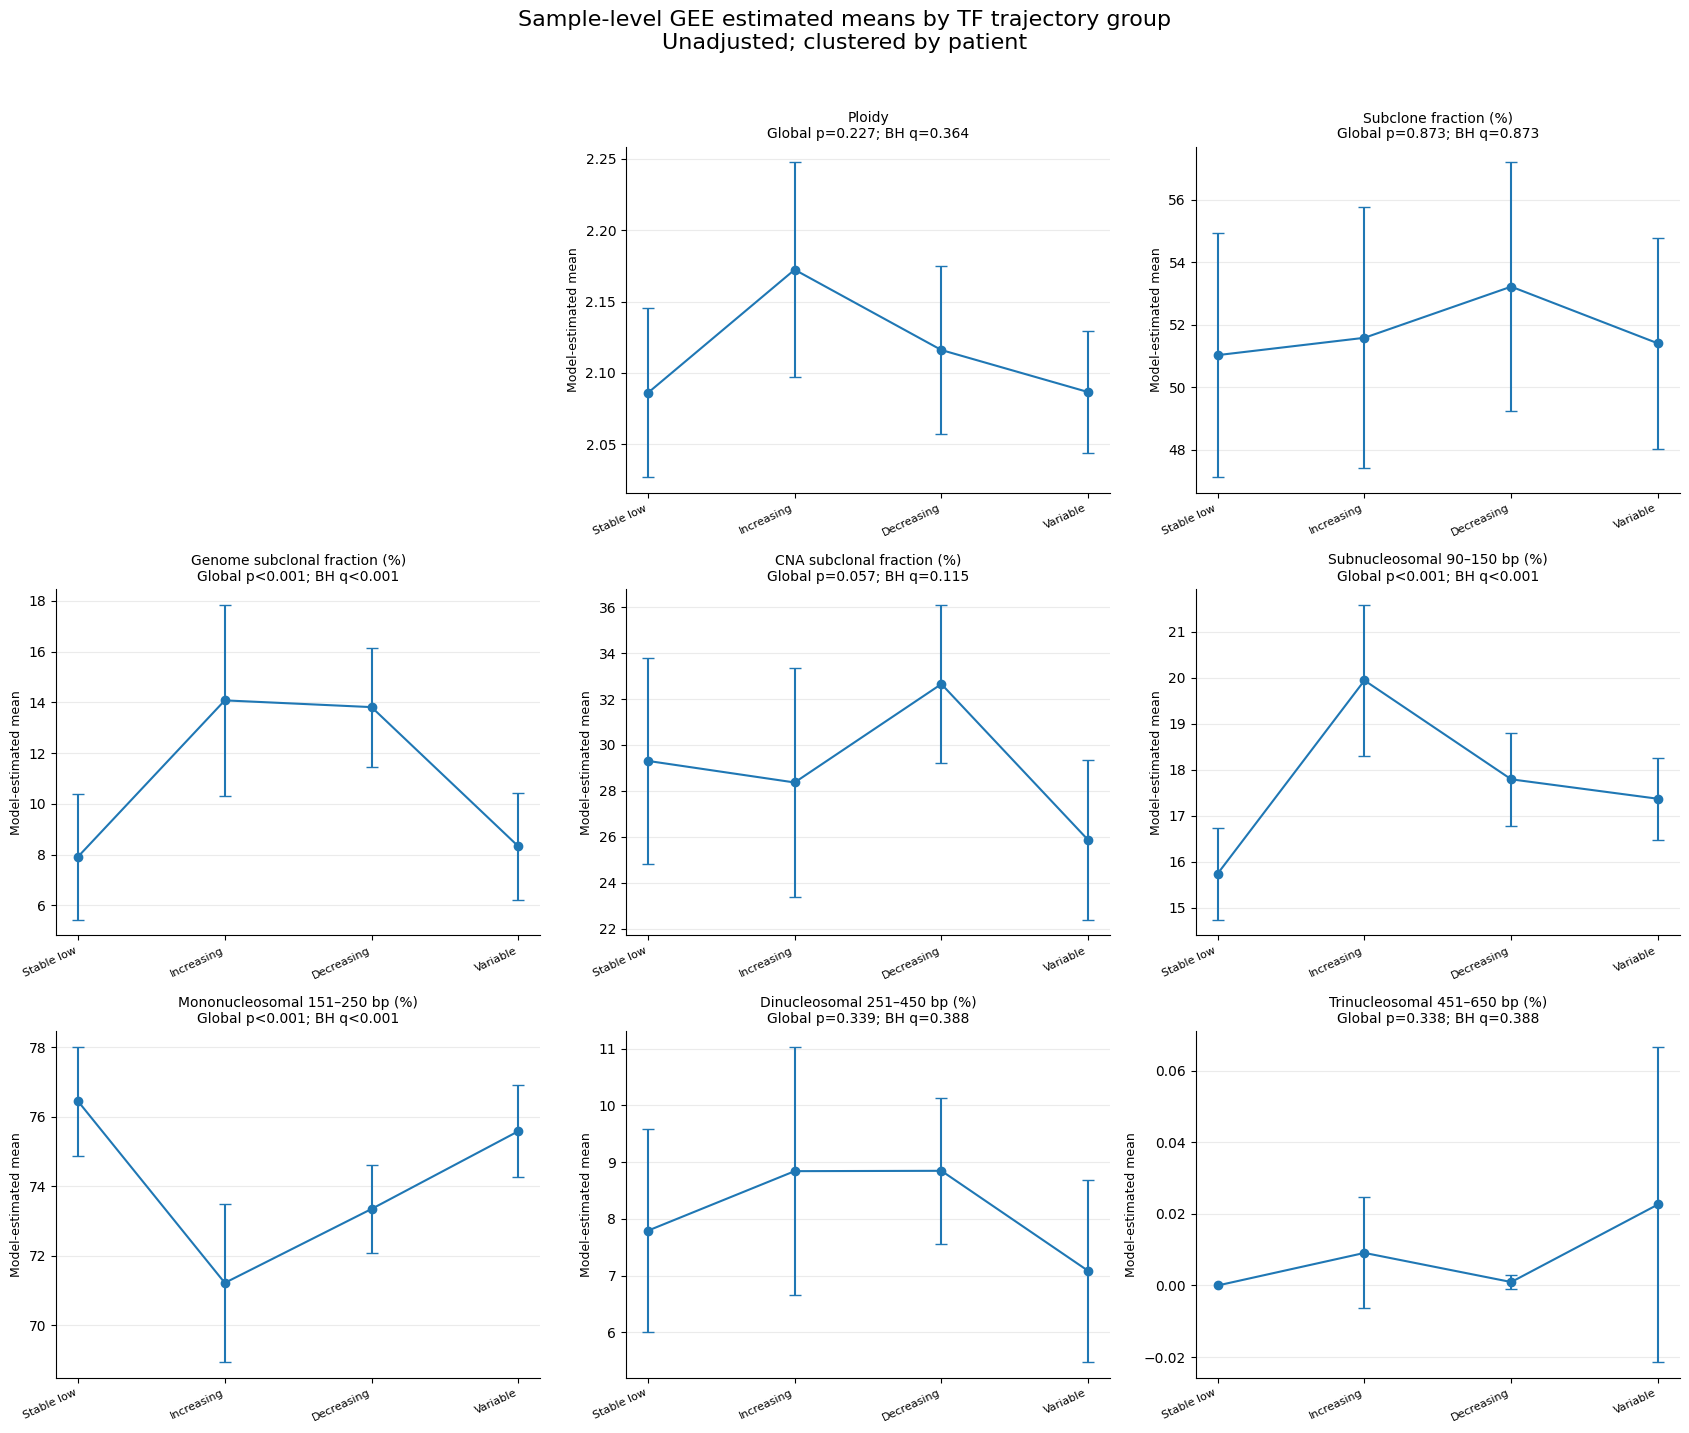

Saved plot PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_2_sample_level_GEE_repeated_measures/plots/Analysis1B_2_GEE_unadjusted_estimated_means_by_trajectory_group.png
Saved plot PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_2_sample_level_GEE_repeated_measures/plots/Analysis1B_2_GEE_unadjusted_estimated_means_by_trajectory_group.pdf


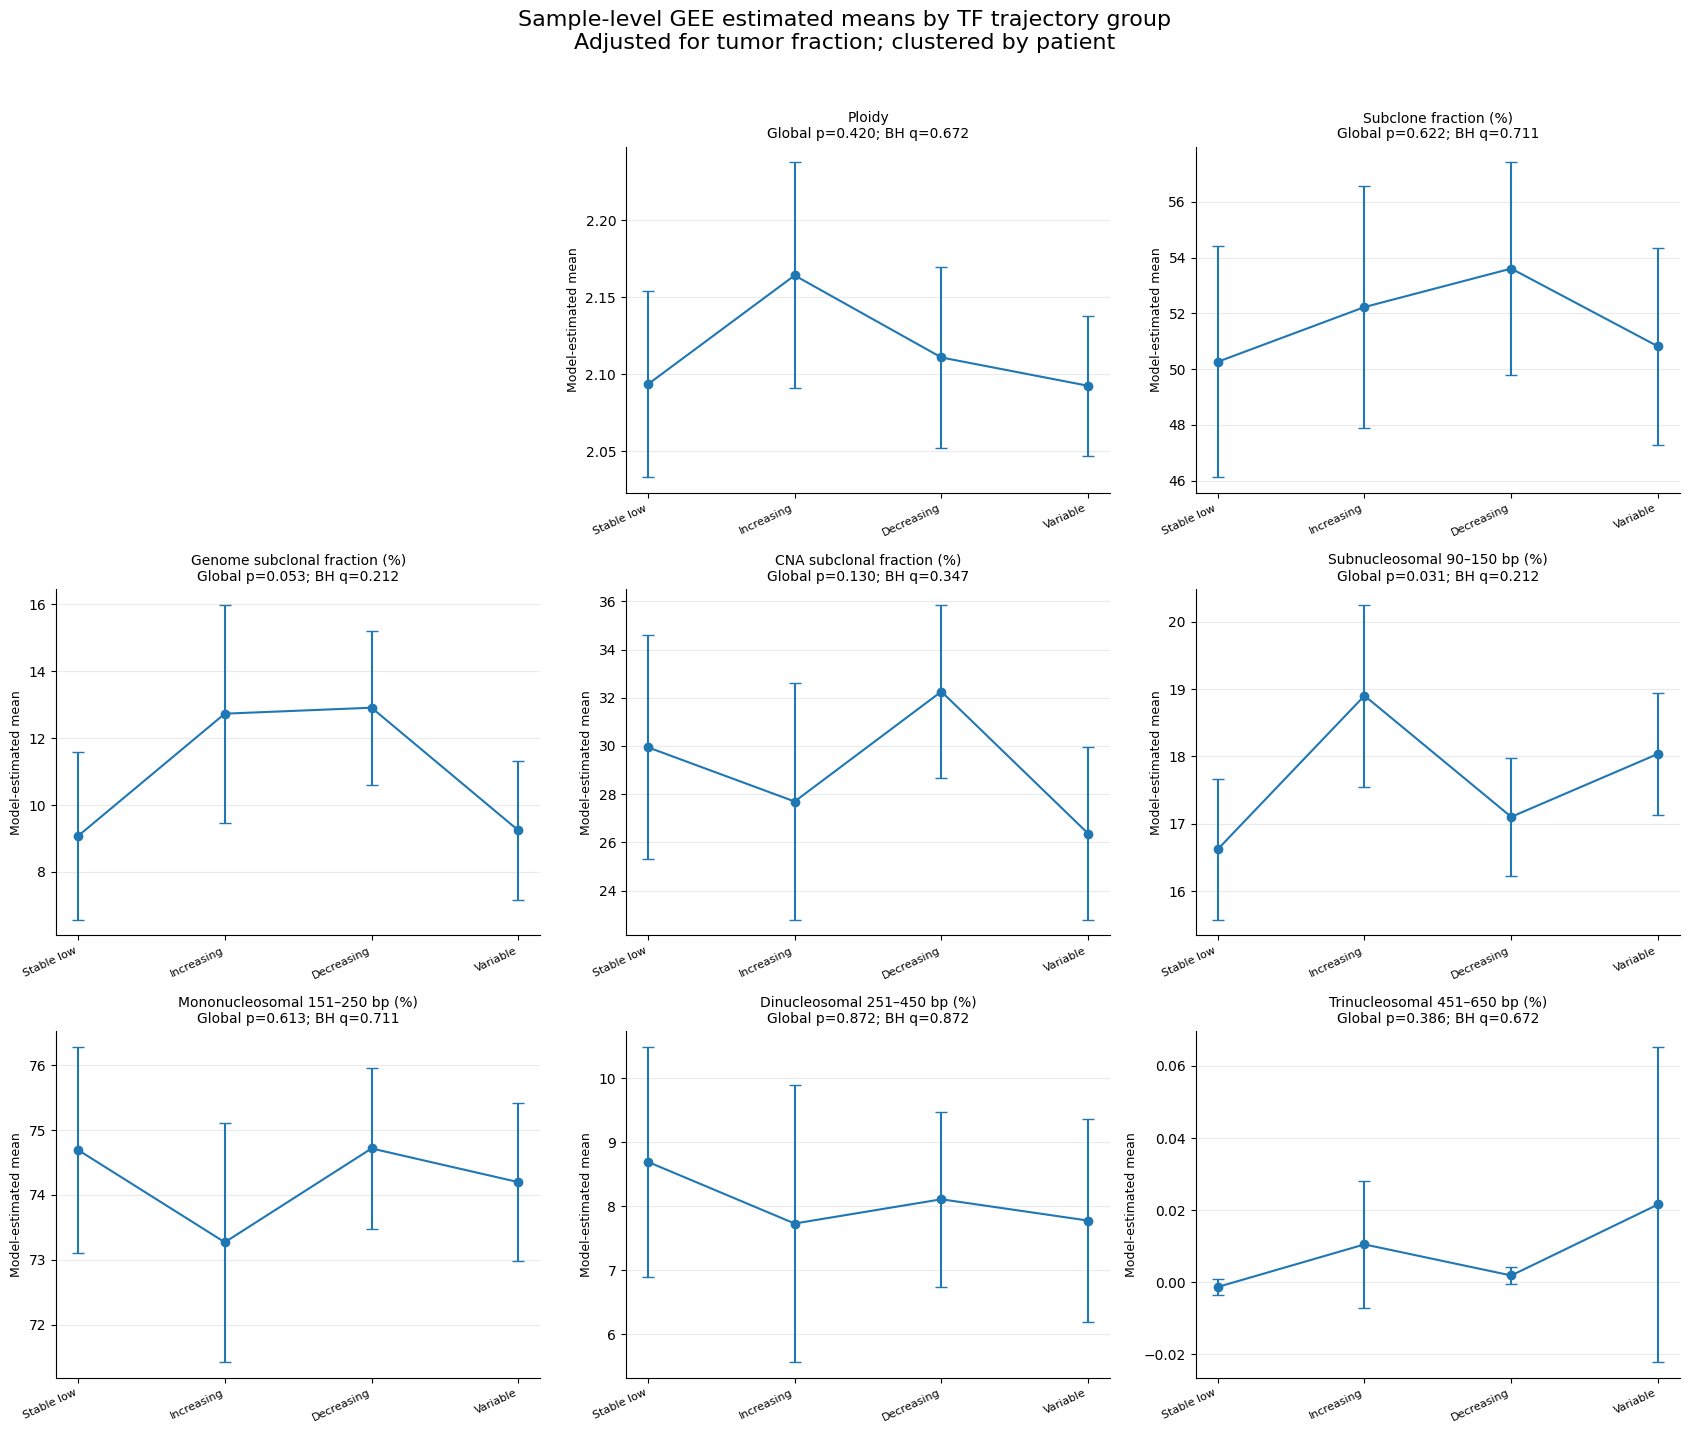

Saved plot PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_2_sample_level_GEE_repeated_measures/plots/Analysis1B_2_GEE_TF_adjusted_estimated_means_by_trajectory_group.png
Saved plot PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_2_sample_level_GEE_repeated_measures/plots/Analysis1B_2_GEE_TF_adjusted_estimated_means_by_trajectory_group.pdf

========== Analysis 1B-2 complete ==========

Interpretation guide:

1. Main file:
   Analysis1B_2_GEE_global_trajectory_tests_sample_level_repeated_measures.csv

   Use this to see whether each feature differs across the 4 trajectory groups
   using all blood draws while clustering by patient.

2. Coefficient file:
   Analysis1B_2_GEE_coefficients_sample_level_repeated_measures.csv

   Reference group:
   Stable low / 

In [3]:
# ============================================================
# Analysis 1B-2:
# Sample-level repeated-measures GEE model using all blood draws
#
# Question:
# Are ichorCNA-derived genomic metrics and global fragmentomic
# features different across the 4 longitudinal TF trajectory groups,
# while accounting for repeated blood draws from the same patient?
#
# Unit of analysis:
#   One row = one blood draw
#
# Repeated-measure structure:
#   Clustered by Patient_Identifier
#
# Primary model (Generalized Estimating Equation (GEE)):
#   Feature ~ Trajectory_4group
#
# Secondary / sensitivity model:
#   Feature ~ Trajectory_4group + Tumor_Fraction_percent
#
# Notes:
#   - Tumor_Fraction_percent itself is analyzed only as validation/descriptive,
#     because the 4 groups were defined from tumor-fraction trajectory.
#   - TF-adjusted models are most biologically useful for fragmentomic features.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re
import warnings

from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf
import patsy

warnings.filterwarnings("ignore")

# ============================================================
# Input / output paths
# ============================================================

analysis1_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables/"
    "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

correlation_out_dir = analysis1_file.parent

analysis1b_dir = (
    correlation_out_dir /
    "Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory"
)

analysis1b_dir.mkdir(parents=True, exist_ok=True)

analysis1b2_dir = (
    analysis1b_dir /
    "Analysis1B_2_sample_level_GEE_repeated_measures"
)

analysis1b2_dir.mkdir(parents=True, exist_ok=True)

plot_dir = analysis1b2_dir / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)

print("\n========== Analysis 1B-2 ==========")
print(f"Input file: {analysis1_file}")
print(f"Output folder: {analysis1b2_dir}")

# ============================================================
# Load data
# ============================================================

df = pd.read_csv(analysis1_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

trajectory_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

reference_group = "Stable low / low-burden"

required_cols = [
    patient_col,
    group_col
]

missing_required = [c for c in required_cols if c not in df.columns]

if len(missing_required) > 0:
    raise ValueError(f"Missing required columns: {missing_required}")

df[patient_col] = df[patient_col].astype(str).str.strip()

df[group_col] = pd.Categorical(
    df[group_col],
    categories=trajectory_order,
    ordered=True
)

print("\n========== Input summary ==========")
print(f"Total blood-draw rows: {df.shape[0]}")
print(f"Unique patients: {df[patient_col].nunique()}")

print("\nTrajectory group distribution:")
print(
    df
    .groupby(group_col, observed=False)
    .agg(
        n_patients=(patient_col, "nunique"),
        n_blood_draws=(patient_col, "size")
    )
    .reset_index()
    .to_string(index=False)
)

# ============================================================
# Define source feature columns
# ============================================================

# Tumor fraction column
if "Tumor_Fraction_percent" in df.columns:
    tf_source_col = "Tumor_Fraction_percent"
elif "Tumor_Fraction" in df.columns:
    tf_source_col = "Tumor_Fraction"
else:
    raise ValueError("Could not find Tumor_Fraction_percent or Tumor_Fraction column.")

feature_source_cols = [
    tf_source_col,
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

# Remove duplicate if tf_source_col is already named Tumor_Fraction_percent
feature_source_cols = list(dict.fromkeys(feature_source_cols))

missing_features = [c for c in feature_source_cols if c not in df.columns]

if len(missing_features) > 0:
    raise ValueError(f"Missing feature columns: {missing_features}")

# ============================================================
# Build model-ready feature columns
# Convert fraction-like variables to percentages when needed
# ============================================================

feature_specs = []

def clean_model_colname(x):
    x = str(x)
    x = x.replace("%", "percent")
    x = re.sub(r"[^A-Za-z0-9]+", "_", x)
    x = re.sub(r"_+", "_", x)
    return x.strip("_")

def convert_to_numeric_percent_if_fraction(data, source_col, force_percent=False):
    """
    Convert source column to numeric.
    If force_percent=True or column looks like fraction/proportion,
    multiply by 100 when q99 <= 1.5.
    """
    vals = pd.to_numeric(data[source_col], errors="coerce")

    q99 = vals.dropna().quantile(0.99) if vals.dropna().shape[0] > 0 else np.nan

    converted = vals.copy()
    scale_note = "raw scale"

    if force_percent:
        if pd.notna(q99) and q99 <= 1.5:
            converted = vals * 100
            scale_note = "converted from fraction to percent"
        else:
            converted = vals
            scale_note = "already percent-like"
    else:
        converted = vals
        scale_note = "raw scale"

    return converted, scale_note

# Tumor fraction as percent
df["Tumor_Fraction_percent_model"], tf_scale_note = convert_to_numeric_percent_if_fraction(
    df,
    tf_source_col,
    force_percent=True
)

feature_specs.append({
    "source_col": tf_source_col,
    "model_col": "Tumor_Fraction_percent_model",
    "feature_label": "Tumor fraction (%)",
    "feature_type": "TF validation",
    "scale_note": tf_scale_note
})

# Other features
other_features = [
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

feature_label_map = {
    "Ploidy": "Ploidy",
    "Subclone Fraction": "Subclone fraction (%)",
    "Frac. Genome Subclonal": "Genome subclonal fraction (%)",
    "Frac. CNA Subclonal": "CNA subclonal fraction (%)",
    "Frac_Subnucleosomal_90_150": "Subnucleosomal 90–150 bp (%)",
    "Frac_Mononucleosomal_151_250": "Mononucleosomal 151–250 bp (%)",
    "Frac_Dinucleosomal_251_450": "Dinucleosomal 251–450 bp (%)",
    "Frac_Trinucleosomal_451_650": "Trinucleosomal 451–650 bp (%)"
}

feature_type_map = {
    "Ploidy": "ichorCNA genomic metric",
    "Subclone Fraction": "ichorCNA genomic metric",
    "Frac. Genome Subclonal": "ichorCNA genomic metric",
    "Frac. CNA Subclonal": "ichorCNA genomic metric",
    "Frac_Subnucleosomal_90_150": "global fragmentomics",
    "Frac_Mononucleosomal_151_250": "global fragmentomics",
    "Frac_Dinucleosomal_251_450": "global fragmentomics",
    "Frac_Trinucleosomal_451_650": "global fragmentomics"
}

for source_col in other_features:

    model_col = clean_model_colname(source_col) + "_model"

    # Ploidy should stay raw.
    # Fraction/subclonal/fragmentomic features are converted to percent if 0-1 scale.
    force_percent = source_col != "Ploidy"

    df[model_col], scale_note = convert_to_numeric_percent_if_fraction(
        df,
        source_col,
        force_percent=force_percent
    )

    feature_specs.append({
        "source_col": source_col,
        "model_col": model_col,
        "feature_label": feature_label_map.get(source_col, source_col),
        "feature_type": feature_type_map.get(source_col, "unknown"),
        "scale_note": scale_note
    })

feature_specs_df = pd.DataFrame(feature_specs)

feature_specs_file = analysis1b2_dir / "Analysis1B_2_feature_model_column_map.csv"
feature_specs_df.to_csv(feature_specs_file, index=False)

print("\n========== Feature model column map ==========")
print(feature_specs_df.to_string(index=False))
print(f"\nSaved feature map: {feature_specs_file}")

# ============================================================
# Save sample-level model-ready table
# ============================================================

model_feature_cols = [x["model_col"] for x in feature_specs]

model_ready_cols = [
    patient_col,
    group_col
] + model_feature_cols

optional_cols = [
    "Collaborator_sample_id",
    "Barcode",
    "Patient_id",
    "draw_num",
    "Clinical_ID",
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

model_ready_cols += [c for c in optional_cols if c in df.columns]
model_ready_cols = list(dict.fromkeys(model_ready_cols))

model_ready_df = df[model_ready_cols].copy()

model_ready_file = (
    analysis1b2_dir /
    "Analysis1B_2_sample_level_model_ready_table.csv"
)

model_ready_df.to_csv(model_ready_file, index=False)

print(f"\nSaved model-ready sample-level table: {model_ready_file}")

# ============================================================
# Missingness summary by model feature
# ============================================================

missing_rows = []

for spec in feature_specs:

    col = spec["model_col"]

    g = model_ready_df[
        [
            patient_col,
            group_col,
            col
        ]
    ].copy()

    missing_rows.append({
        "source_col": spec["source_col"],
        "model_col": col,
        "feature_label": spec["feature_label"],
        "feature_type": spec["feature_type"],
        "scale_note": spec["scale_note"],
        "n_total_rows": g.shape[0],
        "n_nonmissing_rows": g[col].notna().sum(),
        "n_missing_rows": g[col].isna().sum(),
        "percent_missing_rows": 100 * g[col].isna().mean(),
        "n_patients_total": g[patient_col].nunique(),
        "n_patients_with_nonmissing": g.loc[g[col].notna(), patient_col].nunique()
    })

missing_df = pd.DataFrame(missing_rows)

missing_file = (
    analysis1b2_dir /
    "Analysis1B_2_feature_missingness_summary.csv"
)

missing_df.to_csv(missing_file, index=False)

print("\n========== Feature missingness ==========")
print(missing_df.to_string(index=False))
print(f"\nSaved missingness summary: {missing_file}")

# ============================================================
# Helper functions for GEE modeling
# ============================================================

def extract_pvalue(x):
    try:
        return float(np.asarray(x).reshape(-1)[0])
    except Exception:
        return np.nan

def run_gee_model(
    input_df,
    outcome_col,
    outcome_label,
    source_col,
    feature_type,
    model_name,
    adjust_for_tf=False
):
    """
    Run patient-clustered GEE:
      Outcome ~ Trajectory_4group
      Outcome ~ Trajectory_4group + Tumor_Fraction_percent_model
    """

    working_df = input_df[
        [
            patient_col,
            group_col,
            outcome_col,
            "Tumor_Fraction_percent_model"
        ]
    ].copy()

    working_df = working_df.rename(
        columns={
            patient_col: "Patient_ID",
            group_col: "Trajectory_group",
            outcome_col: "Outcome"
        }
    )

    # Drop missing outcome/group/patient
    required = [
        "Patient_ID",
        "Trajectory_group",
        "Outcome"
    ]

    if adjust_for_tf:
        required.append("Tumor_Fraction_percent_model")

    working_df = working_df.dropna(subset=required).copy()

    working_df["Trajectory_group"] = pd.Categorical(
        working_df["Trajectory_group"],
        categories=trajectory_order,
        ordered=True
    )

    # Need at least 2 groups
    observed_groups = (
        working_df["Trajectory_group"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    n_groups = len(observed_groups)
    n_samples = working_df.shape[0]
    n_patients = working_df["Patient_ID"].nunique()

    coefficient_rows = []
    global_rows = []
    pairwise_rows = []
    estimated_mean_rows = []

    if n_samples < 10 or n_patients < 5 or n_groups < 2:
        global_rows.append({
            "source_col": source_col,
            "outcome_col": outcome_col,
            "feature_label": outcome_label,
            "feature_type": feature_type,
            "model_name": model_name,
            "adjust_for_tf": adjust_for_tf,
            "n_samples": n_samples,
            "n_patients": n_patients,
            "n_groups_observed": n_groups,
            "trajectory_global_statistic": np.nan,
            "trajectory_global_p": np.nan,
            "model_status": "Not enough data/groups"
        })

        return coefficient_rows, global_rows, pairwise_rows, estimated_mean_rows

    # Formula
    formula = (
        'Outcome ~ '
        'C(Trajectory_group, Treatment(reference="Stable low / low-burden"))'
    )

    if adjust_for_tf:
        formula += " + Tumor_Fraction_percent_model"

    model_status = "OK"
    gee_result = None
    cov_structure_used = "Exchangeable"

    try:
        gee_model = smf.gee(
            formula=formula,
            groups=working_df["Patient_ID"],
            data=working_df,
            family=sm.families.Gaussian(),
            cov_struct=sm.cov_struct.Exchangeable()
        )

        gee_result = gee_model.fit()

    except Exception as e1:

        # Fallback to independence working correlation
        cov_structure_used = "Independence"

        try:
            gee_model = smf.gee(
                formula=formula,
                groups=working_df["Patient_ID"],
                data=working_df,
                family=sm.families.Gaussian(),
                cov_struct=sm.cov_struct.Independence()
            )

            gee_result = gee_model.fit()
            model_status = f"OK after fallback to Independence; Exchangeable failed: {str(e1)}"

        except Exception as e2:
            model_status = f"MODEL_FAILED: Exchangeable error={str(e1)}; Independence error={str(e2)}"

            global_rows.append({
                "source_col": source_col,
                "outcome_col": outcome_col,
                "feature_label": outcome_label,
                "feature_type": feature_type,
                "model_name": model_name,
                "adjust_for_tf": adjust_for_tf,
                "n_samples": n_samples,
                "n_patients": n_patients,
                "n_groups_observed": n_groups,
                "trajectory_global_statistic": np.nan,
                "trajectory_global_p": np.nan,
                "cov_structure_used": cov_structure_used,
                "model_status": model_status
            })

            return coefficient_rows, global_rows, pairwise_rows, estimated_mean_rows

    # Extract model outputs
    params = gee_result.params
    pvals = gee_result.pvalues
    conf = gee_result.conf_int()
    cov = gee_result.cov_params()

    if not isinstance(conf, pd.DataFrame):
        conf = pd.DataFrame(
            conf,
            index=params.index,
            columns=[0, 1]
        )

    # Overall Wald test for trajectory group terms
    param_names = list(params.index)

    trajectory_terms = [
        p for p in param_names
        if "Trajectory_group" in p
    ]

    trajectory_global_stat = np.nan
    trajectory_global_p = np.nan

    if len(trajectory_terms) > 0:
        try:
            R = np.zeros((len(trajectory_terms), len(param_names)))

            for i, term in enumerate(trajectory_terms):
                R[i, param_names.index(term)] = 1

            wald_res = gee_result.wald_test(R)
            trajectory_global_stat = extract_pvalue(wald_res.statistic)
            trajectory_global_p = extract_pvalue(wald_res.pvalue)

        except Exception as e:
            model_status = model_status + f"; Wald global test failed: {str(e)}"

    global_rows.append({
        "source_col": source_col,
        "outcome_col": outcome_col,
        "feature_label": outcome_label,
        "feature_type": feature_type,
        "model_name": model_name,
        "adjust_for_tf": adjust_for_tf,
        "n_samples": n_samples,
        "n_patients": n_patients,
        "n_groups_observed": n_groups,
        "cov_structure_used": cov_structure_used,
        "trajectory_global_statistic": trajectory_global_stat,
        "trajectory_global_p": trajectory_global_p,
        "model_status": model_status
    })

    # Coefficient table
    for term in param_names:

        coefficient_rows.append({
            "source_col": source_col,
            "outcome_col": outcome_col,
            "feature_label": outcome_label,
            "feature_type": feature_type,
            "model_name": model_name,
            "adjust_for_tf": adjust_for_tf,
            "term": term,
            "coefficient": params[term],
            "CI_lower": conf.loc[term, 0],
            "CI_upper": conf.loc[term, 1],
            "p_value": pvals[term],
            "n_samples": n_samples,
            "n_patients": n_patients,
            "cov_structure_used": cov_structure_used,
            "model_status": model_status
        })

    # Estimated means / adjusted means
    try:
        design_info = gee_result.model.data.design_info

        if adjust_for_tf:
            mean_tf = working_df["Tumor_Fraction_percent_model"].mean()

            new_data = pd.DataFrame({
                "Trajectory_group": pd.Categorical(
                    trajectory_order,
                    categories=trajectory_order,
                    ordered=True
                ),
                "Tumor_Fraction_percent_model": [mean_tf] * len(trajectory_order)
            })

        else:
            mean_tf = np.nan

            new_data = pd.DataFrame({
                "Trajectory_group": pd.Categorical(
                    trajectory_order,
                    categories=trajectory_order,
                    ordered=True
                )
            })

        X_new = patsy.build_design_matrices(
            [design_info],
            new_data,
            return_type="dataframe"
        )[0]

        pred = np.asarray(X_new @ params)
        pred_var = np.diag(np.asarray(X_new @ cov @ X_new.T))
        pred_var = np.where(pred_var < 0, np.nan, pred_var)
        pred_se = np.sqrt(pred_var)

        for i, group_name in enumerate(trajectory_order):

            estimated_mean_rows.append({
                "source_col": source_col,
                "outcome_col": outcome_col,
                "feature_label": outcome_label,
                "feature_type": feature_type,
                "model_name": model_name,
                "adjust_for_tf": adjust_for_tf,
                "trajectory_group": group_name,
                "estimated_mean": pred[i],
                "SE": pred_se[i],
                "CI_lower": pred[i] - 1.96 * pred_se[i],
                "CI_upper": pred[i] + 1.96 * pred_se[i],
                "Mean_TF_used_for_adjustment": mean_tf,
                "n_samples": n_samples,
                "n_patients": n_patients,
                "cov_structure_used": cov_structure_used,
                "model_status": model_status
            })

        # Pairwise contrasts
        X_lookup = {
            group_name: np.asarray(X_new.loc[i])
            for i, group_name in enumerate(trajectory_order)
        }

        pair_list = [
            ("Increasing / progression-like", "Stable low / low-burden"),
            ("Decreasing / response-like", "Stable low / low-burden"),
            ("Variable / intermediate", "Stable low / low-burden"),
            ("Increasing / progression-like", "Decreasing / response-like"),
            ("Increasing / progression-like", "Variable / intermediate"),
            ("Decreasing / response-like", "Variable / intermediate")
        ]

        for group_a, group_b in pair_list:

            L = X_lookup[group_a] - X_lookup[group_b]

            diff = float(L @ params)

            var_diff = float(L @ cov @ L.T)
            se = np.sqrt(var_diff) if var_diff >= 0 else np.nan

            z = diff / se if pd.notna(se) and se > 0 else np.nan
            p_value = 2 * (1 - stats.norm.cdf(abs(z))) if pd.notna(z) else np.nan

            pairwise_rows.append({
                "source_col": source_col,
                "outcome_col": outcome_col,
                "feature_label": outcome_label,
                "feature_type": feature_type,
                "model_name": model_name,
                "adjust_for_tf": adjust_for_tf,
                "contrast": f"{group_a} minus {group_b}",
                "group_a": group_a,
                "group_b": group_b,
                "difference": diff,
                "SE": se,
                "z": z,
                "p_value": p_value,
                "CI_lower": diff - 1.96 * se if pd.notna(se) else np.nan,
                "CI_upper": diff + 1.96 * se if pd.notna(se) else np.nan,
                "Mean_TF_used_for_adjustment": mean_tf,
                "n_samples": n_samples,
                "n_patients": n_patients,
                "cov_structure_used": cov_structure_used,
                "model_status": model_status
            })

    except Exception as e:
        model_status = model_status + f"; Estimated means / contrasts failed: {str(e)}"

    return coefficient_rows, global_rows, pairwise_rows, estimated_mean_rows

# ============================================================
# Run GEE models
# ============================================================

all_coefficient_rows = []
all_global_rows = []
all_pairwise_rows = []
all_estimated_mean_rows = []

print("\n========== Running GEE models ==========")

for spec in feature_specs:

    source_col = spec["source_col"]
    outcome_col = spec["model_col"]
    outcome_label = spec["feature_label"]
    feature_type = spec["feature_type"]

    print(f"\nRunning unadjusted GEE for: {outcome_label}")

    coef_rows, glob_rows, pair_rows, mean_rows = run_gee_model(
        input_df=df,
        outcome_col=outcome_col,
        outcome_label=outcome_label,
        source_col=source_col,
        feature_type=feature_type,
        model_name="GEE_unadjusted_trajectory_group",
        adjust_for_tf=False
    )

    all_coefficient_rows.extend(coef_rows)
    all_global_rows.extend(glob_rows)
    all_pairwise_rows.extend(pair_rows)
    all_estimated_mean_rows.extend(mean_rows)

    # Do not adjust tumor fraction outcome for tumor fraction
    if outcome_col == "Tumor_Fraction_percent_model":
        continue

    print(f"Running TF-adjusted GEE for: {outcome_label}")

    coef_rows, glob_rows, pair_rows, mean_rows = run_gee_model(
        input_df=df,
        outcome_col=outcome_col,
        outcome_label=outcome_label,
        source_col=source_col,
        feature_type=feature_type,
        model_name="GEE_TF_adjusted_trajectory_group",
        adjust_for_tf=True
    )

    all_coefficient_rows.extend(coef_rows)
    all_global_rows.extend(glob_rows)
    all_pairwise_rows.extend(pair_rows)
    all_estimated_mean_rows.extend(mean_rows)

gee_coef_df = pd.DataFrame(all_coefficient_rows)
gee_global_df = pd.DataFrame(all_global_rows)
gee_pairwise_df = pd.DataFrame(all_pairwise_rows)
gee_means_df = pd.DataFrame(all_estimated_mean_rows)

# ============================================================
# Multiple-testing correction
# ============================================================

# Global trajectory p-values: BH within each model_name
if gee_global_df.shape[0] > 0:
    gee_global_df["trajectory_global_BH_q"] = np.nan

    for model_name, idx in gee_global_df.groupby("model_name").groups.items():
        mask = gee_global_df.index.isin(idx) & gee_global_df["trajectory_global_p"].notna()

        if mask.sum() > 0:
            gee_global_df.loc[mask, "trajectory_global_BH_q"] = multipletests(
                gee_global_df.loc[mask, "trajectory_global_p"],
                method="fdr_bh"
            )[1]

# Coefficient p-values: BH within each model_name, excluding intercept
if gee_coef_df.shape[0] > 0:
    gee_coef_df["coefficient_BH_q"] = np.nan

    for model_name, idx in gee_coef_df.groupby("model_name").groups.items():

        mask = (
            gee_coef_df.index.isin(idx) &
            gee_coef_df["p_value"].notna() &
            (gee_coef_df["term"] != "Intercept")
        )

        if mask.sum() > 0:
            gee_coef_df.loc[mask, "coefficient_BH_q"] = multipletests(
                gee_coef_df.loc[mask, "p_value"],
                method="fdr_bh"
            )[1]

# Pairwise p-values: BH within each model_name
if gee_pairwise_df.shape[0] > 0:
    gee_pairwise_df["pairwise_BH_q"] = np.nan

    for model_name, idx in gee_pairwise_df.groupby("model_name").groups.items():

        mask = (
            gee_pairwise_df.index.isin(idx) &
            gee_pairwise_df["p_value"].notna()
        )

        if mask.sum() > 0:
            gee_pairwise_df.loc[mask, "pairwise_BH_q"] = multipletests(
                gee_pairwise_df.loc[mask, "p_value"],
                method="fdr_bh"
            )[1]

# ============================================================
# Save model outputs
# ============================================================

gee_coef_file = (
    analysis1b2_dir /
    "Analysis1B_2_GEE_coefficients_sample_level_repeated_measures.csv"
)

gee_global_file = (
    analysis1b2_dir /
    "Analysis1B_2_GEE_global_trajectory_tests_sample_level_repeated_measures.csv"
)

gee_pairwise_file = (
    analysis1b2_dir /
    "Analysis1B_2_GEE_pairwise_trajectory_contrasts_sample_level_repeated_measures.csv"
)

gee_means_file = (
    analysis1b2_dir /
    "Analysis1B_2_GEE_estimated_means_by_trajectory_group.csv"
)

gee_coef_df.to_csv(gee_coef_file, index=False)
gee_global_df.to_csv(gee_global_file, index=False)
gee_pairwise_df.to_csv(gee_pairwise_file, index=False)
gee_means_df.to_csv(gee_means_file, index=False)

print("\n========== Saved GEE outputs ==========")
print(f"Coefficients: {gee_coef_file}")
print(f"Global trajectory tests: {gee_global_file}")
print(f"Pairwise contrasts: {gee_pairwise_file}")
print(f"Estimated means: {gee_means_file}")

# ============================================================
# Print main summary
# ============================================================

print("\n========== Global trajectory association summary ==========")

summary_cols = [
    "feature_label",
    "feature_type",
    "model_name",
    "n_samples",
    "n_patients",
    "trajectory_global_p",
    "trajectory_global_BH_q",
    "cov_structure_used",
    "model_status"
]

available_summary_cols = [
    c for c in summary_cols
    if c in gee_global_df.columns
]

print(
    gee_global_df[available_summary_cols]
    .sort_values(["model_name", "trajectory_global_p"], na_position="last")
    .to_string(index=False)
)

# ============================================================
# Plot estimated means by trajectory group
# One plot for unadjusted models
# One plot for TF-adjusted models
# ============================================================

def safe_filename(x):
    x = str(x)
    x = x.replace("/", "_")
    x = x.replace("+", "plus")
    x = re.sub(r"[^A-Za-z0-9_]+", "_", x)
    x = re.sub(r"_+", "_", x)
    return x.strip("_")

def plot_gee_estimated_means(model_name, output_prefix):

    plot_df = gee_means_df[
        gee_means_df["model_name"] == model_name
    ].copy()

    if plot_df.shape[0] == 0:
        print(f"No estimated means available for {model_name}")
        return

    feature_order = (
        feature_specs_df["feature_label"]
        .drop_duplicates()
        .tolist()
    )

    plot_df["feature_label"] = pd.Categorical(
        plot_df["feature_label"],
        categories=feature_order,
        ordered=True
    )

    plot_df["trajectory_group"] = pd.Categorical(
        plot_df["trajectory_group"],
        categories=trajectory_order,
        ordered=True
    )

    fig, axes = plt.subplots(
        nrows=3,
        ncols=3,
        figsize=(17, 14)
    )

    axes = axes.reshape(-1)

    for ax, feature_label in zip(axes, feature_order):

        g = plot_df[
            plot_df["feature_label"] == feature_label
        ].copy()

        if g.shape[0] == 0:
            ax.axis("off")
            continue

        g = g.sort_values("trajectory_group")

        x = np.arange(g.shape[0])
        y = g["estimated_mean"].values
        lower = g["CI_lower"].values
        upper = g["CI_upper"].values

        yerr_lower = y - lower
        yerr_upper = upper - y

        ax.errorbar(
            x,
            y,
            yerr=[yerr_lower, yerr_upper],
            marker="o",
            linestyle="-",
            capsize=4
        )

        ax.set_xticks(x)
        ax.set_xticklabels(
            [
                "Stable low",
                "Increasing",
                "Decreasing",
                "Variable"
            ],
            rotation=25,
            ha="right",
            fontsize=8
        )

        # Add global q-value in title
        q_row = gee_global_df[
            (gee_global_df["model_name"] == model_name) &
            (gee_global_df["feature_label"] == feature_label)
        ]

        if q_row.shape[0] > 0:
            p_val = q_row["trajectory_global_p"].iloc[0]
            q_val = q_row["trajectory_global_BH_q"].iloc[0]

            if pd.isna(p_val):
                p_text = "p=NA"
            elif p_val < 0.001:
                p_text = "p<0.001"
            else:
                p_text = f"p={p_val:.3f}"

            if pd.isna(q_val):
                q_text = "q=NA"
            elif q_val < 0.001:
                q_text = "q<0.001"
            else:
                q_text = f"q={q_val:.3f}"

            title_text = f"{feature_label}\nGlobal {p_text}; BH {q_text}"
        else:
            title_text = feature_label

        ax.set_title(title_text, fontsize=10)
        ax.set_ylabel("Model-estimated mean", fontsize=9)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(axis="y", alpha=0.25)

    for j in range(len(feature_order), len(axes)):
        axes[j].axis("off")

    if model_name == "GEE_TF_adjusted_trajectory_group":
        main_title = (
            "Sample-level GEE estimated means by TF trajectory group\n"
            "Adjusted for tumor fraction; clustered by patient"
        )
    else:
        main_title = (
            "Sample-level GEE estimated means by TF trajectory group\n"
            "Unadjusted; clustered by patient"
        )

    plt.suptitle(
        main_title,
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()

    png_file = plot_dir / f"{output_prefix}.png"
    pdf_file = plot_dir / f"{output_prefix}.pdf"

    fig.savefig(
        png_file,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        pdf_file,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    print(f"Saved plot PNG: {png_file}")
    print(f"Saved plot PDF: {pdf_file}")

plot_gee_estimated_means(
    model_name="GEE_unadjusted_trajectory_group",
    output_prefix="Analysis1B_2_GEE_unadjusted_estimated_means_by_trajectory_group"
)

plot_gee_estimated_means(
    model_name="GEE_TF_adjusted_trajectory_group",
    output_prefix="Analysis1B_2_GEE_TF_adjusted_estimated_means_by_trajectory_group"
)

# ============================================================
# Final interpretation helper
# ============================================================

print("\n========== Analysis 1B-2 complete ==========")

print(
    """
Interpretation guide:

1. Main file:
   Analysis1B_2_GEE_global_trajectory_tests_sample_level_repeated_measures.csv

   Use this to see whether each feature differs across the 4 trajectory groups
   using all blood draws while clustering by patient.

2. Coefficient file:
   Analysis1B_2_GEE_coefficients_sample_level_repeated_measures.csv

   Reference group:
   Stable low / low-burden

   Coefficients for other groups represent the estimated difference from
   Stable low / low-burden.

3. Pairwise file:
   Analysis1B_2_GEE_pairwise_trajectory_contrasts_sample_level_repeated_measures.csv

   Use this for all pairwise group comparisons.

4. Estimated means file:
   Analysis1B_2_GEE_estimated_means_by_trajectory_group.csv

   Use this for model-estimated group means and confidence intervals.

5. Important caution:
   Tumor fraction is included as a validation/descriptive outcome because
   the 4 trajectory groups were defined from tumor-fraction behavior.

6. For fragmentomic features:
   The TF-adjusted model is especially important:
   Fragmentation feature ~ Trajectory_4group + Tumor_Fraction_percent
   clustered by Patient_Identifier.
"""
)


========== Analysis 1B-3 ==========
Sample-level input file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Patient-level input file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_patient_level_feature_median_summary.csv
Output folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis

Patient-level median table not found.
Recreating patient-level median table from sample-level input.
Saved recreated patient-level table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_patient_level_feature_median_s

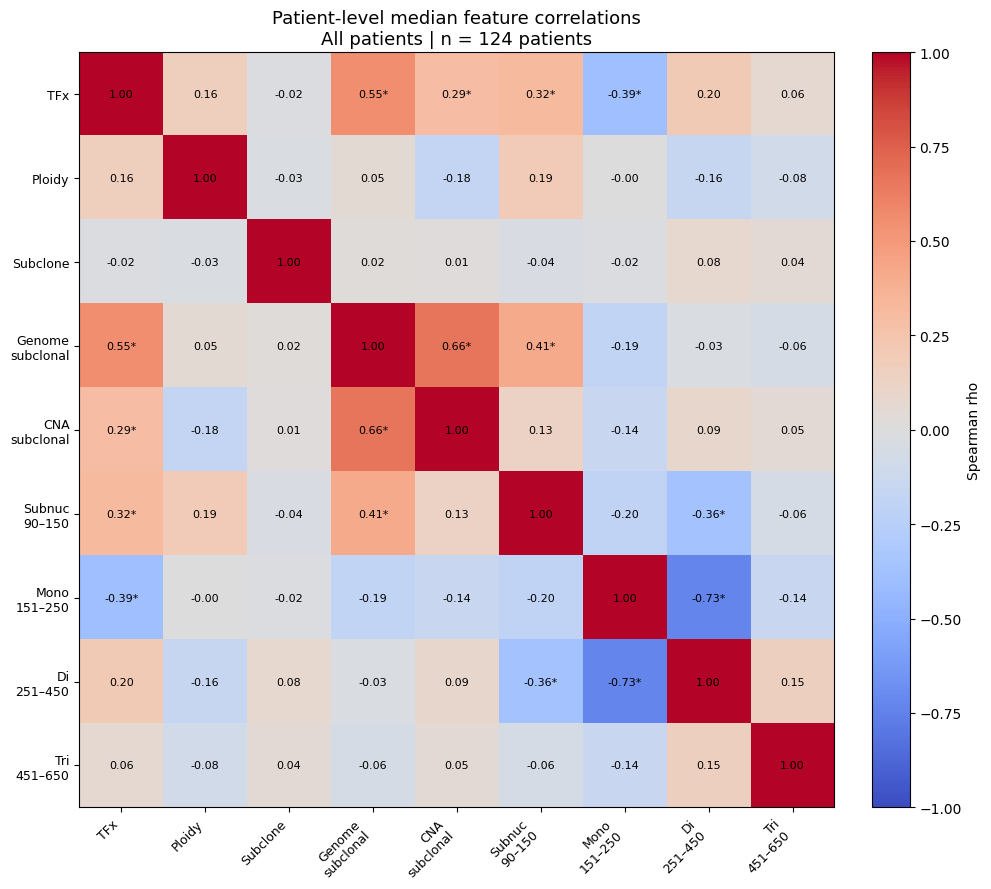

Saved heatmap PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_All_patients.png
Saved heatmap PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_All_patients.pdf


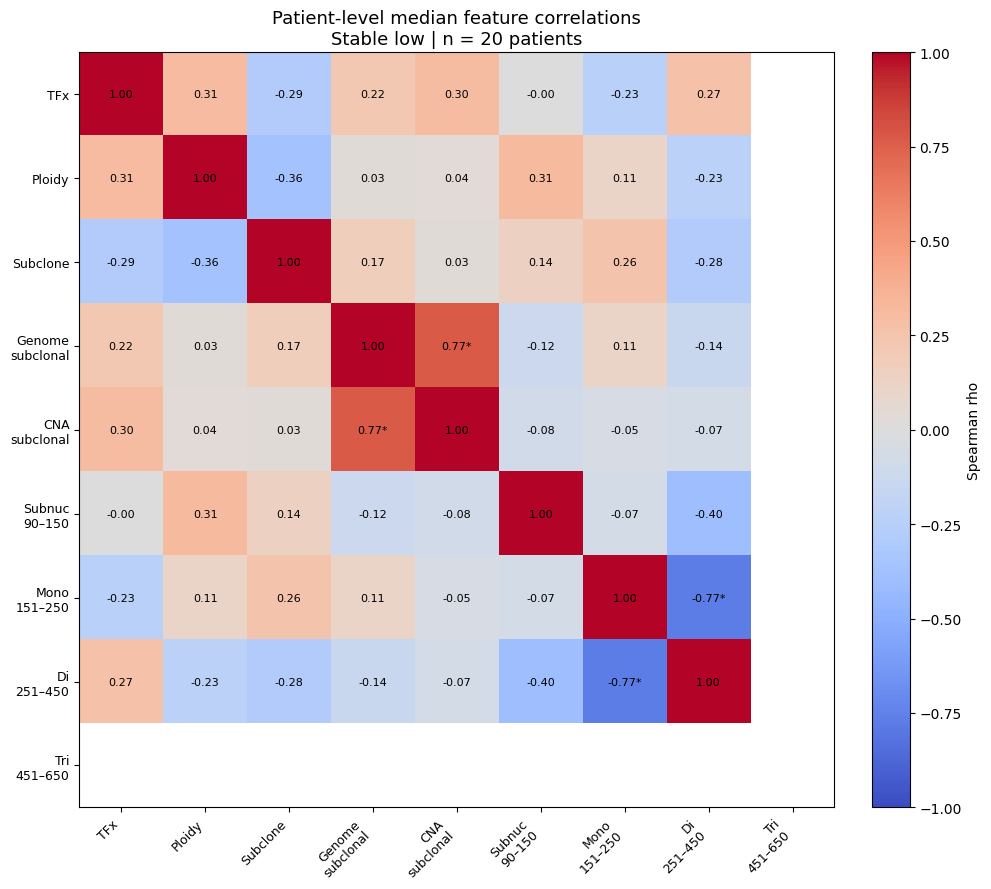

Saved heatmap PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Stable_low_low_burden.png
Saved heatmap PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Stable_low_low_burden.pdf


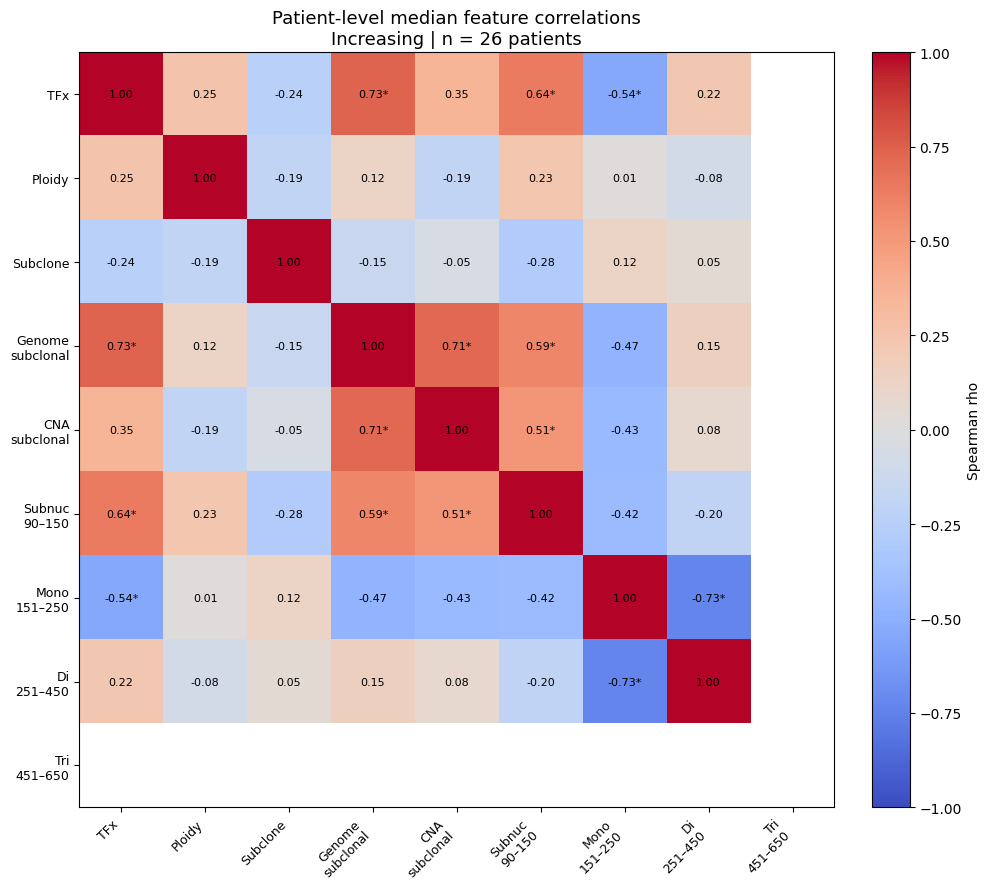

Saved heatmap PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Increasing_progression_like.png
Saved heatmap PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Increasing_progression_like.pdf


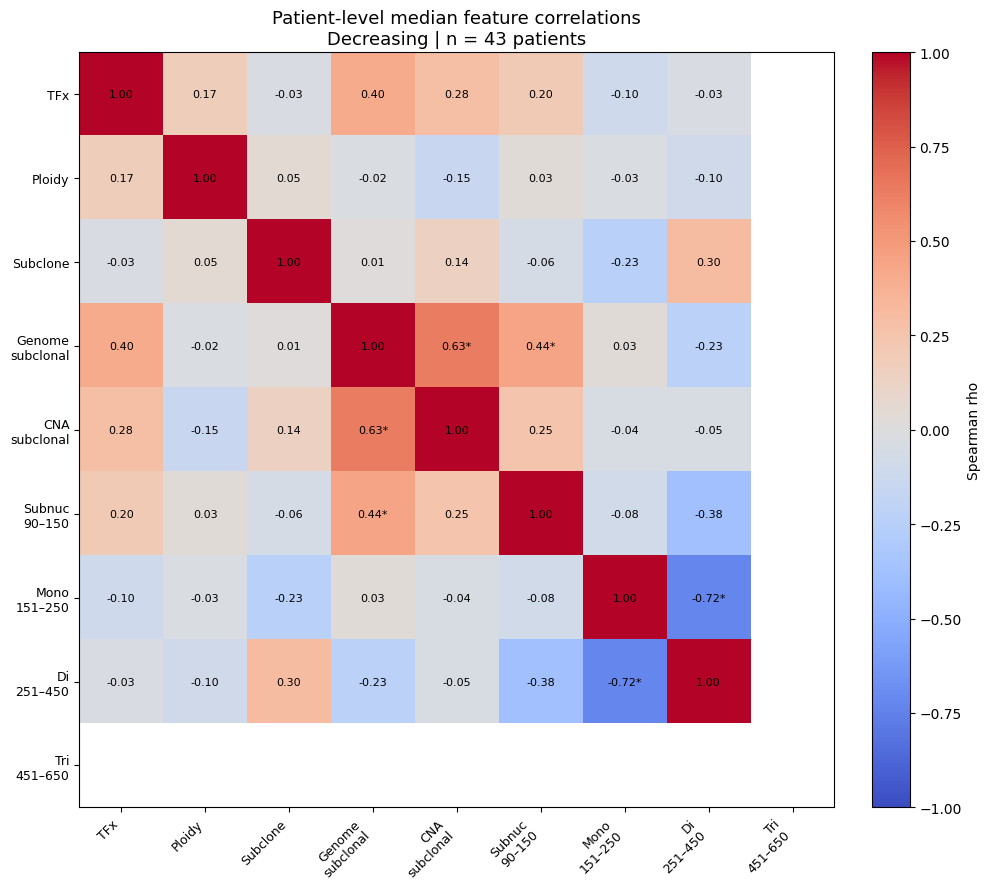

Saved heatmap PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Decreasing_response_like.png
Saved heatmap PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Decreasing_response_like.pdf


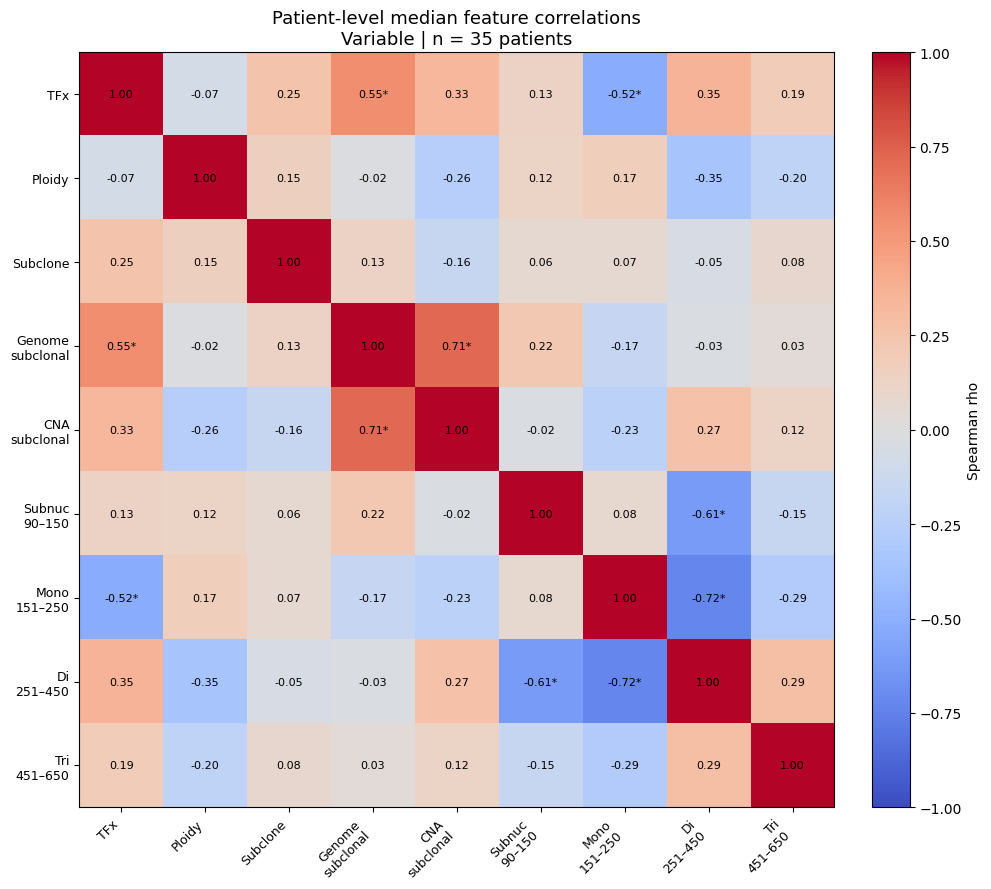

Saved heatmap PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Variable_intermediate.png
Saved heatmap PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/correlation_heatmaps/Analysis1B_3_Spearman_correlation_heatmap_Variable_intermediate.pdf

Saved top ichorCNA-fragmentomics correlations: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory/Analysis1B_3_within_group_correlation_analysis/Analysis1B_3_top_ichorCNA_vs_fragmentomics_correlations_per_group.csv

========== Top ichorCNA-fragmentomics correlations ==========
            cor

In [4]:
# ============================================================
# Analysis 1B-3:
# Within-group correlation analysis among ichorCNA and
# global fragmentomic variables
#
# Question:
# Within each TF trajectory group, how are patient-level median
# ichorCNA-derived metrics and fragmentomic features correlated?
#
# Unit of analysis:
#   One row = one patient
#
# Feature value:
#   Median across that patient's blood draws
#
# Method:
#   Spearman correlation within each trajectory group
#
# Important:
#   - This is exploratory.
#   - Tumor fraction should be interpreted carefully because the
#     trajectory groups were defined from TF behavior.
#   - Fragment-size classes are compositional and may naturally
#     show inverse correlations.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import re
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# Input / output paths
# ============================================================

analysis1_sample_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables/"
    "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

correlation_out_dir = analysis1_sample_file.parent

analysis1b_dir = (
    correlation_out_dir /
    "Analysis1B_ichorCNA_fragmentomics_by_TF_trajectory"
)

analysis1b_dir.mkdir(parents=True, exist_ok=True)

# This file should already exist from Analysis 1B-1
patient_level_file = (
    analysis1b_dir /
    "Analysis1B_patient_level_feature_median_summary.csv"
)

analysis1b3_dir = (
    analysis1b_dir /
    "Analysis1B_3_within_group_correlation_analysis"
)

analysis1b3_dir.mkdir(parents=True, exist_ok=True)

heatmap_dir = analysis1b3_dir / "correlation_heatmaps"
heatmap_dir.mkdir(parents=True, exist_ok=True)

print("\n========== Analysis 1B-3 ==========")
print(f"Sample-level input file: {analysis1_sample_file}")
print(f"Patient-level input file: {patient_level_file}")
print(f"Output folder: {analysis1b3_dir}")

# ============================================================
# Core columns and trajectory order
# ============================================================

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

trajectory_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

trajectory_short_labels = {
    "Stable low / low-burden": "Stable low",
    "Increasing / progression-like": "Increasing",
    "Decreasing / response-like": "Decreasing",
    "Variable / intermediate": "Variable",
    "All patients": "All patients"
}

# ============================================================
# Features for correlation
# ============================================================

features = [
    "Tumor_Fraction_percent",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

feature_labels = {
    "Tumor_Fraction_percent": "Tumor fraction (%)",
    "Ploidy": "Ploidy",
    "Subclone Fraction": "Subclone fraction (%)",
    "Frac. Genome Subclonal": "Genome subclonal fraction (%)",
    "Frac. CNA Subclonal": "CNA subclonal fraction (%)",
    "Frac_Subnucleosomal_90_150": "Subnucleosomal 90–150 bp (%)",
    "Frac_Mononucleosomal_151_250": "Mononucleosomal 151–250 bp (%)",
    "Frac_Dinucleosomal_251_450": "Dinucleosomal 251–450 bp (%)",
    "Frac_Trinucleosomal_451_650": "Trinucleosomal 451–650 bp (%)"
}

feature_short_labels = {
    "Tumor_Fraction_percent": "TFx",
    "Ploidy": "Ploidy",
    "Subclone Fraction": "Subclone",
    "Frac. Genome Subclonal": "Genome\nsubclonal",
    "Frac. CNA Subclonal": "CNA\nsubclonal",
    "Frac_Subnucleosomal_90_150": "Subnuc\n90–150",
    "Frac_Mononucleosomal_151_250": "Mono\n151–250",
    "Frac_Dinucleosomal_251_450": "Di\n251–450",
    "Frac_Trinucleosomal_451_650": "Tri\n451–650"
}

feature_class = {
    "Tumor_Fraction_percent": "tumor_fraction",
    "Ploidy": "ichorCNA",
    "Subclone Fraction": "ichorCNA",
    "Frac. Genome Subclonal": "ichorCNA",
    "Frac. CNA Subclonal": "ichorCNA",
    "Frac_Subnucleosomal_90_150": "fragmentomics",
    "Frac_Mononucleosomal_151_250": "fragmentomics",
    "Frac_Dinucleosomal_251_450": "fragmentomics",
    "Frac_Trinucleosomal_451_650": "fragmentomics"
}

# Minimum number of patients required for a correlation test
MIN_N_PATIENTS = 8

# ============================================================
# Load patient-level median table
# If missing, recreate from sample-level table
# ============================================================

def convert_to_numeric_percent_if_fraction(series):
    vals = pd.to_numeric(series, errors="coerce")

    if vals.dropna().shape[0] == 0:
        return vals

    q99 = vals.dropna().quantile(0.99)

    if pd.notna(q99) and q99 <= 1.5:
        return vals * 100

    return vals


if patient_level_file.exists():

    print("\nLoading patient-level median table from Analysis 1B-1.")
    patient_level_df = pd.read_csv(patient_level_file)

else:

    print("\nPatient-level median table not found.")
    print("Recreating patient-level median table from sample-level input.")

    df = pd.read_csv(analysis1_sample_file)

    missing_features = [f for f in features if f not in df.columns]
    if len(missing_features) > 0:
        raise ValueError(f"Missing required feature columns: {missing_features}")

    for col in features:
        if col == "Ploidy":
            df[col + "_for_patient_median"] = pd.to_numeric(df[col], errors="coerce")
        else:
            df[col + "_for_patient_median"] = convert_to_numeric_percent_if_fraction(df[col])

    patient_rows = []

    for pid, g in df.groupby(patient_col, sort=False):

        row = {
            patient_col: pid,
            group_col: g[group_col].dropna().iloc[0] if g[group_col].notna().any() else pd.NA,
            "n_blood_draws": g.shape[0]
        }

        for col in features:
            row[f"median_{col}"] = g[col + "_for_patient_median"].median(skipna=True)

        patient_rows.append(row)

    patient_level_df = pd.DataFrame(patient_rows)

    patient_level_df.to_csv(patient_level_file, index=False)
    print(f"Saved recreated patient-level table: {patient_level_file}")

# ============================================================
# Validate patient-level median columns
# ============================================================

required_patient_cols = [
    patient_col,
    group_col
] + [f"median_{f}" for f in features]

missing_cols = [c for c in required_patient_cols if c not in patient_level_df.columns]

if len(missing_cols) > 0:
    raise ValueError(f"Missing columns in patient-level table: {missing_cols}")

patient_level_df[group_col] = pd.Categorical(
    patient_level_df[group_col],
    categories=trajectory_order,
    ordered=True
)

for f in features:
    patient_level_df[f"median_{f}"] = pd.to_numeric(
        patient_level_df[f"median_{f}"],
        errors="coerce"
    )

print("\n========== Patient-level input summary ==========")
print(f"Patient-level rows: {patient_level_df.shape[0]}")
print(f"Unique patients: {patient_level_df[patient_col].nunique()}")

print("\nTrajectory group distribution:")
print(
    patient_level_df
    .groupby(group_col, observed=False)
    .agg(
        n_patients=(patient_col, "nunique"),
        median_n_blood_draws=("n_blood_draws", "median")
    )
    .reset_index()
    .to_string(index=False)
)

# ============================================================
# Missingness summary
# ============================================================

missing_rows = []

for f in features:
    col = f"median_{f}"

    missing_rows.append({
        "feature": f,
        "feature_label": feature_labels.get(f, f),
        "n_patients_total": patient_level_df.shape[0],
        "n_nonmissing_patients": patient_level_df[col].notna().sum(),
        "n_missing_patients": patient_level_df[col].isna().sum(),
        "percent_missing": 100 * patient_level_df[col].isna().mean()
    })

missing_df = pd.DataFrame(missing_rows)

missing_file = (
    analysis1b3_dir /
    "Analysis1B_3_patient_level_feature_missingness_for_correlation.csv"
)

missing_df.to_csv(missing_file, index=False)

print("\n========== Missingness summary ==========")
print(missing_df.to_string(index=False))
print(f"\nSaved missingness summary: {missing_file}")

# ============================================================
# Helper functions
# ============================================================

def safe_filename(x):
    x = str(x)
    x = x.replace("/", "_")
    x = x.replace("+", "plus")
    x = re.sub(r"[^A-Za-z0-9_]+", "_", x)
    x = re.sub(r"_+", "_", x)
    return x.strip("_")


def get_pair_type(feature_1, feature_2):

    class_1 = feature_class.get(feature_1, "unknown")
    class_2 = feature_class.get(feature_2, "unknown")

    if "tumor_fraction" in [class_1, class_2]:
        return "TFx_vs_other"

    if class_1 == "ichorCNA" and class_2 == "ichorCNA":
        return "ichorCNA_vs_ichorCNA"

    if class_1 == "fragmentomics" and class_2 == "fragmentomics":
        return "fragmentomics_vs_fragmentomics"

    if set([class_1, class_2]) == set(["ichorCNA", "fragmentomics"]):
        return "ichorCNA_vs_fragmentomics"

    return "other"


def spearman_test(x, y, min_n=8):

    tmp = pd.DataFrame({
        "x": x,
        "y": y
    }).dropna()

    n = tmp.shape[0]

    if n < min_n:
        return n, np.nan, np.nan, "Not enough patients"

    if tmp["x"].nunique() < 2 or tmp["y"].nunique() < 2:
        return n, np.nan, np.nan, "Constant value in one variable"

    rho, p = stats.spearmanr(tmp["x"], tmp["y"])

    return n, rho, p, "OK"


# ============================================================
# Run within-group Spearman correlations
# ============================================================

correlation_rows = []

correlation_scopes = ["All patients"] + trajectory_order

for scope in correlation_scopes:

    if scope == "All patients":
        scope_df = patient_level_df.copy()
    else:
        scope_df = patient_level_df[
            patient_level_df[group_col] == scope
        ].copy()

    n_patients_scope = scope_df[patient_col].nunique()

    print(f"\nRunning correlations for: {scope} | n patients = {n_patients_scope}")

    for f1, f2 in combinations(features, 2):

        col1 = f"median_{f1}"
        col2 = f"median_{f2}"

        n_pair, rho, pval, status = spearman_test(
            scope_df[col1],
            scope_df[col2],
            min_n=MIN_N_PATIENTS
        )

        correlation_rows.append({
            "correlation_scope": scope,
            "trajectory_group": scope if scope != "All patients" else "All patients",
            "n_patients_scope": n_patients_scope,
            "feature_1": f1,
            "feature_1_label": feature_labels.get(f1, f1),
            "feature_1_class": feature_class.get(f1, "unknown"),
            "feature_2": f2,
            "feature_2_label": feature_labels.get(f2, f2),
            "feature_2_class": feature_class.get(f2, "unknown"),
            "pair_type": get_pair_type(f1, f2),
            "n_patients_pairwise_complete": n_pair,
            "spearman_rho": rho,
            "p_value": pval,
            "test_status": status
        })

correlation_df = pd.DataFrame(correlation_rows)

# ============================================================
# BH correction
# Correction is done separately within each correlation scope
# ============================================================

correlation_df["BH_q_value_within_scope"] = np.nan

for scope, idx in correlation_df.groupby("correlation_scope").groups.items():

    mask = (
        correlation_df.index.isin(idx) &
        correlation_df["p_value"].notna()
    )

    if mask.sum() > 0:
        correlation_df.loc[mask, "BH_q_value_within_scope"] = multipletests(
            correlation_df.loc[mask, "p_value"],
            method="fdr_bh"
        )[1]

# Add absolute rho for ranking
correlation_df["abs_spearman_rho"] = correlation_df["spearman_rho"].abs()

correlation_file = (
    analysis1b3_dir /
    "Analysis1B_3_within_group_patient_level_Spearman_correlations.csv"
)

correlation_df.to_csv(correlation_file, index=False)

print(f"\nSaved full correlation results: {correlation_file}")

# ============================================================
# Save top correlations per group
# ============================================================

top_corr_df = (
    correlation_df[
        correlation_df["test_status"].eq("OK")
    ]
    .sort_values(
        ["correlation_scope", "BH_q_value_within_scope", "abs_spearman_rho"],
        ascending=[True, True, False]
    )
    .groupby("correlation_scope", as_index=False)
    .head(15)
    .reset_index(drop=True)
)

top_corr_file = (
    analysis1b3_dir /
    "Analysis1B_3_top_15_correlations_per_group.csv"
)

top_corr_df.to_csv(top_corr_file, index=False)

print(f"Saved top correlations per group: {top_corr_file}")

print("\n========== Top correlations per group ==========")

display_cols = [
    "correlation_scope",
    "feature_1_label",
    "feature_2_label",
    "pair_type",
    "n_patients_pairwise_complete",
    "spearman_rho",
    "p_value",
    "BH_q_value_within_scope"
]

print(
    top_corr_df[display_cols]
    .to_string(index=False)
)

# ============================================================
# Save biologically focused subset:
# ichorCNA vs fragmentomics and TFx vs fragmentomics
# ============================================================

focused_df = correlation_df[
    correlation_df["pair_type"].isin([
        "ichorCNA_vs_fragmentomics",
        "TFx_vs_other"
    ])
].copy()

focused_file = (
    analysis1b3_dir /
    "Analysis1B_3_focused_TFx_ichorCNA_vs_fragmentomics_correlations.csv"
)

focused_df.to_csv(focused_file, index=False)

print(f"\nSaved focused correlation subset: {focused_file}")

# ============================================================
# Build and save correlation matrices per group
# ============================================================

median_cols = [f"median_{f}" for f in features]

matrix_file_rows = []

for scope in correlation_scopes:

    if scope == "All patients":
        scope_df = patient_level_df.copy()
    else:
        scope_df = patient_level_df[
            patient_level_df[group_col] == scope
        ].copy()

    matrix_df = scope_df[median_cols].copy()
    matrix_df.columns = [feature_labels[f] for f in features]

    rho_matrix = matrix_df.corr(method="spearman")

    rho_matrix_file = (
        analysis1b3_dir /
        f"Analysis1B_3_Spearman_rho_matrix_{safe_filename(scope)}.csv"
    )

    rho_matrix.to_csv(rho_matrix_file)

    matrix_file_rows.append({
        "correlation_scope": scope,
        "matrix_type": "spearman_rho",
        "file": str(rho_matrix_file)
    })

    # Create p-value and q-value matrices
    p_matrix = pd.DataFrame(
        np.nan,
        index=[feature_labels[f] for f in features],
        columns=[feature_labels[f] for f in features]
    )

    q_matrix = pd.DataFrame(
        np.nan,
        index=[feature_labels[f] for f in features],
        columns=[feature_labels[f] for f in features]
    )

    for _, row in correlation_df[
        correlation_df["correlation_scope"] == scope
    ].iterrows():

        f1_label = row["feature_1_label"]
        f2_label = row["feature_2_label"]

        p_matrix.loc[f1_label, f2_label] = row["p_value"]
        p_matrix.loc[f2_label, f1_label] = row["p_value"]

        q_matrix.loc[f1_label, f2_label] = row["BH_q_value_within_scope"]
        q_matrix.loc[f2_label, f1_label] = row["BH_q_value_within_scope"]

    np.fill_diagonal(p_matrix.values, 0)
    np.fill_diagonal(q_matrix.values, 0)

    p_matrix_file = (
        analysis1b3_dir /
        f"Analysis1B_3_Spearman_pvalue_matrix_{safe_filename(scope)}.csv"
    )

    q_matrix_file = (
        analysis1b3_dir /
        f"Analysis1B_3_Spearman_BHq_matrix_{safe_filename(scope)}.csv"
    )

    p_matrix.to_csv(p_matrix_file)
    q_matrix.to_csv(q_matrix_file)

    matrix_file_rows.append({
        "correlation_scope": scope,
        "matrix_type": "p_value",
        "file": str(p_matrix_file)
    })

    matrix_file_rows.append({
        "correlation_scope": scope,
        "matrix_type": "BH_q_value_within_scope",
        "file": str(q_matrix_file)
    })

matrix_files_df = pd.DataFrame(matrix_file_rows)

matrix_files_file = (
    analysis1b3_dir /
    "Analysis1B_3_correlation_matrix_file_index.csv"
)

matrix_files_df.to_csv(matrix_files_file, index=False)

print(f"\nSaved matrix file index: {matrix_files_file}")

# ============================================================
# Plot Spearman correlation heatmaps
# ============================================================

def plot_correlation_heatmap(scope):

    if scope == "All patients":
        scope_df = patient_level_df.copy()
    else:
        scope_df = patient_level_df[
            patient_level_df[group_col] == scope
        ].copy()

    n_patients = scope_df[patient_col].nunique()

    matrix_df = scope_df[median_cols].copy()
    matrix_df.columns = [feature_short_labels[f] for f in features]

    rho_matrix = matrix_df.corr(method="spearman")

    # q-value matrix for stars
    q_lookup = {}

    sub_corr = correlation_df[
        correlation_df["correlation_scope"] == scope
    ].copy()

    for _, row in sub_corr.iterrows():

        f1_short = feature_short_labels[row["feature_1"]]
        f2_short = feature_short_labels[row["feature_2"]]

        q_lookup[(f1_short, f2_short)] = row["BH_q_value_within_scope"]
        q_lookup[(f2_short, f1_short)] = row["BH_q_value_within_scope"]

    fig, ax = plt.subplots(figsize=(10.5, 9))

    im = ax.imshow(
        rho_matrix.values,
        vmin=-1,
        vmax=1,
        cmap="coolwarm"
    )

    ax.set_xticks(np.arange(len(rho_matrix.columns)))
    ax.set_yticks(np.arange(len(rho_matrix.index)))

    ax.set_xticklabels(
        rho_matrix.columns,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_yticklabels(
        rho_matrix.index,
        fontsize=9
    )

    # Annotate rho values
    for i in range(rho_matrix.shape[0]):
        for j in range(rho_matrix.shape[1]):

            value = rho_matrix.iloc[i, j]

            if pd.isna(value):
                text = ""
            elif i == j:
                text = "1.00"
            else:
                f1_short = rho_matrix.index[i]
                f2_short = rho_matrix.columns[j]

                q_val = q_lookup.get((f1_short, f2_short), np.nan)

                if pd.notna(q_val) and q_val < 0.05:
                    star = "*"
                else:
                    star = ""

                text = f"{value:.2f}{star}"

            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                fontsize=8
            )

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Spearman rho", fontsize=10)

    title_scope = trajectory_short_labels.get(scope, scope)

    ax.set_title(
        f"Patient-level median feature correlations\n"
        f"{title_scope} | n = {n_patients} patients",
        fontsize=13
    )

    ax.set_xlabel("")
    ax.set_ylabel("")

    plt.tight_layout()

    png_file = (
        heatmap_dir /
        f"Analysis1B_3_Spearman_correlation_heatmap_{safe_filename(scope)}.png"
    )

    pdf_file = (
        heatmap_dir /
        f"Analysis1B_3_Spearman_correlation_heatmap_{safe_filename(scope)}.pdf"
    )

    fig.savefig(
        png_file,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        pdf_file,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    print(f"Saved heatmap PNG: {png_file}")
    print(f"Saved heatmap PDF: {pdf_file}")


print("\n========== Saving Spearman correlation heatmaps ==========")

for scope in correlation_scopes:
    plot_correlation_heatmap(scope)

# ============================================================
# Optional focused summary:
# strongest ichorCNA-fragmentomics correlations per trajectory group
# ============================================================

strong_ichor_fragment_df = (
    correlation_df[
        (correlation_df["pair_type"] == "ichorCNA_vs_fragmentomics") &
        (correlation_df["test_status"] == "OK")
    ]
    .sort_values(
        ["correlation_scope", "abs_spearman_rho"],
        ascending=[True, False]
    )
    .groupby("correlation_scope", as_index=False)
    .head(10)
    .reset_index(drop=True)
)

strong_ichor_fragment_file = (
    analysis1b3_dir /
    "Analysis1B_3_top_ichorCNA_vs_fragmentomics_correlations_per_group.csv"
)

strong_ichor_fragment_df.to_csv(strong_ichor_fragment_file, index=False)

print(f"\nSaved top ichorCNA-fragmentomics correlations: {strong_ichor_fragment_file}")

print("\n========== Top ichorCNA-fragmentomics correlations ==========")
print(
    strong_ichor_fragment_df[display_cols]
    .to_string(index=False)
)

# ============================================================
# Final interpretation helper
# ============================================================

print("\n========== Analysis 1B-3 complete ==========")

print(
    f"""
Main output files:

1. Full correlation table:
   {correlation_file}

2. Focused TFx / ichorCNA vs fragmentomics correlation table:
   {focused_file}

3. Top 15 correlations per group:
   {top_corr_file}

4. Top ichorCNA-fragmentomics correlations per group:
   {strong_ichor_fragment_file}

5. Correlation heatmaps:
   {heatmap_dir}

Interpretation guide:

- Each point is one patient.
- Each feature value is the patient-level median across blood draws.
- Correlations are Spearman correlations.
- BH q-values are adjusted separately within each correlation scope.
- A star in the heatmap means BH q < 0.05 within that scope.
- Tumor fraction correlations are useful but should be interpreted carefully
  because trajectory groups were defined using tumor-fraction behavior.
- Fragment-size classes are compositional, so inverse correlations between
  fragment-size bins may be expected.
"""
)

In [10]:
# ============================================================
# Analysis 2A:
# Prepare treatment-context analysis table for ichorCNA and
# global fragmentomic features
#
# Question:
# Are ichorCNA-derived genomic metrics and global fragmentomic
# features associated with treatment context at the blood draw?
#
# Treatment context:
#   Pre-treatment
#   On-treatment
#   Post-treatment/off-treatment
#
# Unit:
#   One row = one blood draw
#
# Input:
#   1. Analysis 1 sample-level table with 583 blood draws from
#      124 trajectory-eligible patients
#   2. Blood_draws sheet containing Treatment_context_at_draw
#
# Output:
#   1. Merged treatment-context feature table
#   2. Excluded samples missing treatment context
#   3. Treatment-context count summaries
#   4. Model-ready table for Analysis 2B/2C
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
import re
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# Input / output paths
# ============================================================

analysis1_sample_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables/"
    "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

clinical_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

blood_sheet = "Blood_draws"

correlation_out_dir = analysis1_sample_file.parent

analysis2_dir = (
    correlation_out_dir /
    "Analysis2_treatment_context_ichorCNA_fragmentomics"
)

analysis2_dir.mkdir(parents=True, exist_ok=True)

print("\n========== Analysis 2A ==========")
print(f"Analysis 1 sample-level file: {analysis1_sample_file}")
print(f"Clinical treatment-context file: {clinical_file}")
print(f"Output folder: {analysis2_dir}")

# ============================================================
# Load data
# ============================================================

sample_df = pd.read_csv(analysis1_sample_file)
blood_df = pd.read_excel(clinical_file, sheet_name=blood_sheet)

print("\n========== Input data ==========")
print(f"Sample-level rows: {sample_df.shape[0]}")
print(f"Sample-level columns: {sample_df.shape[1]}")
print(f"Blood_draws rows: {blood_df.shape[0]}")
print(f"Blood_draws columns: {blood_df.shape[1]}")

# ============================================================
# Helper functions
# ============================================================

def clean_id(x):
    if pd.isna(x):
        return pd.NA
    x = str(x).strip()
    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing"]:
        return pd.NA
    return x


def clean_barcode_for_merge(x):
    """
    Normalize sample barcodes so that:
      AUP-AMFH-NB1
      AMFH-NB1
      AMFH_NB1
    become comparable.

    Main fix:
      Remove leading AUP- or AUP_ prefix.
    """

    if pd.isna(x):
        return pd.NA

    x = str(x).strip()

    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing"]:
        return pd.NA

    # Remove internal spaces
    x = re.sub(r"\s+", "", x)

    # Standardize separators
    x = x.replace("_", "-")

    # Uppercase for safety
    x = x.upper()

    # Remove leading AUP- prefix if present
    x = re.sub(r"^AUP-", "", x)

    return x

# ============================================================
# Check actual Treatment_context_at_draw values
# and collapse them into final 3 treatment groups
# ============================================================

print("\n========== Actual Treatment_context_at_draw labels ==========")

actual_context_counts = (
    blood_df["Treatment_context_at_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
)

print(actual_context_counts.to_string())

# ------------------------------------------------------------
# Define exact mapping based on actual labels in Blood_draws
# ------------------------------------------------------------

treatment_context_map = {
    "Pre-treatment": "Pre-treatment",
    "On-treatment": "On-treatment",
    "Post-treatment": "Post-treatment/off-treatment",
    "Between-treatment-lines": "Post-treatment/off-treatment",
    "No matched treatment context": pd.NA
}

# ------------------------------------------------------------
# Check whether there are any unexpected labels
# ------------------------------------------------------------

observed_labels = set(
    blood_df["Treatment_context_at_draw"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

expected_labels = set(treatment_context_map.keys())

unexpected_labels = sorted(list(observed_labels - expected_labels))

if len(unexpected_labels) > 0:
    raise ValueError(
        "Unexpected Treatment_context_at_draw labels found: "
        + ", ".join(unexpected_labels)
    )

# ------------------------------------------------------------
# Apply exact mapping
# ------------------------------------------------------------

def classify_treatment_context(x):
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    return treatment_context_map.get(s, pd.NA)

def convert_to_numeric_percent_if_fraction(series):
    vals = pd.to_numeric(series, errors="coerce")

    if vals.dropna().shape[0] == 0:
        return vals, "all missing"

    q99 = vals.dropna().quantile(0.99)

    if pd.notna(q99) and q99 <= 1.5:
        return vals * 100, "converted from fraction to percent"

    return vals, "already percent-like or raw scale"


# ============================================================
# Identify key columns
# ============================================================

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

# Sample ID column in Analysis 1 table
sample_id_candidates = [
    "Collaborator_sample_id",
    "Barcode",
    "Sample"
]

sample_id_col = None

for c in sample_id_candidates:
    if c in sample_df.columns:
        sample_id_col = c
        break

if sample_id_col is None:
    raise ValueError(
        "Could not find sample ID column in Analysis 1 file. "
        f"Checked: {sample_id_candidates}"
    )

# Blood_draws ID column
blood_barcode_col = "Barcode"
context_col = "Treatment_context_at_draw"

required_sample_cols = [
    sample_id_col,
    patient_col,
    group_col
]

required_blood_cols = [
    blood_barcode_col,
    patient_col,
    context_col
]

missing_sample_cols = [c for c in required_sample_cols if c not in sample_df.columns]
missing_blood_cols = [c for c in required_blood_cols if c not in blood_df.columns]

if len(missing_sample_cols) > 0:
    raise ValueError(f"Missing required sample columns: {missing_sample_cols}")

if len(missing_blood_cols) > 0:
    raise ValueError(f"Missing required Blood_draws columns: {missing_blood_cols}")

print("\n========== Key columns ==========")
print(f"Sample ID column in Analysis 1 file: {sample_id_col}")
print(f"Blood_draws barcode column: {blood_barcode_col}")
print(f"Patient column: {patient_col}")
print(f"Treatment-context column: {context_col}")

# ============================================================
# Feature columns
# ============================================================

# Tumor fraction
if "Tumor_Fraction_percent" in sample_df.columns:
    tf_col = "Tumor_Fraction_percent"
elif "Tumor_Fraction" in sample_df.columns:
    tf_col = "Tumor_Fraction"
else:
    raise ValueError("Could not find Tumor_Fraction_percent or Tumor_Fraction column.")

feature_cols = [
    tf_col,
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

feature_cols = list(dict.fromkeys(feature_cols))

missing_features = [c for c in feature_cols if c not in sample_df.columns]

if len(missing_features) > 0:
    raise ValueError(f"Missing feature columns in sample-level file: {missing_features}")

print("\nFeature columns used:")
for c in feature_cols:
    print(f"  - {c}")

# ============================================================
# Clean identifiers
# ============================================================

sample_df["Sample_ID_clean"] = sample_df[sample_id_col].apply(clean_barcode_for_merge)
sample_df["Patient_ID_clean"] = sample_df[patient_col].apply(clean_id)

blood_df["Barcode_clean"] = blood_df[blood_barcode_col].apply(clean_barcode_for_merge)
blood_df["Blood_Patient_ID_clean"] = blood_df[patient_col].apply(clean_id)

# ============================================================
# Prepare Blood_draws treatment annotation table
# ============================================================

blood_keep_cols = [
    "Barcode_clean",
    "Blood_Patient_ID_clean",
    context_col
]

optional_blood_cols = [
    "draw_num",
    "patient_id",
    "Active_treatment_at_draw",
    "Most_recent_treatment_before_draw",
    "Next_treatment_after_draw",
    "Treatment_line_at_draw",
    "line_num_context"
]

blood_keep_cols += [c for c in optional_blood_cols if c in blood_df.columns]
blood_keep_cols = list(dict.fromkeys(blood_keep_cols))

blood_anno = blood_df[blood_keep_cols].copy()

# Remove duplicate barcodes if present
duplicate_barcodes = (
    blood_anno["Barcode_clean"]
    .value_counts(dropna=True)
)

duplicate_barcodes = duplicate_barcodes[duplicate_barcodes > 1]

if duplicate_barcodes.shape[0] > 0:
    print("\nWARNING: Duplicate Barcode_clean values found in Blood_draws.")
    print("Keeping the first occurrence for merge.")
    print(duplicate_barcodes.head(20).to_string())

blood_anno = (
    blood_anno
    .dropna(subset=["Barcode_clean"])
    .drop_duplicates(subset=["Barcode_clean"], keep="first")
    .copy()
)

# ============================================================
# Merge Analysis 1 sample-level table with treatment context
# ============================================================

merged = sample_df.merge(
    blood_anno,
    left_on="Sample_ID_clean",
    right_on="Barcode_clean",
    how="left",
    indicator=True
)

print("\n========== Merge summary ==========")
print(merged["_merge"].value_counts(dropna=False).to_string())

print(f"\nAnalysis 1 sample rows: {sample_df.shape[0]}")
print(f"Matched to Blood_draws by sample barcode: {(merged['_merge'] == 'both').sum()}")
print(f"Unmatched sample rows: {(merged['_merge'] != 'both').sum()}")

# Patient ID consistency check
merged["patient_id_match_between_files"] = (
    merged["Patient_ID_clean"].astype(str) ==
    merged["Blood_Patient_ID_clean"].astype(str)
)

merged.loc[
    merged["Blood_Patient_ID_clean"].isna(),
    "patient_id_match_between_files"
] = pd.NA

patient_mismatch = merged[
    (merged["_merge"] == "both") &
    (merged["patient_id_match_between_files"] == False)
].copy()

patient_mismatch_file = (
    analysis2_dir /
    "Analysis2A_patient_id_mismatch_between_analysis1_and_blooddraws.csv"
)

patient_mismatch.to_csv(patient_mismatch_file, index=False)

print(f"\nPatient ID mismatches after sample-level merge: {patient_mismatch.shape[0]}")
print(f"Saved mismatch file: {patient_mismatch_file}")

# ============================================================
# Classify treatment context
# ============================================================

merged["Treatment_context_3group"] = merged[context_col].apply(
    classify_treatment_context
)

treatment_order = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment"
]

merged["Treatment_context_3group"] = pd.Categorical(
    merged["Treatment_context_3group"],
    categories=treatment_order,
    ordered=True
)

# ============================================================
# Build model-ready numeric feature columns
# ============================================================

feature_model_map = []

# Tumor fraction percent
merged["Tumor_Fraction_percent_model"], tf_scale_note = convert_to_numeric_percent_if_fraction(
    merged[tf_col]
)

feature_model_map.append({
    "source_col": tf_col,
    "model_col": "Tumor_Fraction_percent_model",
    "feature_label": "Tumor fraction (%)",
    "feature_type": "tumor_fraction",
    "scale_note": tf_scale_note
})

feature_label_map = {
    "Ploidy": "Ploidy",
    "Subclone Fraction": "Subclone fraction (%)",
    "Frac. Genome Subclonal": "Genome subclonal fraction (%)",
    "Frac. CNA Subclonal": "CNA subclonal fraction (%)",
    "Frac_Subnucleosomal_90_150": "Subnucleosomal 90–150 bp (%)",
    "Frac_Mononucleosomal_151_250": "Mononucleosomal 151–250 bp (%)",
    "Frac_Dinucleosomal_251_450": "Dinucleosomal 251–450 bp (%)",
    "Frac_Trinucleosomal_451_650": "Trinucleosomal 451–650 bp (%)"
}

feature_type_map = {
    "Ploidy": "ichorCNA",
    "Subclone Fraction": "ichorCNA",
    "Frac. Genome Subclonal": "ichorCNA",
    "Frac. CNA Subclonal": "ichorCNA",
    "Frac_Subnucleosomal_90_150": "fragmentomics",
    "Frac_Mononucleosomal_151_250": "fragmentomics",
    "Frac_Dinucleosomal_251_450": "fragmentomics",
    "Frac_Trinucleosomal_451_650": "fragmentomics"
}

def clean_model_colname(x):
    x = str(x)
    x = x.replace("%", "percent")
    x = re.sub(r"[^A-Za-z0-9]+", "_", x)
    x = re.sub(r"_+", "_", x)
    return x.strip("_")

for source_col in feature_cols:

    if source_col == tf_col:
        continue

    model_col = clean_model_colname(source_col) + "_model"

    if source_col == "Ploidy":
        vals = pd.to_numeric(merged[source_col], errors="coerce")
        scale_note = "raw scale"
    else:
        vals, scale_note = convert_to_numeric_percent_if_fraction(
            merged[source_col]
        )

    merged[model_col] = vals

    feature_model_map.append({
        "source_col": source_col,
        "model_col": model_col,
        "feature_label": feature_label_map.get(source_col, source_col),
        "feature_type": feature_type_map.get(source_col, "unknown"),
        "scale_note": scale_note
    })

feature_model_map_df = pd.DataFrame(feature_model_map)

feature_map_file = (
    analysis2_dir /
    "Analysis2A_feature_model_column_map.csv"
)

feature_model_map_df.to_csv(feature_map_file, index=False)

print("\n========== Feature model column map ==========")
print(feature_model_map_df.to_string(index=False))
print(f"\nSaved feature map: {feature_map_file}")

# ============================================================
# Inclusion/exclusion summaries
# ============================================================

print("\n========== Original treatment-context labels ==========")
print(
    merged[context_col]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\n========== Final 3-group treatment-context counts ==========")
print(
    merged["Treatment_context_3group"]
    .astype(object)
    .fillna("Excluded/unknown")
    .value_counts(dropna=False)
    .to_string()
)

included = merged[
    merged["Treatment_context_3group"].notna()
].copy()

excluded = merged[
    merged["Treatment_context_3group"].isna()
].copy()

excluded["Exclusion_reason"] = np.where(
    excluded["_merge"] != "both",
    "Sample not matched to Blood_draws",
    "Missing/ambiguous Treatment_context_at_draw"
)

print("\n========== Inclusion/exclusion summary ==========")
print(f"Total sample-level rows: {merged.shape[0]}")
print(f"Included rows with treatment context: {included.shape[0]}")
print(f"Excluded rows without usable treatment context: {excluded.shape[0]}")
print(f"Included patients: {included['Patient_ID_clean'].nunique()}")
print(f"Excluded-only patients will be checked below.")

case_context_summary = (
    merged
    .groupby("Patient_ID_clean", dropna=False)
    .agg(
        total_rows=("Sample_ID_clean", "count"),
        usable_treatment_context_rows=("Treatment_context_3group", lambda x: x.notna().sum()),
        excluded_context_rows=("Treatment_context_3group", lambda x: x.isna().sum())
    )
    .reset_index()
)

fully_excluded_cases = case_context_summary[
    (case_context_summary["Patient_ID_clean"].notna()) &
    (case_context_summary["usable_treatment_context_rows"] == 0)
].copy()

print(f"Total patients in merged data: {merged['Patient_ID_clean'].nunique(dropna=True)}")
print(f"Patients with >=1 usable treatment-context draw: {included['Patient_ID_clean'].nunique(dropna=True)}")
print(f"Fully excluded patients: {fully_excluded_cases.shape[0]}")

# ============================================================
# Group summaries by treatment context and trajectory group
# ============================================================

treatment_count_by_group = (
    included
    .groupby(["Treatment_context_3group", group_col], observed=False)
    .agg(
        n_blood_draws=("Sample_ID_clean", "count"),
        n_patients=("Patient_ID_clean", "nunique")
    )
    .reset_index()
)

print("\n========== Treatment context by TF trajectory group ==========")
print(treatment_count_by_group.to_string(index=False))

treatment_count_file = (
    analysis2_dir /
    "Analysis2A_treatment_context_counts_by_TF_trajectory_group.csv"
)

treatment_count_by_group.to_csv(treatment_count_file, index=False)

# ============================================================
# Feature missingness in included treatment-context samples
# ============================================================

missing_rows = []

for _, spec in feature_model_map_df.iterrows():

    col = spec["model_col"]

    missing_rows.append({
        "source_col": spec["source_col"],
        "model_col": col,
        "feature_label": spec["feature_label"],
        "feature_type": spec["feature_type"],
        "scale_note": spec["scale_note"],
        "n_total_included_rows": included.shape[0],
        "n_nonmissing_rows": included[col].notna().sum(),
        "n_missing_rows": included[col].isna().sum(),
        "percent_missing_rows": 100 * included[col].isna().mean(),
        "n_patients_total": included["Patient_ID_clean"].nunique(),
        "n_patients_with_nonmissing": included.loc[included[col].notna(), "Patient_ID_clean"].nunique()
    })

feature_missing_df = pd.DataFrame(missing_rows)

feature_missing_file = (
    analysis2_dir /
    "Analysis2A_feature_missingness_in_treatment_context_samples.csv"
)

feature_missing_df.to_csv(feature_missing_file, index=False)

print("\n========== Feature missingness in included treatment-context samples ==========")
print(feature_missing_df.to_string(index=False))
print(f"\nSaved feature missingness: {feature_missing_file}")

# ============================================================
# Save outputs
# ============================================================

merged_file = (
    analysis2_dir /
    "Analysis2A_merged_sample_level_features_with_treatment_context.csv"
)

included_file = (
    analysis2_dir /
    "Analysis2A_model_ready_treatment_context_feature_table.csv"
)

excluded_file = (
    analysis2_dir /
    "Analysis2A_excluded_samples_missing_or_ambiguous_treatment_context.csv"
)

case_summary_file = (
    analysis2_dir /
    "Analysis2A_patient_level_treatment_context_inclusion_summary.csv"
)

fully_excluded_cases_file = (
    analysis2_dir /
    "Analysis2A_fully_excluded_patients_no_usable_treatment_context.csv"
)

merged.to_csv(merged_file, index=False)
included.to_csv(included_file, index=False)
excluded.to_csv(excluded_file, index=False)
case_context_summary.to_csv(case_summary_file, index=False)
fully_excluded_cases.to_csv(fully_excluded_cases_file, index=False)

print("\n========== Saved Analysis 2A outputs ==========")
print(f"Merged full table: {merged_file}")
print(f"Model-ready included table: {included_file}")
print(f"Excluded samples: {excluded_file}")
print(f"Patient inclusion summary: {case_summary_file}")
print(f"Fully excluded patients: {fully_excluded_cases_file}")
print(f"Treatment context counts: {treatment_count_file}")

# ============================================================
# Final QC message
# ============================================================

print("\n========== Analysis 2A complete ==========")

print(
    """
Next step:

Analysis 2B/2C will use:
Analysis2A_model_ready_treatment_context_feature_table.csv

Main model:
Feature ~ Treatment_context_3group
clustered by Patient_ID_clean

Sensitivity models:
1. Feature ~ Treatment_context_3group + Tumor_Fraction_percent
2. Feature ~ Treatment_context_3group + Tumor_Fraction_percent + Trajectory_4group

Important:
Post-treatment/off-treatment includes both explicit post-treatment and
between-treatment-line blood draws.
"""
)


========== Analysis 2A ==========
Analysis 1 sample-level file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Clinical treatment-context file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/All_cases_clinical_CNV_extraction_TSVs/All_cases_clinical_CNV_extraction.xlsx
Output folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics

========== Input data ==========
Sample-level rows: 583
Sample-level columns: 30
Blood_draws rows: 769
Blood_draws columns: 38

========== Actual Treatment_context_at_draw labels ==========
On-treatment                    491
Between-treatment-lines         129
Pre-treatment                    74
Post-treatment                   56
No matched treatment context     19

========== Key columns ==========
Sample ID column

In [11]:
# ============================================================
# Analysis 2B
# Treatment-context association with ichorCNA / global fragmentomic features
# Repeated-measures GEE models
# ============================================================

import os
import re
from pathlib import Path

import numpy as np
import pandas as pd

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.cov_struct import Exchangeable, Independence
from statsmodels.stats.multitest import multipletests
from scipy import stats

import patsy
import matplotlib.pyplot as plt


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables"
)

analysis2_dir = BASE_DIR / "Analysis2_treatment_context_ichorCNA_fragmentomics"

model_ready_file = analysis2_dir / "Analysis2A_model_ready_treatment_context_feature_table.csv"

out_dir = analysis2_dir / "Analysis2B_GEE_treatment_context_models"
plot_dir = out_dir / "plots"

out_dir.mkdir(parents=True, exist_ok=True)
plot_dir.mkdir(parents=True, exist_ok=True)

print("Input file:")
print(model_ready_file)

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Read model-ready table
# ============================================================

df = pd.read_csv(model_ready_file)

print("\n========== Input table ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 3. Core columns
# ============================================================

patient_col = "Patient_ID_clean"
context_col = "Treatment_context_3group"
trajectory_col = "Trajectory_4group"

required_cols = [patient_col, context_col]

missing_required = [c for c in required_cols if c not in df.columns]
if len(missing_required) > 0:
    raise ValueError(f"Missing required columns: {missing_required}")

# Treatment-context order
treatment_order = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment"
]

# Trajectory order
trajectory_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

# Clean treatment context
df[context_col] = df[context_col].astype(str).str.strip()

# Keep only final 3 groups
df = df[df[context_col].isin(treatment_order)].copy()

df[context_col] = pd.Categorical(
    df[context_col],
    categories=treatment_order,
    ordered=True
)

if trajectory_col in df.columns:
    df[trajectory_col] = df[trajectory_col].astype(str).str.strip()
    df[trajectory_col] = pd.Categorical(
        df[trajectory_col],
        categories=trajectory_order,
        ordered=True
    )

print("\n========== Treatment-context distribution ==========")
print(df[context_col].value_counts(dropna=False).reindex(treatment_order))

print("\nPatients per treatment context:")
print(
    df.groupby(context_col)[patient_col]
    .nunique()
    .reindex(treatment_order)
)


# ============================================================
# 4. Feature columns
# ============================================================

feature_info = [
    {
        "feature_label": "Tumor fraction (%)",
        "model_col": "Tumor_Fraction_percent_model",
        "feature_type": "ichorCNA"
    },
    {
        "feature_label": "Ploidy",
        "model_col": "Ploidy_model",
        "feature_type": "ichorCNA"
    },
    {
        "feature_label": "Subclone fraction",
        "model_col": "Subclone_Fraction_model",
        "feature_type": "ichorCNA"
    },
    {
        "feature_label": "Genome subclonal fraction",
        "model_col": "Frac_Genome_Subclonal_model",
        "feature_type": "ichorCNA"
    },
    {
        "feature_label": "CNA subclonal fraction",
        "model_col": "Frac_CNA_Subclonal_model",
        "feature_type": "ichorCNA"
    },
    {
        "feature_label": "Subnucleosomal 90-150 bp",
        "model_col": "Frac_Subnucleosomal_90_150_model",
        "feature_type": "Global fragmentation"
    },
    {
        "feature_label": "Mononucleosomal 151-250 bp",
        "model_col": "Frac_Mononucleosomal_151_250_model",
        "feature_type": "Global fragmentation"
    },
    {
        "feature_label": "Dinucleosomal 251-450 bp",
        "model_col": "Frac_Dinucleosomal_251_450_model",
        "feature_type": "Global fragmentation"
    },
    {
        "feature_label": "Trinucleosomal 451-650 bp",
        "model_col": "Frac_Trinucleosomal_451_650_model",
        "feature_type": "Global fragmentation"
    }
]

feature_info = pd.DataFrame(feature_info)

missing_feature_cols = [
    c for c in feature_info["model_col"].tolist()
    if c not in df.columns
]

if len(missing_feature_cols) > 0:
    raise ValueError(f"Missing feature columns: {missing_feature_cols}")

print("\n========== Features to model ==========")
print(feature_info)


# ============================================================
# 5. Prepare simple model columns
# ============================================================

# Rename to simple names for formula modeling
df_model = df.copy()

df_model = df_model.rename(columns={
    patient_col: "Patient_ID",
    context_col: "Treatment_context",
    trajectory_col: "Trajectory_group"
})

patient_col_model = "Patient_ID"
context_col_model = "Treatment_context"
trajectory_col_model = "Trajectory_group"

# Ensure patient ID is string
df_model[patient_col_model] = df_model[patient_col_model].astype(str)

# Ensure treatment context categorical order
df_model[context_col_model] = pd.Categorical(
    df_model[context_col_model],
    categories=treatment_order,
    ordered=True
)

# Ensure trajectory group categorical order if present
if trajectory_col_model in df_model.columns:
    df_model[trajectory_col_model] = pd.Categorical(
        df_model[trajectory_col_model],
        categories=trajectory_order,
        ordered=True
    )


# ============================================================
# 6. Helper functions
# ============================================================

def bh_adjust_within_group(res_df, p_col, group_cols, q_col):
    """
    Apply BH adjustment within each group.
    """
    res_df[q_col] = np.nan

    for keys, sub_idx in res_df.groupby(group_cols, dropna=False).groups.items():
        pvals = res_df.loc[sub_idx, p_col].astype(float)

        ok = pvals.notna()
        if ok.sum() == 0:
            continue

        qvals = np.repeat(np.nan, len(pvals))
        qvals[ok.values] = multipletests(pvals[ok], method="fdr_bh")[1]

        res_df.loc[sub_idx, q_col] = qvals

    return res_df


def fit_gee_model(data, formula, group_col):
    """
    Fit Gaussian GEE with exchangeable working correlation.
    If exchangeable fails, fallback to independence.
    """
    try:
        model = smf.gee(
            formula=formula,
            groups=data[group_col],
            data=data,
            family=sm.families.Gaussian(),
            cov_struct=Exchangeable()
        )
        result = model.fit()
        cov_struct_used = "Exchangeable"
        return result, cov_struct_used, None

    except Exception as e1:
        try:
            model = smf.gee(
                formula=formula,
                groups=data[group_col],
                data=data,
                family=sm.families.Gaussian(),
                cov_struct=Independence()
            )
            result = model.fit()
            cov_struct_used = "Independence fallback"
            return result, cov_struct_used, str(e1)

        except Exception as e2:
            return None, "Model failed", f"Exchangeable error: {e1}; Independence error: {e2}"


def global_wald_test_for_treatment(result):
    """
    Wald test for all treatment-context terms together.
    """
    params = result.params
    param_names = list(params.index)

    treatment_idx = [
        i for i, name in enumerate(param_names)
        if "Treatment_context" in name
    ]

    if len(treatment_idx) == 0:
        return {
            "wald_chi2": np.nan,
            "df": 0,
            "p_value": np.nan
        }

    R = np.zeros((len(treatment_idx), len(param_names)))

    for r, idx in enumerate(treatment_idx):
        R[r, idx] = 1

    try:
        wt = result.wald_test(R, scalar=True)

        return {
            "wald_chi2": float(wt.statistic),
            "df": int(len(treatment_idx)),
            "p_value": float(wt.pvalue)
        }

    except Exception:
        return {
            "wald_chi2": np.nan,
            "df": int(len(treatment_idx)),
            "p_value": np.nan
        }


def get_design_matrix_for_prediction(result, new_df):
    """
    Build design matrix for model prediction using model design_info.
    """
    design_info = result.model.data.design_info

    X = patsy.build_design_matrices(
        [design_info],
        new_df,
        return_type="dataframe"
    )[0]

    # Align to result params
    X = X.reindex(columns=result.params.index, fill_value=0)

    return X


def estimated_means_by_context(result, model_name, feature_label, feature_col, feature_type,
                               includes_tfx=False, includes_trajectory=False,
                               tfx_mean=None):
    """
    Estimated means for each treatment context.
    For TF-adjusted models, estimates are at mean TF.
    For trajectory-adjusted models, estimates are at Stable low / low-burden reference.
    """
    rows = []

    pred_rows = []

    for ctx in treatment_order:
        row = {
            "Treatment_context": ctx
        }

        if includes_tfx:
            row["Tumor_Fraction_percent_model"] = tfx_mean

        if includes_trajectory:
            row["Trajectory_group"] = "Stable low / low-burden"

        pred_rows.append(row)

    pred_df = pd.DataFrame(pred_rows)

    pred_df["Treatment_context"] = pd.Categorical(
        pred_df["Treatment_context"],
        categories=treatment_order,
        ordered=True
    )

    if includes_trajectory:
        pred_df["Trajectory_group"] = pd.Categorical(
            pred_df["Trajectory_group"],
            categories=trajectory_order,
            ordered=True
        )

    X = get_design_matrix_for_prediction(result, pred_df)
    cov = result.cov_params()

    for i, ctx in enumerate(treatment_order):
        x = X.iloc[i].values.reshape(1, -1)

        estimate = float(x @ result.params.values)
        se = float(np.sqrt(x @ cov.values @ x.T))

        ci_low = estimate - 1.96 * se
        ci_high = estimate + 1.96 * se

        rows.append({
            "model_name": model_name,
            "feature_label": feature_label,
            "feature_col": feature_col,
            "feature_type": feature_type,
            "Treatment_context": ctx,
            "estimated_mean": estimate,
            "se": se,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "prediction_note": (
                "Estimated at mean tumor fraction and Stable low / low-burden trajectory"
                if includes_tfx and includes_trajectory
                else "Estimated at mean tumor fraction"
                if includes_tfx
                else "Unadjusted treatment-context mean"
            )
        })

    return pd.DataFrame(rows)


def pairwise_context_contrasts(result, model_name, feature_label, feature_col, feature_type,
                               includes_tfx=False, includes_trajectory=False,
                               tfx_mean=None):
    """
    Pairwise contrasts between treatment-context groups.
    """
    pred_rows = []

    for ctx in treatment_order:
        row = {
            "Treatment_context": ctx
        }

        if includes_tfx:
            row["Tumor_Fraction_percent_model"] = tfx_mean

        if includes_trajectory:
            row["Trajectory_group"] = "Stable low / low-burden"

        pred_rows.append(row)

    pred_df = pd.DataFrame(pred_rows)

    pred_df["Treatment_context"] = pd.Categorical(
        pred_df["Treatment_context"],
        categories=treatment_order,
        ordered=True
    )

    if includes_trajectory:
        pred_df["Trajectory_group"] = pd.Categorical(
            pred_df["Trajectory_group"],
            categories=trajectory_order,
            ordered=True
        )

    X = get_design_matrix_for_prediction(result, pred_df)
    cov = result.cov_params().values
    beta = result.params.values

    pair_defs = [
        ("On-treatment", "Pre-treatment"),
        ("Post-treatment/off-treatment", "Pre-treatment"),
        ("Post-treatment/off-treatment", "On-treatment")
    ]

    rows = []

    for group_a, group_b in pair_defs:
        ia = treatment_order.index(group_a)
        ib = treatment_order.index(group_b)

        contrast_vec = X.iloc[ia].values - X.iloc[ib].values

        estimate = float(contrast_vec @ beta)
        se = float(np.sqrt(contrast_vec @ cov @ contrast_vec.T))

        if se > 0 and np.isfinite(se):
            z = estimate / se
            p_value = 2 * stats.norm.sf(abs(z))
        else:
            z = np.nan
            p_value = np.nan

        ci_low = estimate - 1.96 * se
        ci_high = estimate + 1.96 * se

        rows.append({
            "model_name": model_name,
            "feature_label": feature_label,
            "feature_col": feature_col,
            "feature_type": feature_type,
            "contrast": f"{group_a} minus {group_b}",
            "group_a": group_a,
            "group_b": group_b,
            "estimate_difference": estimate,
            "se": se,
            "z": z,
            "p_value": p_value,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "contrast_note": (
                "Difference at mean tumor fraction and Stable low / low-burden trajectory"
                if includes_tfx and includes_trajectory
                else "Difference at mean tumor fraction"
                if includes_tfx
                else "Unadjusted treatment-context difference"
            )
        })

    return pd.DataFrame(rows)


def make_safe_filename(x):
    x = str(x)
    x = re.sub(r"[^A-Za-z0-9]+", "_", x)
    x = re.sub(r"_+", "_", x)
    return x.strip("_")


def plot_estimated_means(emm_df, model_name):
    """
    Save one estimated-mean plot per feature for a given model.
    """
    sub_model = emm_df[emm_df["model_name"] == model_name].copy()

    for feature_label, sub in sub_model.groupby("feature_label"):
        sub = sub.set_index("Treatment_context").reindex(treatment_order).reset_index()

        x = np.arange(sub.shape[0])
        y = sub["estimated_mean"].astype(float).values
        yerr_low = y - sub["ci_low"].astype(float).values
        yerr_high = sub["ci_high"].astype(float).values - y

        plt.figure(figsize=(7.5, 5))
        plt.errorbar(
            x,
            y,
            yerr=[yerr_low, yerr_high],
            fmt="o",
            capsize=4
        )

        plt.xticks(x, treatment_order, rotation=25, ha="right")
        plt.ylabel(feature_label)
        plt.xlabel("Treatment context")
        plt.title(f"{feature_label}\n{model_name}")
        plt.tight_layout()

        fname = (
            f"{make_safe_filename(model_name)}__"
            f"{make_safe_filename(feature_label)}.png"
        )

        plt.savefig(plot_dir / fname, dpi=300)
        plt.close()


# ============================================================
# 7. Feature/model missingness summary
# ============================================================

missingness_rows = []

for _, feat in feature_info.iterrows():
    feature_col = feat["model_col"]

    temp = df_model[
        [patient_col_model, context_col_model, feature_col]
    ].copy()

    temp[feature_col] = pd.to_numeric(temp[feature_col], errors="coerce")

    missingness_rows.append({
        "feature_label": feat["feature_label"],
        "feature_col": feature_col,
        "feature_type": feat["feature_type"],
        "n_rows_total": int(temp.shape[0]),
        "n_rows_nonmissing": int(temp[feature_col].notna().sum()),
        "n_rows_missing": int(temp[feature_col].isna().sum()),
        "pct_missing": float(temp[feature_col].isna().mean() * 100),
        "n_patients_nonmissing": int(
            temp.loc[temp[feature_col].notna(), patient_col_model].nunique()
        )
    })

missingness_df = pd.DataFrame(missingness_rows)

missingness_df.to_csv(
    out_dir / "Analysis2B_feature_missingness_for_GEE.csv",
    index=False
)

print("\n========== Feature missingness ==========")
print(missingness_df)


# ============================================================
# 8. Run GEE models
# ============================================================

coef_rows = []
global_rows = []
emm_list = []
contrast_list = []
model_qc_rows = []

tf_col = "Tumor_Fraction_percent_model"

for _, feat in feature_info.iterrows():

    feature_label = feat["feature_label"]
    feature_col = feat["model_col"]
    feature_type = feat["feature_type"]

    print("\n" + "=" * 80)
    print(f"Feature: {feature_label}")
    print("=" * 80)

    # Convert outcome to numeric
    temp = df_model.copy()
    temp["Outcome"] = pd.to_numeric(temp[feature_col], errors="coerce")

    # Base columns needed
    base_cols = [
        patient_col_model,
        context_col_model,
        "Outcome"
    ]

    if tf_col in temp.columns:
        temp[tf_col] = pd.to_numeric(temp[tf_col], errors="coerce")

    # --------------------------------------------------------
    # Define model list
    # --------------------------------------------------------
    model_specs = []

    # Model 1: unadjusted treatment-context model
    model_specs.append({
        "model_name": "GEE treatment unadjusted",
        "formula": 'Outcome ~ C(Treatment_context, Treatment(reference="Pre-treatment"))',
        "adjustment": "Unadjusted",
        "includes_tfx": False,
        "includes_trajectory": False
    })

    # Model 2: TF-adjusted model
    # Do not adjust tumor fraction for itself
    if feature_col != tf_col:
        model_specs.append({
            "model_name": "GEE treatment TF-adjusted",
            "formula": (
                'Outcome ~ C(Treatment_context, Treatment(reference="Pre-treatment")) '
                '+ Tumor_Fraction_percent_model'
            ),
            "adjustment": "Adjusted for tumor fraction",
            "includes_tfx": True,
            "includes_trajectory": False
        })

    # Model 3: TF + trajectory adjusted sensitivity model
    # For tumor fraction outcome, include trajectory only.
    if trajectory_col_model in temp.columns:
        if feature_col == tf_col:
            model_specs.append({
                "model_name": "GEE treatment trajectory-adjusted sensitivity",
                "formula": (
                    'Outcome ~ C(Treatment_context, Treatment(reference="Pre-treatment")) '
                    '+ C(Trajectory_group, Treatment(reference="Stable low / low-burden"))'
                ),
                "adjustment": "Adjusted for trajectory group",
                "includes_tfx": False,
                "includes_trajectory": True
            })
        else:
            model_specs.append({
                "model_name": "GEE treatment TF-and-trajectory-adjusted sensitivity",
                "formula": (
                    'Outcome ~ C(Treatment_context, Treatment(reference="Pre-treatment")) '
                    '+ Tumor_Fraction_percent_model '
                    '+ C(Trajectory_group, Treatment(reference="Stable low / low-burden"))'
                ),
                "adjustment": "Adjusted for tumor fraction and trajectory group",
                "includes_tfx": True,
                "includes_trajectory": True
            })

    # --------------------------------------------------------
    # Fit each model
    # --------------------------------------------------------
    for spec in model_specs:

        model_name = spec["model_name"]
        formula = spec["formula"]
        includes_tfx = spec["includes_tfx"]
        includes_trajectory = spec["includes_trajectory"]

        needed_cols = [
            patient_col_model,
            context_col_model,
            "Outcome"
        ]

        if includes_tfx:
            needed_cols.append(tf_col)

        if includes_trajectory:
            needed_cols.append(trajectory_col_model)

        model_data = temp[needed_cols].copy()
        model_data = model_data.dropna()

        n_rows = model_data.shape[0]
        n_patients = model_data[patient_col_model].nunique()

        context_counts = (
            model_data[context_col_model]
            .value_counts()
            .reindex(treatment_order)
            .fillna(0)
            .astype(int)
            .to_dict()
        )

        model_qc_rows.append({
            "feature_label": feature_label,
            "feature_col": feature_col,
            "feature_type": feature_type,
            "model_name": model_name,
            "formula": formula,
            "n_rows": int(n_rows),
            "n_patients": int(n_patients),
            "n_pre_treatment_rows": context_counts.get("Pre-treatment", 0),
            "n_on_treatment_rows": context_counts.get("On-treatment", 0),
            "n_post_off_treatment_rows": context_counts.get("Post-treatment/off-treatment", 0)
        })

        print(f"\nModel: {model_name}")
        print("Rows:", n_rows, "| Patients:", n_patients)
        print("Treatment counts:", context_counts)

        # Basic safety checks
        if n_rows < 20 or n_patients < 10:
            print("Skipping model because too few rows/patients.")
            continue

        if model_data[context_col_model].nunique() < 2:
            print("Skipping model because fewer than 2 treatment-context groups are present.")
            continue

        # Mean TF for adjusted prediction
        tfx_mean = None
        if includes_tfx:
            tfx_mean = float(model_data[tf_col].mean())

        result, cov_struct_used, error_msg = fit_gee_model(
            data=model_data,
            formula=formula,
            group_col=patient_col_model
        )

        if result is None:
            print("Model failed:", error_msg)
            continue

        print("Fitted using:", cov_struct_used)

        # ----------------------------------------------------
        # Coefficients
        # ----------------------------------------------------
        ci = result.conf_int()
        ci.columns = ["ci_low", "ci_high"]

        for term in result.params.index:
            coef_rows.append({
                "feature_label": feature_label,
                "feature_col": feature_col,
                "feature_type": feature_type,
                "model_name": model_name,
                "adjustment": spec["adjustment"],
                "formula": formula,
                "cov_struct_used": cov_struct_used,
                "term": term,
                "estimate": float(result.params[term]),
                "se": float(result.bse[term]),
                "z": float(result.tvalues[term]),
                "p_value": float(result.pvalues[term]),
                "ci_low": float(ci.loc[term, "ci_low"]),
                "ci_high": float(ci.loc[term, "ci_high"]),
                "n_rows": int(n_rows),
                "n_patients": int(n_patients)
            })

        # ----------------------------------------------------
        # Global treatment-context Wald test
        # ----------------------------------------------------
        wt = global_wald_test_for_treatment(result)

        global_rows.append({
            "feature_label": feature_label,
            "feature_col": feature_col,
            "feature_type": feature_type,
            "model_name": model_name,
            "adjustment": spec["adjustment"],
            "formula": formula,
            "cov_struct_used": cov_struct_used,
            "global_test": "Treatment_context",
            "wald_chi2": wt["wald_chi2"],
            "df": wt["df"],
            "p_value": wt["p_value"],
            "n_rows": int(n_rows),
            "n_patients": int(n_patients)
        })

        # ----------------------------------------------------
        # Estimated means
        # ----------------------------------------------------
        emm = estimated_means_by_context(
            result=result,
            model_name=model_name,
            feature_label=feature_label,
            feature_col=feature_col,
            feature_type=feature_type,
            includes_tfx=includes_tfx,
            includes_trajectory=includes_trajectory,
            tfx_mean=tfx_mean
        )

        emm_list.append(emm)

        # ----------------------------------------------------
        # Pairwise treatment-context contrasts
        # ----------------------------------------------------
        contrasts = pairwise_context_contrasts(
            result=result,
            model_name=model_name,
            feature_label=feature_label,
            feature_col=feature_col,
            feature_type=feature_type,
            includes_tfx=includes_tfx,
            includes_trajectory=includes_trajectory,
            tfx_mean=tfx_mean
        )

        contrast_list.append(contrasts)


# ============================================================
# 9. Combine and adjust p-values
# ============================================================

coef_df = pd.DataFrame(coef_rows)
global_df = pd.DataFrame(global_rows)
model_qc_df = pd.DataFrame(model_qc_rows)

emm_df = pd.concat(emm_list, ignore_index=True) if len(emm_list) > 0 else pd.DataFrame()
contrast_df = pd.concat(contrast_list, ignore_index=True) if len(contrast_list) > 0 else pd.DataFrame()

# BH correction for global tests within each model
if not global_df.empty:
    global_df = bh_adjust_within_group(
        global_df,
        p_col="p_value",
        group_cols=["model_name"],
        q_col="BH_q_value_within_model"
    )

# BH correction for pairwise contrasts within each model
if not contrast_df.empty:
    contrast_df = bh_adjust_within_group(
        contrast_df,
        p_col="p_value",
        group_cols=["model_name"],
        q_col="BH_q_value_within_model"
    )

# BH correction for coefficients within each model
if not coef_df.empty:
    coef_df = bh_adjust_within_group(
        coef_df,
        p_col="p_value",
        group_cols=["model_name"],
        q_col="BH_q_value_within_model"
    )


# ============================================================
# 10. Save outputs
# ============================================================

coef_file = out_dir / "Analysis2B_GEE_coefficients_treatment_context.csv"
global_file = out_dir / "Analysis2B_GEE_global_treatment_context_tests.csv"
contrast_file = out_dir / "Analysis2B_GEE_pairwise_treatment_context_contrasts.csv"
emm_file = out_dir / "Analysis2B_GEE_estimated_means_by_treatment_context.csv"
qc_file = out_dir / "Analysis2B_GEE_model_QC_by_feature.csv"

coef_df.to_csv(coef_file, index=False)
global_df.to_csv(global_file, index=False)
contrast_df.to_csv(contrast_file, index=False)
emm_df.to_csv(emm_file, index=False)
model_qc_df.to_csv(qc_file, index=False)

print("\n========== Saved outputs ==========")
print(coef_file)
print(global_file)
print(contrast_file)
print(emm_file)
print(qc_file)


# ============================================================
# 11. Save estimated mean plots
# ============================================================

if not emm_df.empty:
    for model_name in emm_df["model_name"].dropna().unique():
        plot_estimated_means(emm_df, model_name=model_name)

print("\nSaved plots to:")
print(plot_dir)


# ============================================================
# 12. Print key global results
# ============================================================

print("\n========== Global treatment-context tests ==========")

if not global_df.empty:
    display_cols = [
        "model_name",
        "feature_label",
        "feature_type",
        "wald_chi2",
        "df",
        "p_value",
        "BH_q_value_within_model",
        "n_rows",
        "n_patients"
    ]

    print(
        global_df[display_cols]
        .sort_values(["model_name", "p_value"])
        .to_string(index=False)
    )

print("\n========== Pairwise treatment-context contrasts ==========")

if not contrast_df.empty:
    display_cols = [
        "model_name",
        "feature_label",
        "contrast",
        "estimate_difference",
        "se",
        "p_value",
        "BH_q_value_within_model",
        "n_rows",
        "n_patients"
    ]

    # Add n_rows/n_patients from global if missing
    if "n_rows" not in contrast_df.columns:
        contrast_df = contrast_df.merge(
            global_df[
                ["model_name", "feature_label", "feature_col", "n_rows", "n_patients"]
            ].drop_duplicates(),
            on=["model_name", "feature_label", "feature_col"],
            how="left"
        )

    print(
        contrast_df[display_cols]
        .sort_values(["model_name", "feature_label", "p_value"])
        .to_string(index=False)
    )


# ============================================================
# 13. Brief interpretation helper table
# ============================================================

interpretation_rows = []

if not global_df.empty:
    for _, r in global_df.iterrows():
        q = r["BH_q_value_within_model"]

        if pd.isna(q):
            call = "Not evaluable"
        elif q < 0.05:
            call = "BH-significant treatment-context association"
        elif r["p_value"] < 0.05:
            call = "Nominal association only"
        else:
            call = "No strong association"

        interpretation_rows.append({
            "model_name": r["model_name"],
            "feature_label": r["feature_label"],
            "feature_type": r["feature_type"],
            "p_value": r["p_value"],
            "BH_q_value_within_model": q,
            "interpretation_flag": call
        })

interpretation_df = pd.DataFrame(interpretation_rows)

interpretation_file = out_dir / "Analysis2B_GEE_global_results_interpretation_flags.csv"
interpretation_df.to_csv(interpretation_file, index=False)

print("\n========== Interpretation flags ==========")
print(interpretation_df.to_string(index=False))

print("\nSaved interpretation file:")
print(interpretation_file)

Input file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2A_model_ready_treatment_context_feature_table.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2B_GEE_treatment_context_models

========== Input table ==========
Rows: 567
Columns: 52

Columns:
['Collaborator_sample_id', 'Patient_id', 'Patient_Identifier', 'Blood_Draw_Order', 'Trajectory_4group', 'n_draws', 'Histological_subtype', 'ER_Status', 'PR_Status', 'HER2_Status', 'Molecular_subtype', 'Mean_coverage', 'Tumor_Fraction', 'Tumor_Fraction_percent', 'Ploidy', 'Subclone Fraction', 'Frac. Genome Subclonal', 'Frac. CNA Subclonal', 'Frac_Subnucleosomal_90_150', 'Frac_Mononucleosomal_151_250', 'Frac_Dinucleosomal_251_450', 'Frac_Trinucleosomal_451_650', 'baseline_TF', 'final_TF', 'min_TF', 'ma

In [12]:
# ============================================================
# Analysis 2C
# PPT-ready summary plots/tables for treatment-context analysis
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables"
)

analysis2_dir = BASE_DIR / "Analysis2_treatment_context_ichorCNA_fragmentomics"
analysis2b_dir = analysis2_dir / "Analysis2B_GEE_treatment_context_models"

out_dir = analysis2_dir / "Analysis2C_PPT_summary_outputs"
out_dir.mkdir(parents=True, exist_ok=True)

global_file = analysis2b_dir / "Analysis2B_GEE_global_treatment_context_tests.csv"
pairwise_file = analysis2b_dir / "Analysis2B_GEE_pairwise_treatment_context_contrasts.csv"
emm_file = analysis2b_dir / "Analysis2B_GEE_estimated_means_by_treatment_context.csv"
qc_file = analysis2b_dir / "Analysis2B_GEE_model_QC_by_feature.csv"
missingness_file = analysis2b_dir / "Analysis2B_feature_missingness_for_GEE.csv"

print("Input directory:")
print(analysis2b_dir)

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Read Analysis 2B outputs
# ============================================================

global_df = pd.read_csv(global_file)
pairwise_df = pd.read_csv(pairwise_file)
emm_df = pd.read_csv(emm_file)
qc_df = pd.read_csv(qc_file)
missingness_df = pd.read_csv(missingness_file)

print("\nGlobal results:", global_df.shape)
print("Pairwise contrasts:", pairwise_df.shape)
print("Estimated means:", emm_df.shape)
print("Model QC:", qc_df.shape)
print("Missingness:", missingness_df.shape)


# ============================================================
# 3. Helper functions
# ============================================================

def save_table_as_png(
    df,
    out_png,
    title=None,
    footnote=None,
    figsize=(14, 5),
    font_size=9,
    header_font_size=10,
    scale_y=1.5
):
    """
    Save a pandas dataframe as a PPT-style table image.
    """

    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")

    if title:
        ax.set_title(title, fontsize=15, fontweight="bold", pad=18)

    table = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        loc="center",
        cellLoc="left",
        colLoc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(font_size)
    table.scale(1, scale_y)

    # Header style
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("black")
        cell.set_linewidth(0.6)

        if row == 0:
            cell.set_text_props(weight="bold", fontsize=header_font_size)
            cell.set_facecolor("#D9EAF7")
        else:
            cell.set_facecolor("white")

    if footnote:
        wrapped_note = "\n".join(textwrap.wrap(footnote, width=140))
        fig.text(
            0.02,
            0.02,
            wrapped_note,
            fontsize=8,
            ha="left",
            va="bottom"
        )

    plt.tight_layout()
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.close()


def fmt_pq(p, q):
    if pd.isna(p):
        return "NA"

    if p < 0.001:
        p_txt = "<0.001"
    else:
        p_txt = f"{p:.3f}"

    if pd.isna(q):
        q_txt = "NA"
    elif q < 0.001:
        q_txt = "<0.001"
    else:
        q_txt = f"{q:.3f}"

    return f"p={p_txt}; q={q_txt}"


def clean_model_name(x):
    x = str(x)

    if x == "GEE treatment unadjusted":
        return "Unadjusted"

    if x == "GEE treatment TF-adjusted":
        return "TF-adjusted"

    if x == "GEE treatment trajectory-adjusted sensitivity":
        return "Trajectory-adjusted\nsensitivity"

    if x == "GEE treatment TF-and-trajectory-adjusted sensitivity":
        return "TF + trajectory-adjusted\nsensitivity"

    return x


def feature_short_name(x):
    mapping = {
        "Tumor fraction (%)": "Tumor fraction",
        "Ploidy": "Ploidy",
        "Subclone fraction": "Subclone fraction",
        "Genome subclonal fraction": "Genome subclonal",
        "CNA subclonal fraction": "CNA subclonal",
        "Subnucleosomal 90-150 bp": "Subnuc. 90–150",
        "Mononucleosomal 151-250 bp": "Mono. 151–250",
        "Dinucleosomal 251-450 bp": "Di. 251–450",
        "Trinucleosomal 451-650 bp": "Tri. 451–650"
    }

    return mapping.get(x, x)


def significance_label(p, q):
    if pd.isna(q):
        return "Not evaluable"
    if q < 0.05:
        return "BH significant"
    if not pd.isna(p) and p < 0.05:
        return "Nominal only"
    return "No strong association"


# ============================================================
# 4. Treatment-context definition table
# ============================================================

definition_table = pd.DataFrame({
    "Final analysis group": [
        "Pre-treatment",
        "On-treatment",
        "Post-treatment / off-treatment",
        "Excluded"
    ],
    "Original Blood_draws label(s)": [
        "Pre-treatment",
        "On-treatment",
        "Post-treatment; Between-treatment-lines",
        "No matched treatment context; missing/ambiguous"
    ],
    "Operational definition": [
        "No completed treatment before draw; next treatment recorded after draw; not overlapping active treatment.",
        "Draw day falls within a clearly defined treatment interval: start ≤ draw ≤ end.",
        "Completed treatment before draw; either no next treatment recorded or next treatment starts after draw; not overlapping active treatment.",
        "Could not assign context from available treatment timing."
    ],
    "Interpretation": [
        "Before first matched treatment line.",
        "During active treatment exposure.",
        "Outside active treatment after prior treatment exposure; includes between-line interval.",
        "Excluded from treatment-context models."
    ]
})

definition_table_file = out_dir / "Analysis2C_treatment_context_definition_table.csv"
definition_table.to_csv(definition_table_file, index=False)

save_table_as_png(
    definition_table,
    out_png=out_dir / "Analysis2C_treatment_context_definition_table.png",
    title="Treatment-context grouping for cfDNA blood draws",
    footnote=(
        "Active treatment required both treatment start and end days. "
        "Missing treatment end dates were not assumed to indicate ongoing treatment."
    ),
    figsize=(16, 5.5),
    font_size=8,
    header_font_size=9,
    scale_y=2.0
)


# ============================================================
# 5. Global GEE results summary table
# ============================================================

global_summary = global_df.copy()

global_summary["Model"] = global_summary["model_name"].apply(clean_model_name)
global_summary["Feature"] = global_summary["feature_label"].apply(feature_short_name)
global_summary["p/q"] = global_summary.apply(
    lambda r: fmt_pq(r["p_value"], r["BH_q_value_within_model"]),
    axis=1
)
global_summary["Call"] = global_summary.apply(
    lambda r: significance_label(r["p_value"], r["BH_q_value_within_model"]),
    axis=1
)

# Keep core models in a readable order
model_order = [
    "Unadjusted",
    "TF-adjusted",
    "Trajectory-adjusted\nsensitivity",
    "TF + trajectory-adjusted\nsensitivity"
]

global_summary["Model"] = pd.Categorical(
    global_summary["Model"],
    categories=model_order,
    ordered=True
)

global_summary_table = (
    global_summary
    .sort_values(["Model", "p_value"])
    [["Model", "Feature", "feature_type", "p/q", "Call", "n_rows", "n_patients"]]
    .rename(columns={
        "feature_type": "Feature class",
        "n_rows": "Rows",
        "n_patients": "Patients"
    })
)

global_summary_file = out_dir / "Analysis2C_global_GEE_summary_table.csv"
global_summary_table.to_csv(global_summary_file, index=False)

# A short PPT table: only nominal or significant rows
global_ppt_table = global_summary_table[
    global_summary_table["Call"].isin(["BH significant", "Nominal only"])
].copy()

if global_ppt_table.empty:
    global_ppt_table = pd.DataFrame({
        "Model": ["All models"],
        "Feature": ["None"],
        "Feature class": ["NA"],
        "p/q": ["No nominal or BH-significant global treatment-context associations"],
        "Call": ["No strong association"],
        "Rows": [""],
        "Patients": [""]
    })

global_ppt_file = out_dir / "Analysis2C_global_GEE_PPT_key_results_table.csv"
global_ppt_table.to_csv(global_ppt_file, index=False)

save_table_as_png(
    global_ppt_table,
    out_png=out_dir / "Analysis2C_global_GEE_PPT_key_results_table.png",
    title="Global GEE treatment-context association results",
    footnote=(
        "Global test compares pre-treatment, on-treatment, and post/off-treatment groups. "
        "q-values are BH-adjusted within each model family."
    ),
    figsize=(15, 4.8),
    font_size=8,
    header_font_size=9,
    scale_y=1.7
)


# ============================================================
# 6. Global GEE q-value plot
# ============================================================

plot_global = global_summary.copy()

# Focus on the main models for PPT
main_models = [
    "Unadjusted",
    "TF-adjusted",
    "TF + trajectory-adjusted\nsensitivity",
    "Trajectory-adjusted\nsensitivity"
]

plot_global = plot_global[plot_global["Model"].isin(main_models)].copy()

plot_global["minus_log10_q"] = -np.log10(
    plot_global["BH_q_value_within_model"].astype(float).clip(lower=1e-300)
)

# Order features
feature_order = [
    "Tumor fraction",
    "Ploidy",
    "Subclone fraction",
    "Genome subclonal",
    "CNA subclonal",
    "Subnuc. 90–150",
    "Mono. 151–250",
    "Di. 251–450",
    "Tri. 451–650"
]

plot_global["Feature"] = pd.Categorical(
    plot_global["Feature"],
    categories=feature_order,
    ordered=True
)

plot_global["Model"] = pd.Categorical(
    plot_global["Model"],
    categories=main_models,
    ordered=True
)

# Pivot for heatmap-style plot
heat = plot_global.pivot_table(
    index="Feature",
    columns="Model",
    values="minus_log10_q",
    aggfunc="first"
).reindex(feature_order)

fig, ax = plt.subplots(figsize=(9.5, 6.2))

im = ax.imshow(
    heat.values,
    aspect="auto"
)

ax.set_xticks(np.arange(heat.shape[1]))
ax.set_xticklabels(heat.columns, rotation=25, ha="right")

ax.set_yticks(np.arange(heat.shape[0]))
ax.set_yticklabels(heat.index)

ax.set_title(
    "Global GEE treatment-context tests",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Model")
ax.set_ylabel("Feature")

# Significance threshold line is represented by text annotation
threshold = -np.log10(0.05)

# Cell annotations
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        val = heat.values[i, j]

        if pd.isna(val):
            txt = "NA"
        else:
            q_val = 10 ** (-val)
            if q_val < 0.001:
                txt = "q<0.001"
            else:
                txt = f"q={q_val:.2f}"

        ax.text(
            j,
            i,
            txt,
            ha="center",
            va="center",
            fontsize=7
        )

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("-log10(BH q-value)")

fig.text(
    0.01,
    0.01,
    "Higher values indicate stronger global treatment-context association. BH q<0.05 corresponds to -log10(q)>1.30.",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(out_dir / "Analysis2C_global_GEE_qvalue_heatmap.png", dpi=300)
plt.close()


# ============================================================
# 7. Tumor fraction estimated mean plot
# ============================================================

tfx_emm = emm_df[
    (emm_df["feature_label"] == "Tumor fraction (%)")
    & (emm_df["model_name"] == "GEE treatment unadjusted")
].copy()

treatment_order = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment"
]

tfx_emm["Treatment_context"] = pd.Categorical(
    tfx_emm["Treatment_context"],
    categories=treatment_order,
    ordered=True
)

tfx_emm = tfx_emm.sort_values("Treatment_context")

fig, ax = plt.subplots(figsize=(7, 5.2))

x = np.arange(tfx_emm.shape[0])
y = tfx_emm["estimated_mean"].astype(float).values
yerr_low = y - tfx_emm["ci_low"].astype(float).values
yerr_high = tfx_emm["ci_high"].astype(float).values - y

ax.errorbar(
    x,
    y,
    yerr=[yerr_low, yerr_high],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.set_xticks(x)
ax.set_xticklabels(tfx_emm["Treatment_context"], rotation=25, ha="right")

ax.set_ylabel("Estimated tumor fraction (%)")
ax.set_xlabel("Treatment context")
ax.set_title(
    "Tumor fraction by treatment context",
    fontsize=15,
    fontweight="bold",
    pad=12
)

ax.grid(axis="y", alpha=0.25)

# Add mean labels
for xi, yi in zip(x, y):
    ax.text(
        xi,
        yi,
        f"{yi:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Add key p/q
tfx_global = global_summary[
    (global_summary["Feature"] == "Tumor fraction")
    & (global_summary["Model"] == "Unadjusted")
].copy()

if not tfx_global.empty:
    p = float(tfx_global.iloc[0]["p_value"])
    q = float(tfx_global.iloc[0]["BH_q_value_within_model"])
    ax.text(
        0.02,
        0.95,
        f"Global GEE: p={p:.3f}, BH q={q:.3f}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(out_dir / "Analysis2C_TFx_estimated_means_by_treatment_context.png", dpi=300)
plt.close()


# ============================================================
# 8. Pairwise contrast summary table
# ============================================================

pairwise_summary = pairwise_df.copy()

pairwise_summary["Model"] = pairwise_summary["model_name"].apply(clean_model_name)
pairwise_summary["Feature"] = pairwise_summary["feature_label"].apply(feature_short_name)
pairwise_summary["Estimate"] = pairwise_summary["estimate_difference"].map(lambda x: f"{x:.3f}")
pairwise_summary["95% CI"] = pairwise_summary.apply(
    lambda r: f"{r['ci_low']:.3f} to {r['ci_high']:.3f}",
    axis=1
)
pairwise_summary["p/q"] = pairwise_summary.apply(
    lambda r: fmt_pq(r["p_value"], r["BH_q_value_within_model"]),
    axis=1
)
pairwise_summary["Call"] = pairwise_summary.apply(
    lambda r: significance_label(r["p_value"], r["BH_q_value_within_model"]),
    axis=1
)

# Keep nominal/significant pairwise signals for PPT
pairwise_ppt = pairwise_summary[
    pairwise_summary["Call"].isin(["BH significant", "Nominal only"])
].copy()

pairwise_ppt = pairwise_ppt.sort_values(["Model", "p_value"])

pairwise_ppt_table = pairwise_ppt[
    ["Model", "Feature", "contrast", "Estimate", "95% CI", "p/q", "Call"]
].rename(columns={
    "contrast": "Contrast"
})

if pairwise_ppt_table.empty:
    pairwise_ppt_table = pd.DataFrame({
        "Model": ["All models"],
        "Feature": ["None"],
        "Contrast": ["None"],
        "Estimate": [""],
        "95% CI": [""],
        "p/q": ["No nominal or BH-significant pairwise differences"],
        "Call": ["No strong association"]
    })

pairwise_ppt_file = out_dir / "Analysis2C_pairwise_GEE_PPT_key_results_table.csv"
pairwise_ppt_table.to_csv(pairwise_ppt_file, index=False)

save_table_as_png(
    pairwise_ppt_table,
    out_png=out_dir / "Analysis2C_pairwise_GEE_PPT_key_results_table.png",
    title="Pairwise treatment-context contrasts",
    footnote=(
        "Contrasts are model-estimated differences between treatment-context groups. "
        "q-values are BH-adjusted within each model family."
    ),
    figsize=(15, 5.8),
    font_size=8,
    header_font_size=9,
    scale_y=1.6
)


# ============================================================
# 9. One-page PPT-style combined summary panel
# ============================================================

fig = plt.figure(figsize=(16, 9))

# ------------------------------------------------------------
# Panel A: definition text
# ------------------------------------------------------------
ax1 = fig.add_axes([0.03, 0.53, 0.44, 0.40])
ax1.axis("off")

ax1.set_title(
    "A. Treatment-context groups",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

definition_text = (
    "Pre-treatment\n"
    "  • No completed treatment before draw\n"
    "  • Next treatment recorded after draw\n\n"
    "On-treatment\n"
    "  • start day ≤ draw day ≤ end day\n"
    "  • both start and end days required\n\n"
    "Post-treatment / off-treatment\n"
    "  • completed treatment before draw\n"
    "  • includes post-treatment and between-treatment-lines\n\n"
    "Excluded\n"
    "  • no matched treatment context or ambiguous timing"
)

ax1.text(
    0.02,
    0.95,
    definition_text,
    ha="left",
    va="top",
    fontsize=11
)

# ------------------------------------------------------------
# Panel B: global result summary
# ------------------------------------------------------------
ax2 = fig.add_axes([0.52, 0.53, 0.45, 0.40])
ax2.axis("off")

ax2.set_title(
    "B. Global GEE result summary",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

summary_lines = []

# Unadjusted key result
unadj_nominal = global_summary[
    (global_summary["Model"] == "Unadjusted")
    & (global_summary["Call"].isin(["BH significant", "Nominal only"]))
].sort_values("p_value")

if not unadj_nominal.empty:
    summary_lines.append("Unadjusted model:")
    for _, r in unadj_nominal.iterrows():
        summary_lines.append(
            f"  • {r['Feature']}: {fmt_pq(r['p_value'], r['BH_q_value_within_model'])} ({r['Call']})"
        )
else:
    summary_lines.append("Unadjusted model:")
    summary_lines.append("  • No nominal or BH-significant associations")

# TF-adjusted result
tf_adj = global_summary[global_summary["Model"] == "TF-adjusted"].copy()

if not tf_adj.empty:
    sig_tf_adj = tf_adj[tf_adj["BH_q_value_within_model"] < 0.05]

    summary_lines.append("")
    summary_lines.append("TF-adjusted model:")
    if sig_tf_adj.empty:
        summary_lines.append("  • No BH-significant treatment-context associations")
    else:
        for _, r in sig_tf_adj.sort_values("p_value").iterrows():
            summary_lines.append(
                f"  • {r['Feature']}: {fmt_pq(r['p_value'], r['BH_q_value_within_model'])}"
            )

# Sensitivity
sens = global_summary[
    global_summary["Model"].astype(str).str.contains("sensitivity", regex=False)
].copy()

if not sens.empty:
    sig_sens = sens[sens["BH_q_value_within_model"] < 0.05]

    summary_lines.append("")
    summary_lines.append("Sensitivity models:")
    if sig_sens.empty:
        summary_lines.append("  • No additional BH-significant non-TFx features")
    else:
        for _, r in sig_sens.sort_values("p_value").iterrows():
            summary_lines.append(
                f"  • {r['Feature']}: {fmt_pq(r['p_value'], r['BH_q_value_within_model'])}"
            )

ax2.text(
    0.02,
    0.95,
    "\n".join(summary_lines),
    ha="left",
    va="top",
    fontsize=10
)

# ------------------------------------------------------------
# Panel C: tumor fraction estimated means
# ------------------------------------------------------------
ax3 = fig.add_axes([0.06, 0.10, 0.38, 0.32])

x = np.arange(tfx_emm.shape[0])
y = tfx_emm["estimated_mean"].astype(float).values
yerr_low = y - tfx_emm["ci_low"].astype(float).values
yerr_high = tfx_emm["ci_high"].astype(float).values - y

ax3.errorbar(
    x,
    y,
    yerr=[yerr_low, yerr_high],
    fmt="o",
    capsize=5,
    markersize=7
)

ax3.set_xticks(x)
ax3.set_xticklabels(
    ["Pre", "On", "Post/off"],
    rotation=0
)

ax3.set_ylabel("Estimated TFx (%)")
ax3.set_title(
    "C. Tumor fraction by treatment context",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

ax3.grid(axis="y", alpha=0.25)

for xi, yi in zip(x, y):
    ax3.text(
        xi,
        yi,
        f"{yi:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

# ------------------------------------------------------------
# Panel D: final interpretation
# ------------------------------------------------------------
ax4 = fig.add_axes([0.52, 0.10, 0.45, 0.32])
ax4.axis("off")

ax4.set_title(
    "D. Interpretation",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

interpretation_text = (
    "Treatment context showed weak unadjusted associations with tumor fraction and selected "
    "fragment-size classes. On-treatment blood draws had lower estimated tumor fraction than "
    "pre-treatment blood draws.\n\n"
    "However, after tumor-fraction adjustment, no global fragmentomic or ichorCNA-derived "
    "feature showed a BH-significant independent association with treatment context.\n\n"
    "Interpretation: apparent treatment-context differences in global fragmentomics are likely "
    "driven largely by tumor fraction rather than an independent treatment-context effect."
)

ax4.text(
    0.02,
    0.95,
    "\n".join(textwrap.wrap(interpretation_text, width=85)),
    ha="left",
    va="top",
    fontsize=11
)

fig.suptitle(
    "Analysis 2: Treatment context and cfDNA genomic/fragmentomic features",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

plt.savefig(out_dir / "Analysis2C_combined_PPT_summary_panel.png", dpi=300, bbox_inches="tight")
plt.close()


# ============================================================
# 10. Final print summary
# ============================================================

print("\n========== Analysis 2C outputs saved ==========")
for p in sorted(out_dir.glob("*")):
    print(p)

print("\nMain PPT-ready files:")
print(out_dir / "Analysis2C_treatment_context_definition_table.png")
print(out_dir / "Analysis2C_global_GEE_PPT_key_results_table.png")
print(out_dir / "Analysis2C_global_GEE_qvalue_heatmap.png")
print(out_dir / "Analysis2C_TFx_estimated_means_by_treatment_context.png")
print(out_dir / "Analysis2C_pairwise_GEE_PPT_key_results_table.png")
print(out_dir / "Analysis2C_combined_PPT_summary_panel.png")

Input directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2B_GEE_treatment_context_models

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2C_PPT_summary_outputs

Global results: (26, 14)
Pairwise contrasts: (78, 15)
Estimated means: (78, 10)
Model QC: (26, 10)
Missingness: (9, 8)

========== Analysis 2C outputs saved ==========
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2C_PPT_summary_outputs/Analysis2C_TFx_estimated_means_by_treatment_context.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2C_PPT_summary_outputs/Analysis2C

In [15]:
# ============================================================
# Analysis 2D
# Focused analysis: Tumor fraction vs treatment context
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.cov_struct import Exchangeable, Independence
from scipy import stats


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables"
)

analysis2_dir = BASE_DIR / "Analysis2_treatment_context_ichorCNA_fragmentomics"

model_ready_file = analysis2_dir / "Analysis2A_model_ready_treatment_context_feature_table.csv"

out_dir = analysis2_dir / "Analysis2D_TFx_vs_treatment_context"
out_dir.mkdir(parents=True, exist_ok=True)

print("Input:")
print(model_ready_file)

print("\nOutput:")
print(out_dir)


# ============================================================
# 2. Read data
# ============================================================

df = pd.read_csv(model_ready_file)

patient_col = "Patient_ID_clean"
context_col = "Treatment_context_3group"
trajectory_col = "Trajectory_4group"
tfx_col = "Tumor_Fraction_percent_model"

required_cols = [patient_col, context_col, tfx_col]

missing_cols = [c for c in required_cols if c not in df.columns]
if len(missing_cols) > 0:
    raise ValueError(f"Missing required columns: {missing_cols}")


# ============================================================
# 3. Clean treatment context and TFx
# ============================================================

treatment_order = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment"
]

trajectory_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

df = df.copy()

df[context_col] = df[context_col].astype(str).str.strip()
df = df[df[context_col].isin(treatment_order)].copy()

df[context_col] = pd.Categorical(
    df[context_col],
    categories=treatment_order,
    ordered=True
)

df[tfx_col] = pd.to_numeric(df[tfx_col], errors="coerce")

df = df[df[tfx_col].notna()].copy()

df[patient_col] = df[patient_col].astype(str)

if trajectory_col in df.columns:
    df[trajectory_col] = df[trajectory_col].astype(str).str.strip()
    df[trajectory_col] = pd.Categorical(
        df[trajectory_col],
        categories=trajectory_order,
        ordered=True
    )

print("\n========== Final TFx analysis data ==========")
print("Rows:", df.shape[0])
print("Patients:", df[patient_col].nunique())

print("\nRows per treatment context:")
print(df[context_col].value_counts().reindex(treatment_order))

print("\nPatients per treatment context:")
print(
    df.groupby(context_col)[patient_col]
    .nunique()
    .reindex(treatment_order)
)


# ============================================================
# 4. Descriptive summary
# ============================================================

summary = (
    df.groupby(context_col)
    .agg(
        n_draws=(tfx_col, "size"),
        n_patients=(patient_col, "nunique"),
        mean_TFx=(tfx_col, "mean"),
        median_TFx=(tfx_col, "median"),
        sd_TFx=(tfx_col, "std"),
        q25_TFx=(tfx_col, lambda x: np.nanpercentile(x, 25)),
        q75_TFx=(tfx_col, lambda x: np.nanpercentile(x, 75)),
        min_TFx=(tfx_col, "min"),
        max_TFx=(tfx_col, "max")
    )
    .reset_index()
)

summary.to_csv(
    out_dir / "Analysis2D_TFx_descriptive_summary_by_treatment_context.csv",
    index=False
)

print("\n========== Descriptive TFx summary ==========")
print(summary.to_string(index=False))


# ============================================================
# 5. Descriptive nonparametric test
#    Kruskal-Wallis: ignores repeated measures, descriptive only
# ============================================================

groups = [
    df.loc[df[context_col] == g, tfx_col].dropna().values
    for g in treatment_order
]

kw_stat, kw_p = stats.kruskal(*groups)

kw_summary = pd.DataFrame({
    "test": ["Kruskal-Wallis"],
    "note": ["Descriptive only; does not account for repeated blood draws per patient"],
    "statistic": [kw_stat],
    "p_value": [kw_p]
})

kw_summary.to_csv(
    out_dir / "Analysis2D_TFx_Kruskal_Wallis_descriptive_test.csv",
    index=False
)

print("\n========== Descriptive Kruskal-Wallis test ==========")
print(kw_summary.to_string(index=False))


# ============================================================
# 6. GEE helper functions
# ============================================================

def fit_gee(data, formula):
    try:
        model = smf.gee(
            formula=formula,
            groups=data["Patient_ID"],
            data=data,
            family=sm.families.Gaussian(),
            cov_struct=Exchangeable()
        )
        result = model.fit()
        return result, "Exchangeable", None

    except Exception as e1:
        try:
            model = smf.gee(
                formula=formula,
                groups=data["Patient_ID"],
                data=data,
                family=sm.families.Gaussian(),
                cov_struct=Independence()
            )
            result = model.fit()
            return result, "Independence fallback", str(e1)

        except Exception as e2:
            return None, "Model failed", f"Exchangeable error: {e1}; Independence error: {e2}"


def global_treatment_wald(result):
    param_names = list(result.params.index)

    treatment_idx = [
        i for i, name in enumerate(param_names)
        if "Treatment_context" in name
    ]

    if len(treatment_idx) == 0:
        return np.nan, 0, np.nan

    R = np.zeros((len(treatment_idx), len(param_names)))

    for r, idx in enumerate(treatment_idx):
        R[r, idx] = 1

    wt = result.wald_test(R, scalar=True)

    return float(wt.statistic), int(len(treatment_idx)), float(wt.pvalue)


def model_estimated_means(result, model_name, include_trajectory=False):
    rows = []

    pred = pd.DataFrame({
        "Treatment_context": treatment_order
    })

    pred["Treatment_context"] = pd.Categorical(
        pred["Treatment_context"],
        categories=treatment_order,
        ordered=True
    )

    if include_trajectory:
        pred["Trajectory_group"] = "Stable low / low-burden"
        pred["Trajectory_group"] = pd.Categorical(
            pred["Trajectory_group"],
            categories=trajectory_order,
            ordered=True
        )

    pred_res = result.get_prediction(pred).summary_frame()

    for i, ctx in enumerate(treatment_order):
        rows.append({
            "model_name": model_name,
            "Treatment_context": ctx,
            "estimated_mean_TFx": pred_res.iloc[i]["mean"],
            "se": pred_res.iloc[i]["mean_se"],
            "ci_low": pred_res.iloc[i]["mean_ci_lower"],
            "ci_high": pred_res.iloc[i]["mean_ci_upper"],
            "prediction_note": (
                "Estimated at Stable low / low-burden trajectory reference"
                if include_trajectory
                else "Unadjusted treatment-context mean"
            )
        })

    return pd.DataFrame(rows)


def pairwise_from_prediction(result, model_name, include_trajectory=False):
    pred = pd.DataFrame({
        "Treatment_context": treatment_order
    })

    pred["Treatment_context"] = pd.Categorical(
        pred["Treatment_context"],
        categories=treatment_order,
        ordered=True
    )

    if include_trajectory:
        pred["Trajectory_group"] = "Stable low / low-burden"
        pred["Trajectory_group"] = pd.Categorical(
            pred["Trajectory_group"],
            categories=trajectory_order,
            ordered=True
        )

    # Build design matrix using patsy from fitted model
    import patsy

    design_info = result.model.data.design_info

    X = patsy.build_design_matrices(
        [design_info],
        pred,
        return_type="dataframe"
    )[0]

    X = X.reindex(columns=result.params.index, fill_value=0)

    beta = result.params.values
    cov = result.cov_params().values

    pair_defs = [
        ("On-treatment", "Pre-treatment"),
        ("Post-treatment/off-treatment", "Pre-treatment"),
        ("Post-treatment/off-treatment", "On-treatment")
    ]

    rows = []

    for group_a, group_b in pair_defs:
        ia = treatment_order.index(group_a)
        ib = treatment_order.index(group_b)

        c = X.iloc[ia].values - X.iloc[ib].values

        estimate = float(c @ beta)
        se = float(np.sqrt(c @ cov @ c.T))

        z = estimate / se if se > 0 else np.nan
        p_value = 2 * stats.norm.sf(abs(z)) if np.isfinite(z) else np.nan

        rows.append({
            "model_name": model_name,
            "contrast": f"{group_a} minus {group_b}",
            "group_a": group_a,
            "group_b": group_b,
            "estimate_difference_TFx": estimate,
            "se": se,
            "z": z,
            "p_value": p_value,
            "ci_low": estimate - 1.96 * se,
            "ci_high": estimate + 1.96 * se
        })

    return pd.DataFrame(rows)


# ============================================================
# 7. Prepare GEE model dataframe
#    Use simple labels for modeling to avoid formula issues
# ============================================================

def get_first_series(data, col):
    """
    Safely return a single Series even if duplicate column names exist.
    """
    x = data.loc[:, col]

    if isinstance(x, pd.DataFrame):
        print(f"WARNING: duplicate column name detected for {col}. Using the first copy.")
        x = x.iloc[:, 0]

    return x

gee_df = pd.DataFrame({
    "Patient_ID": get_first_series(df, patient_col).astype(str),
    "Treatment_context": get_first_series(df, context_col).astype(str).str.strip(),
    "Tumor_Fraction_percent": pd.to_numeric(
        get_first_series(df, tfx_col),
        errors="coerce"
    )
})

# Add trajectory only if available
if trajectory_col in df.columns:
    gee_df["Trajectory_group"] = (
        get_first_series(df, trajectory_col)
        .astype(str)
        .str.strip()
    )
# Use simple modeling labels
treatment_simple_map = {
    "Pre-treatment": "Pre",
    "On-treatment": "On",
    "Post-treatment/off-treatment": "PostOff"
}

treatment_display_map = {
    "Pre": "Pre-treatment",
    "On": "On-treatment",
    "PostOff": "Post-treatment/off-treatment"
}

simple_treatment_order = ["Pre", "On", "PostOff"]

gee_df["Treatment_context_simple"] = (
    gee_df["Treatment_context"]
    .astype(str)
    .str.strip()
    .map(treatment_simple_map)
)

if "Trajectory_group" in gee_df.columns:
    trajectory_simple_map = {
        "Stable low / low-burden": "StableLow",
        "Increasing / progression-like": "Increasing",
        "Decreasing / response-like": "Decreasing",
        "Variable / intermediate": "Variable"
    }

    gee_df["Trajectory_simple"] = (
        gee_df["Trajectory_group"]
        .astype(str)
        .str.strip()
        .map(trajectory_simple_map)
    )

# Keep only valid treatment groups and nonmissing TFx
gee_df = gee_df[
    gee_df["Treatment_context_simple"].isin(simple_treatment_order)
    & gee_df["Tumor_Fraction_percent"].notna()
].copy()

gee_df["Treatment_context_simple"] = pd.Categorical(
    gee_df["Treatment_context_simple"],
    categories=simple_treatment_order,
    ordered=True
)

if "Trajectory_simple" in gee_df.columns:
    gee_df["Trajectory_simple"] = pd.Categorical(
        gee_df["Trajectory_simple"],
        categories=["StableLow", "Increasing", "Decreasing", "Variable"],
        ordered=True
    )

print("\n========== GEE modeling dataframe ==========")
print("Rows:", gee_df.shape[0])
print("Patients:", gee_df["Patient_ID"].nunique())

print("\nRows by treatment context:")
print(
    gee_df["Treatment_context_simple"]
    .value_counts()
    .reindex(simple_treatment_order)
)

print("\nPatients by treatment context:")
print(
    gee_df.groupby("Treatment_context_simple")["Patient_ID"]
    .nunique()
    .reindex(simple_treatment_order)
)

if "Trajectory_simple" in gee_df.columns:
    print("\nRows by trajectory group:")
    print(gee_df["Trajectory_simple"].value_counts(dropna=False))


# ============================================================
# 8. GEE helper functions for focused TFx model
# ============================================================

import patsy

def fit_gee_focused(data, formula):
    """
    Fit Gaussian GEE with exchangeable working correlation.
    Fall back to independence if exchangeable fails.
    """
    try:
        model = smf.gee(
            formula=formula,
            groups=data["Patient_ID"],
            data=data,
            family=sm.families.Gaussian(),
            cov_struct=Exchangeable()
        )
        result = model.fit()
        return result, "Exchangeable", None

    except Exception as e1:
        try:
            model = smf.gee(
                formula=formula,
                groups=data["Patient_ID"],
                data=data,
                family=sm.families.Gaussian(),
                cov_struct=Independence()
            )
            result = model.fit()
            return result, "Independence fallback", str(e1)

        except Exception as e2:
            return None, "Model failed", f"Exchangeable error: {e1}; Independence error: {e2}"


def global_treatment_wald_focused(result):
    """
    Global Wald test for treatment-context terms.
    """
    param_names = list(result.params.index)

    treatment_idx = [
        i for i, name in enumerate(param_names)
        if "Treatment_context_simple" in name
    ]

    if len(treatment_idx) == 0:
        return np.nan, 0, np.nan

    R = np.zeros((len(treatment_idx), len(param_names)))

    for r, idx in enumerate(treatment_idx):
        R[r, idx] = 1

    try:
        wt = result.wald_test(R, scalar=True)
        return float(wt.statistic), int(len(treatment_idx)), float(wt.pvalue)
    except Exception as e:
        print("Global Wald test failed:", e)
        return np.nan, int(len(treatment_idx)), np.nan


def build_prediction_matrix(result, pred_df):
    """
    Build model design matrix for prediction/contrasts.
    """
    design_info = result.model.data.design_info

    X = patsy.build_design_matrices(
        [design_info],
        pred_df,
        return_type="dataframe"
    )[0]

    X = X.reindex(columns=result.params.index, fill_value=0)

    return X


def get_estimated_means_focused(result, model_name, include_trajectory=False):
    """
    Estimated mean TFx by treatment context.
    """
    pred_rows = []

    for tx in simple_treatment_order:
        row = {
            "Treatment_context_simple": tx
        }

        if include_trajectory:
            row["Trajectory_simple"] = "StableLow"

        pred_rows.append(row)

    pred_df = pd.DataFrame(pred_rows)

    pred_df["Treatment_context_simple"] = pd.Categorical(
        pred_df["Treatment_context_simple"],
        categories=simple_treatment_order,
        ordered=True
    )

    if include_trajectory:
        pred_df["Trajectory_simple"] = pd.Categorical(
            pred_df["Trajectory_simple"],
            categories=["StableLow", "Increasing", "Decreasing", "Variable"],
            ordered=True
        )

    X = build_prediction_matrix(result, pred_df)

    beta = result.params.values
    cov = result.cov_params().values

    rows = []

    for i, tx in enumerate(simple_treatment_order):
        x = X.iloc[i].values.reshape(1, -1)

        estimate = float(x @ beta)
        se = float(np.sqrt(x @ cov @ x.T))

        rows.append({
            "model_name": model_name,
            "Treatment_context": treatment_display_map[tx],
            "Treatment_context_simple": tx,
            "estimated_mean_TFx": estimate,
            "se": se,
            "ci_low": estimate - 1.96 * se,
            "ci_high": estimate + 1.96 * se,
            "prediction_note": (
                "Estimated at Stable low / low-burden trajectory reference"
                if include_trajectory
                else "Unadjusted treatment-context mean"
            )
        })

    return pd.DataFrame(rows)


def get_pairwise_contrasts_focused(result, model_name, include_trajectory=False):
    """
    Pairwise contrasts between treatment-context groups.
    """
    pred_rows = []

    for tx in simple_treatment_order:
        row = {
            "Treatment_context_simple": tx
        }

        if include_trajectory:
            row["Trajectory_simple"] = "StableLow"

        pred_rows.append(row)

    pred_df = pd.DataFrame(pred_rows)

    pred_df["Treatment_context_simple"] = pd.Categorical(
        pred_df["Treatment_context_simple"],
        categories=simple_treatment_order,
        ordered=True
    )

    if include_trajectory:
        pred_df["Trajectory_simple"] = pd.Categorical(
            pred_df["Trajectory_simple"],
            categories=["StableLow", "Increasing", "Decreasing", "Variable"],
            ordered=True
        )

    X = build_prediction_matrix(result, pred_df)

    beta = result.params.values
    cov = result.cov_params().values

    pair_defs = [
        ("On", "Pre"),
        ("PostOff", "Pre"),
        ("PostOff", "On")
    ]

    rows = []

    for group_a, group_b in pair_defs:
        ia = simple_treatment_order.index(group_a)
        ib = simple_treatment_order.index(group_b)

        contrast_vec = X.iloc[ia].values - X.iloc[ib].values

        estimate = float(contrast_vec @ beta)
        se = float(np.sqrt(contrast_vec @ cov @ contrast_vec.T))

        if se > 0 and np.isfinite(se):
            z = estimate / se
            p_value = 2 * stats.norm.sf(abs(z))
        else:
            z = np.nan
            p_value = np.nan

        rows.append({
            "model_name": model_name,
            "contrast": (
                f"{treatment_display_map[group_a]} minus "
                f"{treatment_display_map[group_b]}"
            ),
            "group_a": treatment_display_map[group_a],
            "group_b": treatment_display_map[group_b],
            "estimate_difference_TFx": estimate,
            "se": se,
            "z": z,
            "p_value": p_value,
            "ci_low": estimate - 1.96 * se,
            "ci_high": estimate + 1.96 * se
        })

    return pd.DataFrame(rows)


# ============================================================
# 9. Fit focused TFx GEE models
# ============================================================

model_specs = [
    {
        "model_name": "TFx ~ Treatment context",
        "formula": (
            'Tumor_Fraction_percent ~ '
            'C(Treatment_context_simple, Treatment(reference="Pre"))'
        ),
        "include_trajectory": False,
        "needed_cols": [
            "Patient_ID",
            "Tumor_Fraction_percent",
            "Treatment_context_simple"
        ]
    }
]

if "Trajectory_simple" in gee_df.columns and gee_df["Trajectory_simple"].notna().sum() > 0:
    model_specs.append({
        "model_name": "TFx ~ Treatment context + trajectory group",
        "formula": (
            'Tumor_Fraction_percent ~ '
            'C(Treatment_context_simple, Treatment(reference="Pre")) + '
            'C(Trajectory_simple, Treatment(reference="StableLow"))'
        ),
        "include_trajectory": True,
        "needed_cols": [
            "Patient_ID",
            "Tumor_Fraction_percent",
            "Treatment_context_simple",
            "Trajectory_simple"
        ]
    })

coef_rows = []
global_rows = []
emm_list = []
pairwise_list = []
model_qc_rows = []

for spec in model_specs:

    model_name = spec["model_name"]
    formula = spec["formula"]
    include_trajectory = spec["include_trajectory"]
    needed_cols = spec["needed_cols"]

    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)
    print("Formula:", formula)

    model_data = gee_df[needed_cols].dropna().copy()

    print("Rows after dropna:", model_data.shape[0])
    print("Patients:", model_data["Patient_ID"].nunique())
    print("Treatment groups present:")
    print(model_data["Treatment_context_simple"].value_counts())

    model_qc_rows.append({
        "model_name": model_name,
        "formula": formula,
        "n_rows": int(model_data.shape[0]),
        "n_patients": int(model_data["Patient_ID"].nunique()),
        "n_treatment_groups": int(model_data["Treatment_context_simple"].nunique()),
        "include_trajectory": include_trajectory
    })

    if model_data.shape[0] < 20:
        print("Skipping: too few rows.")
        continue

    if model_data["Patient_ID"].nunique() < 10:
        print("Skipping: too few patients.")
        continue

    if model_data["Treatment_context_simple"].nunique() < 2:
        print("Skipping: fewer than 2 treatment-context groups.")
        continue

    result, cov_used, error_msg = fit_gee_focused(model_data, formula)

    if result is None:
        print("Model failed:")
        print(error_msg)
        continue

    print("Model fitted successfully using:", cov_used)

    # Global Wald test
    wald_chi2, df_wald, p_global = global_treatment_wald_focused(result)

    global_rows.append({
        "model_name": model_name,
        "formula": formula,
        "cov_struct_used": cov_used,
        "global_test": "Treatment_context",
        "wald_chi2": wald_chi2,
        "df": df_wald,
        "p_value": p_global,
        "n_rows": int(model_data.shape[0]),
        "n_patients": int(model_data["Patient_ID"].nunique())
    })

    # Coefficients
    ci = result.conf_int()
    ci.columns = ["ci_low", "ci_high"]

    for term in result.params.index:
        coef_rows.append({
            "model_name": model_name,
            "term": term,
            "estimate": float(result.params[term]),
            "se": float(result.bse[term]),
            "z": float(result.tvalues[term]),
            "p_value": float(result.pvalues[term]),
            "ci_low": float(ci.loc[term, "ci_low"]),
            "ci_high": float(ci.loc[term, "ci_high"]),
            "n_rows": int(model_data.shape[0]),
            "n_patients": int(model_data["Patient_ID"].nunique())
        })

    # Estimated means
    emm_list.append(
        get_estimated_means_focused(
            result=result,
            model_name=model_name,
            include_trajectory=include_trajectory
        )
    )

    # Pairwise contrasts
    pairwise_list.append(
        get_pairwise_contrasts_focused(
            result=result,
            model_name=model_name,
            include_trajectory=include_trajectory
        )
    )


# ------------------------------------------------------------
# Combine outputs safely
# ------------------------------------------------------------

coef_df = pd.DataFrame(coef_rows)
global_df = pd.DataFrame(global_rows)
model_qc_df = pd.DataFrame(model_qc_rows)

if len(emm_list) > 0:
    emm_df = pd.concat(emm_list, ignore_index=True)
else:
    emm_df = pd.DataFrame()

if len(pairwise_list) > 0:
    pairwise_df = pd.concat(pairwise_list, ignore_index=True)
else:
    pairwise_df = pd.DataFrame()

# If nothing fitted, stop with useful message
if global_df.empty:
    model_qc_df.to_csv(
        out_dir / "Analysis2D_TFx_GEE_model_QC_FAILED.csv",
        index=False
    )

    raise RuntimeError(
        "No GEE model fitted successfully. "
        "Check the printed model errors above and the saved QC file: "
        f"{out_dir / 'Analysis2D_TFx_GEE_model_QC_FAILED.csv'}"
    )


# ============================================================
# 10. Save model outputs
# ============================================================

coef_df.to_csv(
    out_dir / "Analysis2D_TFx_GEE_coefficients.csv",
    index=False
)

global_df.to_csv(
    out_dir / "Analysis2D_TFx_GEE_global_treatment_context_test.csv",
    index=False
)

emm_df.to_csv(
    out_dir / "Analysis2D_TFx_GEE_estimated_means.csv",
    index=False
)

pairwise_df.to_csv(
    out_dir / "Analysis2D_TFx_GEE_pairwise_contrasts.csv",
    index=False
)

model_qc_df.to_csv(
    out_dir / "Analysis2D_TFx_GEE_model_QC.csv",
    index=False
)

print("\n========== Global GEE tests ==========")
print(global_df.to_string(index=False))

print("\n========== Estimated means ==========")
print(emm_df.to_string(index=False))

print("\n========== Pairwise contrasts ==========")
print(pairwise_df.to_string(index=False))

print("\n========== Model QC ==========")
print(model_qc_df.to_string(index=False))

# ============================================================
# 10. Plot: TFx distribution and GEE estimated means
# ============================================================

# Panel A: raw distribution
fig, ax = plt.subplots(figsize=(7.5, 5.5))

plot_data = [
    df.loc[df[context_col] == g, tfx_col].dropna().values
    for g in treatment_order
]

ax.boxplot(
    plot_data,
    labels=["Pre", "On", "Post/off"],
    showfliers=False
)

# jittered points
rng = np.random.default_rng(123)

for i, vals in enumerate(plot_data, start=1):
    x_jitter = rng.normal(i, 0.06, size=len(vals))
    ax.scatter(
        x_jitter,
        vals,
        alpha=0.45,
        s=22
    )

ax.set_ylabel("Tumor fraction (%)")
ax.set_xlabel("Treatment context")
ax.set_title(
    "Tumor fraction distribution by treatment context",
    fontsize=14,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    out_dir / "Analysis2D_TFx_raw_distribution_by_treatment_context.png",
    dpi=300
)
plt.close()


# Panel B: GEE estimated means
plot_emm = emm_df[
    emm_df["model_name"] == "TFx ~ Treatment context"
].copy()

plot_emm["Treatment_context"] = pd.Categorical(
    plot_emm["Treatment_context"],
    categories=treatment_order,
    ordered=True
)

plot_emm = plot_emm.sort_values("Treatment_context")

fig, ax = plt.subplots(figsize=(7.5, 5.5))

x = np.arange(plot_emm.shape[0])
y = plot_emm["estimated_mean_TFx"].astype(float).values
yerr_low = y - plot_emm["ci_low"].astype(float).values
yerr_high = plot_emm["ci_high"].astype(float).values - y

ax.errorbar(
    x,
    y,
    yerr=[yerr_low, yerr_high],
    fmt="o",
    capsize=5,
    markersize=8
)

ax.set_xticks(x)
ax.set_xticklabels(["Pre", "On", "Post/off"])

ax.set_ylabel("Estimated tumor fraction (%)")
ax.set_xlabel("Treatment context")
ax.set_title(
    "GEE-estimated tumor fraction by treatment context",
    fontsize=14,
    fontweight="bold"
)

for xi, yi in zip(x, y):
    ax.text(
        xi,
        yi,
        f"{yi:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

if not global_df.empty:
    p = global_df.loc[
        global_df["model_name"].eq("TFx ~ Treatment context"),
        "p_value"
    ].iloc[0]

    ax.text(
        0.02,
        0.95,
        f"Global GEE p={p:.3f}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10
    )

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    out_dir / "Analysis2D_TFx_GEE_estimated_means_by_treatment_context.png",
    dpi=300
)
plt.close()


# ============================================================
# 11. Write simple interpretation text
# ============================================================

interpretation_file = out_dir / "Analysis2D_TFx_interpretation.txt"

with open(interpretation_file, "w") as f:
    f.write("Analysis 2D: Tumor fraction vs treatment context\n")
    f.write("=================================================\n\n")

    f.write("Question:\n")
    f.write(
        "Is tumor fraction associated with treatment context at cfDNA blood draw?\n\n"
    )

    f.write("Primary model:\n")
    f.write(
        "Tumor_Fraction_percent ~ Treatment_context_3group, "
        "clustered by Patient_ID using GEE.\n\n"
    )

    f.write("Estimated means:\n")
    for _, r in plot_emm.iterrows():
        f.write(
            f"- {r['Treatment_context']}: "
            f"{r['estimated_mean_TFx']:.2f}% "
            f"({r['ci_low']:.2f} to {r['ci_high']:.2f})\n"
        )

    if not global_df.empty:
        p = global_df.loc[
            global_df["model_name"].eq("TFx ~ Treatment context"),
            "p_value"
        ].iloc[0]

        f.write(f"\nGlobal GEE p-value: {p:.4g}\n")

    f.write("\nInterpretation:\n")
    f.write(
        "Tumor fraction showed evidence of association with treatment context, "
        "with lower estimated tumor fraction during on-treatment blood draws "
        "compared with pre-treatment blood draws. This should be interpreted "
        "as a treatment-context association rather than a simple correlation, "
        "because treatment context is a categorical variable.\n"
    )

print("\nSaved focused TFx outputs to:")
print(out_dir)

Input:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2A_model_ready_treatment_context_feature_table.csv

Output:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2D_TFx_vs_treatment_context

========== Final TFx analysis data ==========
Rows: 567
Patients: 124

Rows per treatment context:
Pre-treatment                    37
On-treatment                    406
Post-treatment/off-treatment    124
Name: Treatment_context_3group, dtype: int64

Patients per treatment context:
Treatment_context_3group
Pre-treatment                    37
On-treatment                    116
Post-treatment/off-treatment     64
Name: Patient_ID_clean, dtype: int64

========== Descriptive TFx summary ==========
    Treatment_context_3group  n_draws  n_patients  mean_TFx  median_TFx    sd_TFx  q25_T

In [17]:
# ============================================================
# Analysis 2E-stat-check
# Summarize statistics for trajectory group vs treatment context
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "ichorCNA/Plot/Correlation_Clinical_variables"
)

analysis2_dir = BASE_DIR / "Analysis2_treatment_context_ichorCNA_fragmentomics"
out_dir = analysis2_dir / "Analysis2E_trajectory_vs_treatment_context"

# Input files generated by Analysis 2E
chi_file = out_dir / "Analysis2E_blood_draw_chi_square_descriptive_test.csv"
kw_file = out_dir / "Analysis2E_patient_level_proportion_Kruskal_Wallis_tests.csv"
gee_global_file = out_dir / "Analysis2E_binary_GEE_global_trajectory_effect_tests.csv"
gee_coef_file = out_dir / "Analysis2E_binary_GEE_coefficients_trajectory_effect.csv"
summary_file = out_dir / "Analysis2E_PPT_summary_table_trajectory_by_treatment.csv"

print("Checking Analysis 2E stats from:")
print(out_dir)

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def call_sig(p, q=None):
    if pd.isna(p):
        return "Not evaluable"
    if q is not None and not pd.isna(q):
        if q < 0.05:
            return "BH-significant"
        elif p < 0.05:
            return "Nominal only"
        else:
            return "Not significant"
    else:
        if p < 0.05:
            return "Nominal only"
        else:
            return "Not significant"


def fmt(x):
    if pd.isna(x):
        return "NA"
    if x < 0.001:
        return "<0.001"
    return f"{x:.4f}"


# ============================================================
# 1. PPT composition table
# ============================================================

print("\n" + "="*80)
print("1. Treatment-context composition by trajectory group")
print("="*80)

summary_df = pd.read_csv(summary_file)
print(summary_df.to_string(index=False))


# ============================================================
# 2. Blood-draw-level chi-square
# ============================================================

print("\n" + "="*80)
print("2. Blood-draw-level chi-square test")
print("="*80)

chi_df = pd.read_csv(chi_file)
print(chi_df.to_string(index=False))

chi_p = chi_df.loc[0, "p_value"]

print("\nInterpretation:")
print(
    f"Blood-draw-level chi-square p = {fmt(chi_p)} "
    f"({call_sig(chi_p)})."
)
print(
    "Important: this is descriptive only because repeated blood draws "
    "from the same patient are not independent."
)


# ============================================================
# 3. Patient-level Kruskal-Wallis tests
# ============================================================

print("\n" + "="*80)
print("3. Patient-level Kruskal-Wallis tests")
print("="*80)

kw_df = pd.read_csv(kw_file)

# Add interpretation flag
kw_df["interpretation"] = kw_df.apply(
    lambda r: call_sig(r["p_value"], r.get("BH_q_value", np.nan)),
    axis=1
)

display_cols = [
    "treatment_context",
    "outcome",
    "statistic",
    "p_value",
    "BH_q_value",
    "interpretation"
]

print(kw_df[display_cols].to_string(index=False))

print("\nInterpretation:")
for _, r in kw_df.iterrows():
    print(
        f"- Patient-level proportion of {r['treatment_context']}: "
        f"p={fmt(r['p_value'])}, q={fmt(r['BH_q_value'])} "
        f"({r['interpretation']})"
    )


# ============================================================
# 4. Binary GEE global tests
# ============================================================

print("\n" + "="*80)
print("4. Binary GEE tests clustered by patient")
print("="*80)

gee_global_df = pd.read_csv(gee_global_file)

gee_global_df["interpretation"] = gee_global_df.apply(
    lambda r: call_sig(r["p_value"], r.get("BH_q_value", np.nan)),
    axis=1
)

display_cols = [
    "treatment_context",
    "predictor",
    "wald_chi2",
    "df",
    "p_value",
    "BH_q_value",
    "n_rows",
    "n_patients",
    "n_events",
    "interpretation"
]

print(gee_global_df[display_cols].to_string(index=False))

print("\nInterpretation:")
for _, r in gee_global_df.iterrows():
    print(
        f"- Odds that a blood draw is {r['treatment_context']} differ by trajectory group: "
        f"p={fmt(r['p_value'])}, q={fmt(r['BH_q_value'])} "
        f"({r['interpretation']})."
    )


# ============================================================
# 5. Binary GEE coefficient details
# ============================================================

print("\n" + "="*80)
print("5. Binary GEE coefficient details")
print("="*80)

gee_coef_df = pd.read_csv(gee_coef_file)

# Remove intercept for easier interpretation
coef_no_intercept = gee_coef_df[
    ~gee_coef_df["term"].astype(str).str.contains("Intercept", case=False, na=False)
].copy()

coef_no_intercept["interpretation"] = coef_no_intercept["p_value"].apply(
    lambda p: call_sig(p)
)

coef_display_cols = [
    "treatment_context",
    "term",
    "odds_ratio",
    "ci_low_OR",
    "ci_high_OR",
    "p_value",
    "interpretation"
]

print(
    coef_no_intercept[coef_display_cols]
    .sort_values(["treatment_context", "p_value"])
    .to_string(index=False)
)

print("\nNote:")
print(
    "Odds ratios compare each trajectory group with the reference trajectory group: "
    "Stable low / low-burden."
)


# ============================================================
# 6. Save compact stat summary
# ============================================================

stat_summary_rows = []

# Chi-square
stat_summary_rows.append({
    "analysis_level": "Blood-draw-level",
    "test": "Chi-square",
    "question": "Do treatment-context counts differ across trajectory groups?",
    "outcome": "4x3 treatment-context table",
    "p_value": chi_p,
    "BH_q_value": np.nan,
    "interpretation": call_sig(chi_p),
    "caveat": "Descriptive only; ignores repeated draws per patient"
})

# KW
for _, r in kw_df.iterrows():
    stat_summary_rows.append({
        "analysis_level": "Patient-level",
        "test": "Kruskal-Wallis",
        "question": "Do patient-level treatment-context proportions differ across trajectory groups?",
        "outcome": r["treatment_context"],
        "p_value": r["p_value"],
        "BH_q_value": r["BH_q_value"],
        "interpretation": r["interpretation"],
        "caveat": "Each patient contributes one proportion"
    })

# GEE
for _, r in gee_global_df.iterrows():
    stat_summary_rows.append({
        "analysis_level": "Blood-draw-level clustered by patient",
        "test": "Binary GEE",
        "question": "Do odds of a draw being in this treatment context differ by trajectory group?",
        "outcome": r["treatment_context"],
        "p_value": r["p_value"],
        "BH_q_value": r["BH_q_value"],
        "interpretation": r["interpretation"],
        "caveat": "Accounts for repeated blood draws using patient clustering"
    })

stat_summary_df = pd.DataFrame(stat_summary_rows)

stat_summary_file = out_dir / "Analysis2E_STAT_SUMMARY_trajectory_vs_treatment_context.csv"
stat_summary_df.to_csv(stat_summary_file, index=False)

print("\n" + "="*80)
print("Saved compact stat summary")
print("="*80)
print(stat_summary_file)

print("\nCompact summary:")
print(stat_summary_df.to_string(index=False))

Checking Analysis 2E stats from:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_treatment_context_ichorCNA_fragmentomics/Analysis2E_trajectory_vs_treatment_context

1. Treatment-context composition by trajectory group
TFx trajectory group  Patients  Blood draws       Pre          On   Post/off
          Stable low        20           91  8 (8.8%)  60 (65.9%) 23 (25.3%)
          Increasing        26          112  4 (3.6%)  79 (70.5%) 29 (25.9%)
          Decreasing        43          197 14 (7.1%) 140 (71.1%) 43 (21.8%)
            Variable        35          167 11 (6.6%) 127 (76.0%) 29 (17.4%)

2. Blood-draw-level chi-square test
           test            level                                                                    note     chi2  df  p_value  min_expected_count
Chi-square test Blood-draw-level Descriptive only; does not account for repeated blood draws per patient 6.072377   6 0.415131            5.938272

Inte